# MIE360 Fall 2026 Project: Hospital Modeling and Simulation
## Deliverable 3.1: Input Modeling

Signatures
|Student|ID|
|-------|--|
|Gabriel Faustino|1011376823|
|Sunny Wu|1010978239|
|Benjamin Zhou|1011085772|

**Note: It is recommended to use a virtual environment (venv) before installing the required modules.** Run `python -m venv .venv` and `./.venv/Scripts/activate` before installing the required modules.

**Note: this notebook is designed to run with the locally-installed CSV data files after cloning.** Run `pip install -r ./deps/requirements.txt` before running.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import simpy
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from enum import Enum
import random
import typing
import math

# Parallel programming
from functools import partial
from itertools import accumulate
import typing
from time import perf_counter
from joblib import Parallel, cpu_count, delayed

RNG_STREAM_NAMES = ("rng_arrival", "rng_specialty", "rng_treatment", "rng_cleaning", "rng_routing")
rng_arrival, rng_specialty, rng_treatment, rng_cleaning, rng_routing = (random.Random() for _ in RNG_STREAM_NAMES)

### Visualizing and modeling arrival times

In [2]:
# Read arrivals data. Use the Day# column (idx 0) as the index.
df_arrivals = pd.read_csv("./data/Data_Arrivals.csv", index_col=0)
display(df_arrivals.head(5))
display(df_arrivals.shape)

,1am,2am,3am,4am,5am,6am,7am,8am,9am,10am,...,3pm,4pm,5pm,6pm,7pm,8pm,9pm,10pm,11pm,12am
Day1,0,0,2,1,0,0,0,2,1,4,...,3,2,1,7,4,5,2,3,4,2
Day2,3,2,1,0,0,0,0,0,3,1,...,3,4,6,6,2,2,3,2,3,3
Day3,1,0,2,1,0,1,1,2,3,0,...,4,5,8,7,4,3,1,2,2,4
Day4,1,0,0,1,0,2,0,5,2,2,...,4,2,3,8,4,8,3,3,3,5
Day5,1,2,0,1,1,1,2,1,1,1,...,8,2,10,5,6,2,3,3,4,3


(100, 24)

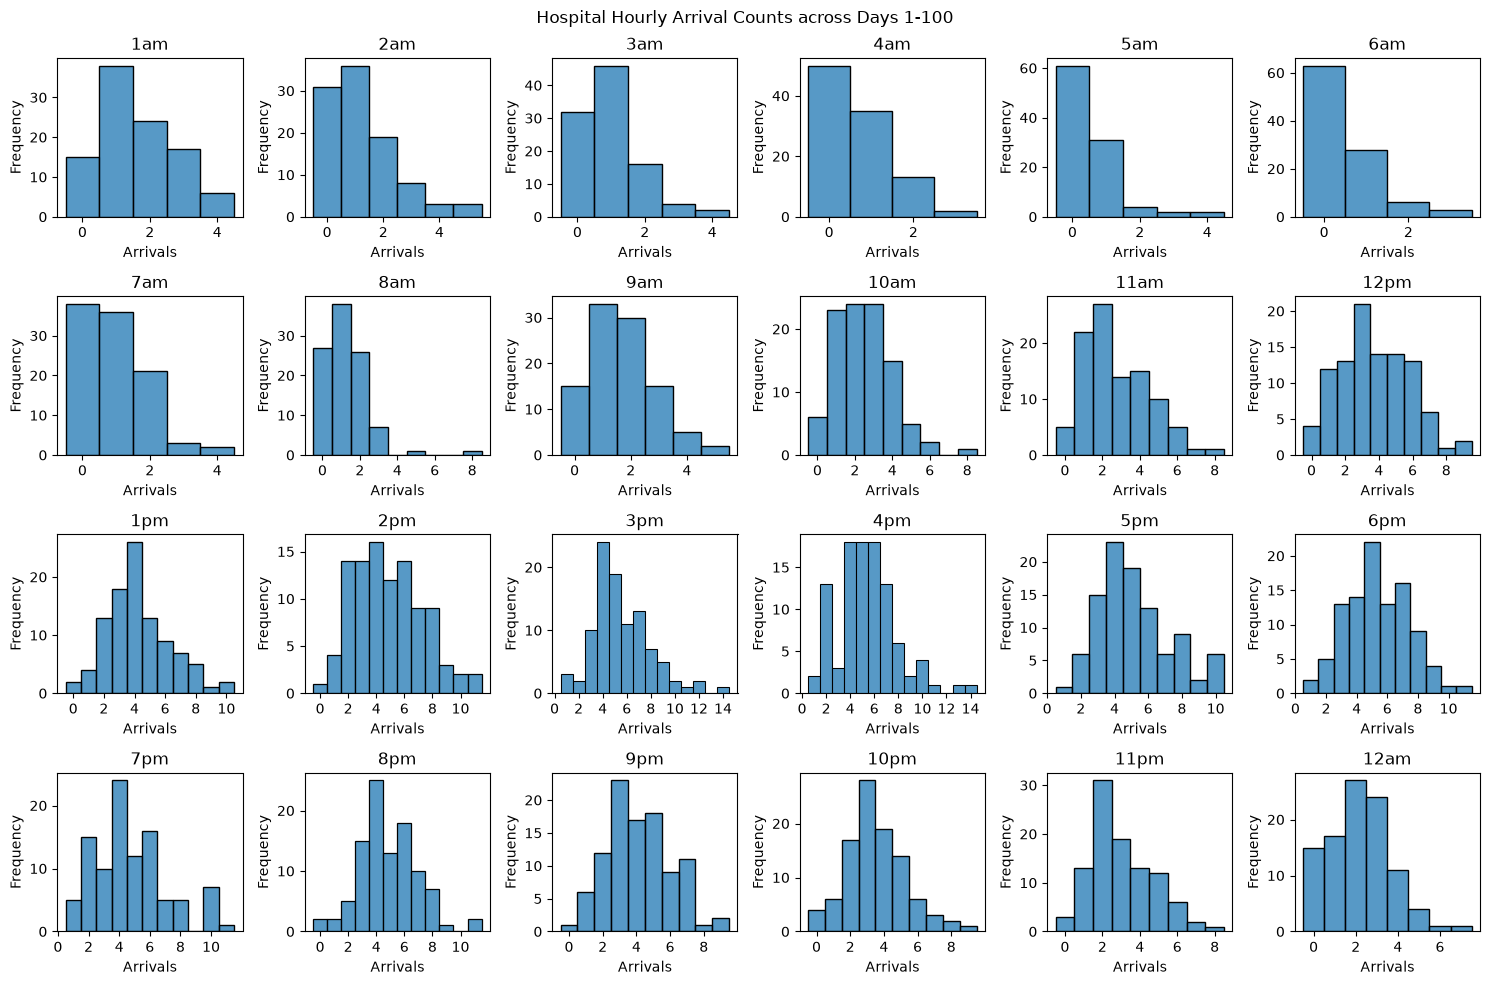

In [3]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Hospital Hourly Arrival Counts across Days 1-100")

axes = axes.flat
for i, col_name in enumerate(df_arrivals.columns):
    ax = axes[i]
    x = df_arrivals[col_name]
    sns.histplot(data=x, discrete=True, ax=ax)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, x.max() + 1, 2))

plt.tight_layout()
plt.show()

Visual observation of the data suggests that 24 independent Poisson distributions are a likely fit for each hour, since:
1. it seems reasonable to assume that arriving hospital cases are independent, and
2. the data appears to exhibit right skew, which Poisson exhibits.

both of which are good reasons to try fitting all arrival distributions with Poisson distributions, which are often used to model independent arrivals.

In [4]:
# Calculate Poisson MLEs (sample mean) for each hour
poisson_mles = df_arrivals.sum(axis=0)/df_arrivals.shape[0]
poisson_mles.name = "lambda"
display(poisson_mles)

1am     1.61
2am     1.25
3am     0.98
4am     0.67
5am     0.53
6am     0.49
7am     0.95
8am     1.24
9am     1.68
10am    2.48
11am    2.73
12pm    3.73
1pm     4.25
2pm     4.86
3pm     5.55
4pm     5.42
5pm     5.15
6pm     5.36
7pm     4.73
8pm     4.87
9pm     4.14
10pm    3.52
11pm    3.02
12am    2.20
Name: lambda, dtype: float64

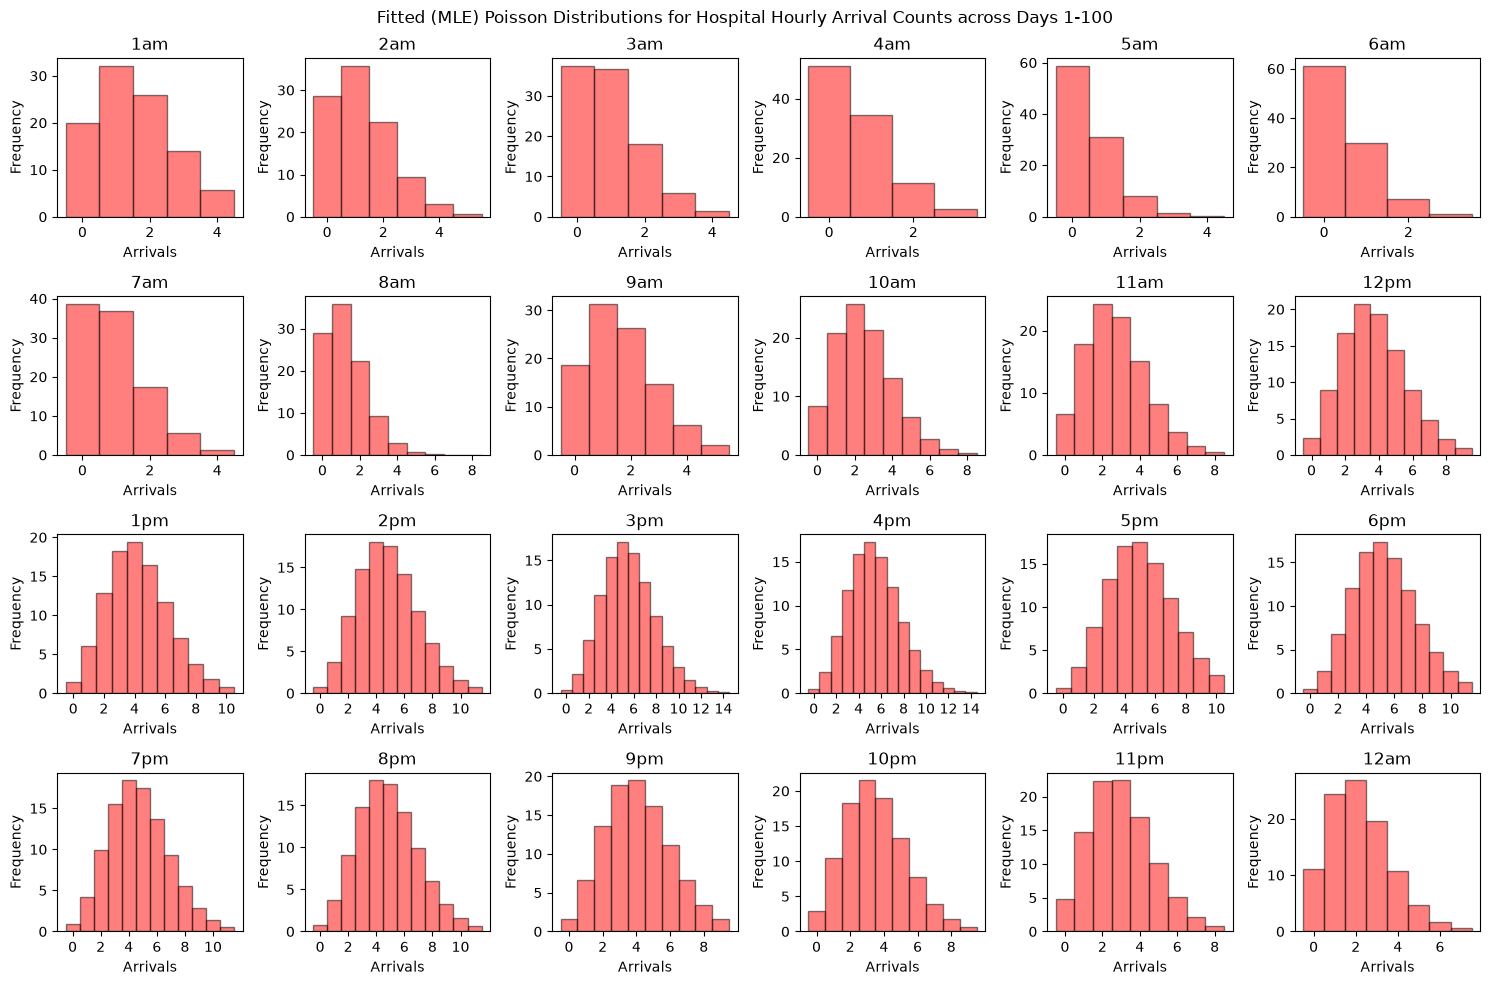

In [5]:
# Display scaled poisson distribution over visualization to quickly confirm if poisson is a good fit for modeling.
poisson_distributions = [stats.poisson(mu=rate) for rate in poisson_mles]

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Fitted (MLE) Poisson Distributions for Hospital Hourly Arrival Counts across Days 1-100")

for ax, col_name, poisson_dist in zip(axes.flat, df_arrivals.columns, poisson_distributions):
    x = np.arange(0, df_arrivals[col_name].max() + 1) # bins
    ax.bar(x, poisson_dist.pmf(x) * 100, color="red", alpha=0.5, edgecolor='black', width=1.0)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, df_arrivals[col_name].max() + 1, 2))

fig.tight_layout()

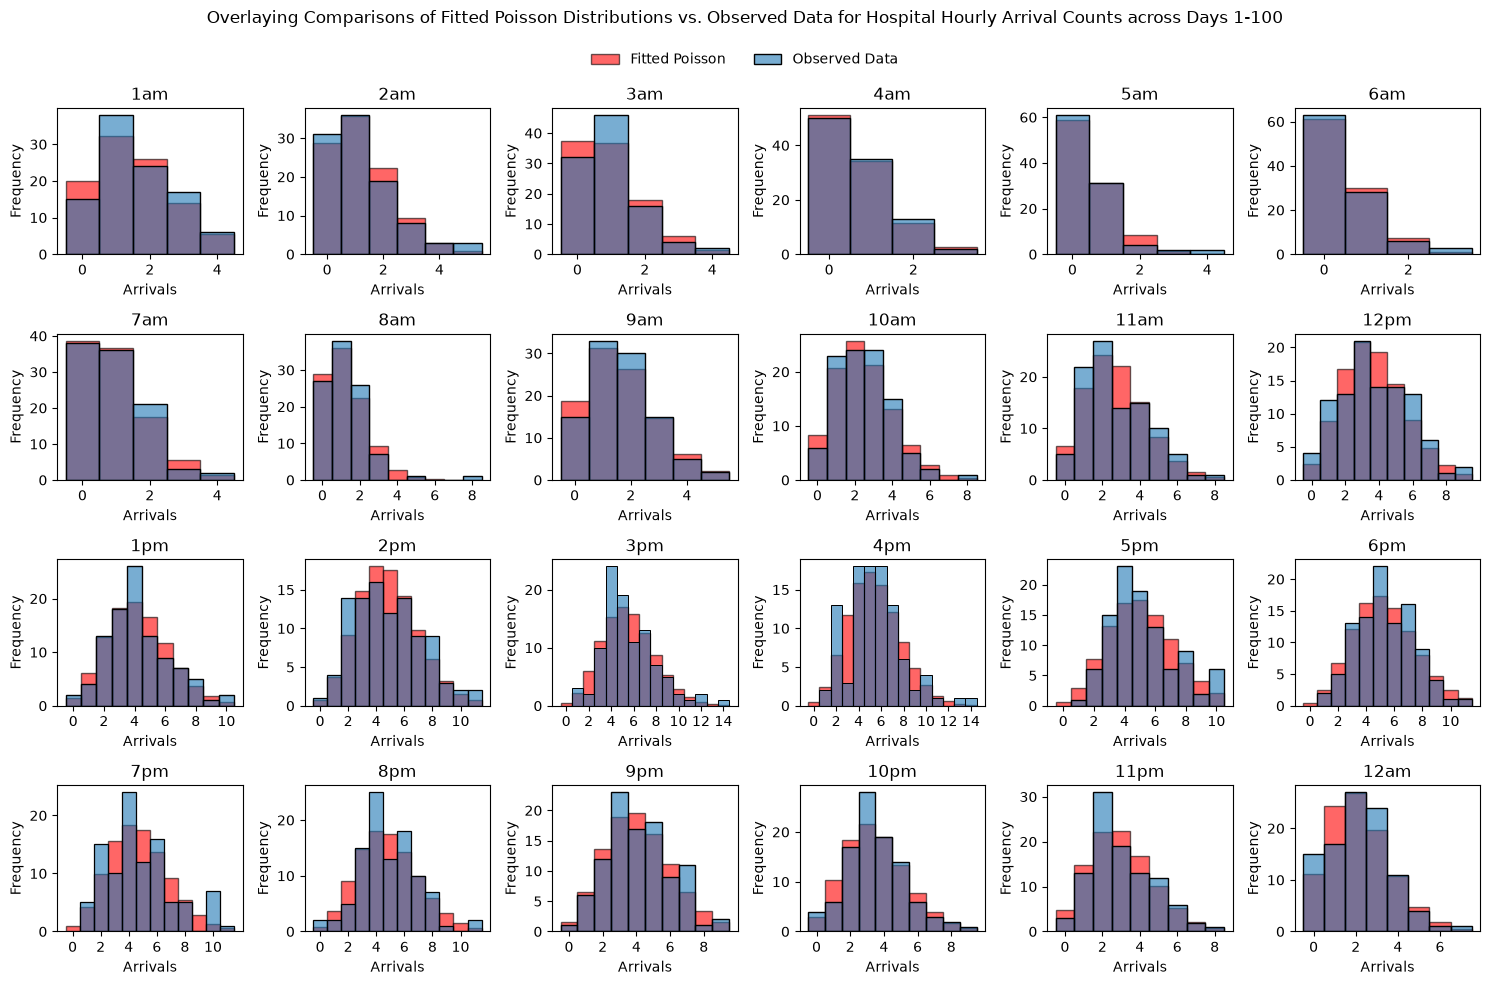

In [6]:
# Display the fitted Poisson distributions over the histograms of the actual data

n_days = len(df_arrivals)

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Overlaying Comparisons of Fitted Poisson Distributions vs. Observed Data for Hospital Hourly Arrival Counts across Days 1-100")

for ax, col_name, poisson_dist in zip(axes.flat, df_arrivals.columns, poisson_distributions):

    # Plot poisson
    x1 = np.arange(0, df_arrivals[col_name].max() + 1) # number of possible arrivals in a specific hour
    ax.bar(x1, poisson_dist.pmf(x1) * 100, color="red", alpha=0.6, edgecolor='black', width=1.0, label="Fitted Poisson")

    # Plot histogram
    x2 = df_arrivals[col_name]
    sns.histplot(data=x2, discrete=True, ax=ax, alpha=0.6, edgecolor='black', label="Observed Data")

    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, df_arrivals[col_name].max() + 1, 2))

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [7]:
# Run chi-squared test of observed arrival counts versus proposed Poisson distribution
results = {}
for col_name, poisson_dist in zip(df_arrivals.columns, poisson_distributions):
    # Get observed counts
    observed_counts = df_arrivals[col_name].value_counts().sort_index()
    
    # Get expected counts from Poisson distribution
    x = np.arange(0, df_arrivals[col_name].max() + 1)
    expected_counts = poisson_dist.pmf(x) * observed_counts.sum()

    # add the tail probability to the last bin to last bin so that the expected counts sum to the total number of observations
    expected_counts[-1] += poisson_dist.sf(x[-1]) * observed_counts.sum() 
    
    # Align observed and expected counts by realigning the observed counts to the expected counts index
    observed_counts_aligned = observed_counts.reindex(x, fill_value=0)
    
    # Perform chi-squared test, ddof=1 to account for the estimated parameter (lambda)
    chi2_stat, p_value = stats.chisquare(f_obs=observed_counts_aligned, f_exp=expected_counts, ddof=1) 
    
    results[col_name] = {
        'chi2_stat': chi2_stat,
        'p_value': p_value,
        'observed_counts': observed_counts_aligned,
        'expected_counts': expected_counts,
        'distn': poisson_dist
    }

# 95% confidence level, so alpha = 0.05
alpha = 0.05
H_0_rejected_count = 0
p_values_rejected_by_hour = pd.DataFrame(columns=["p_value"])
rejected_distributions = {}

for col_name, result in results.items():
    if result['p_value'] < alpha:
        H_0_rejected_count += 1
        p_values_rejected_by_hour.loc[col_name] = [result["p_value"]]
        rejected_distributions[col_name] = result['distn']

percent_H_0_rejected = H_0_rejected_count / len(results) * 100

# Poisson distribution is a good fit in most cases. 
print(f"Percentage of hours where H_0 is rejected: {percent_H_0_rejected:.2f}%")
print(f"Hours where H_0 is rejected, with p-values:")
display(p_values_rejected_by_hour)

Percentage of hours where H_0 is rejected: 16.67%
Hours where H_0 is rejected, with p-values:


,p_value
5am,6.379222e-04
8am,1.748852e-43
4pm,2.223076e-02
7pm,4.351399e-05


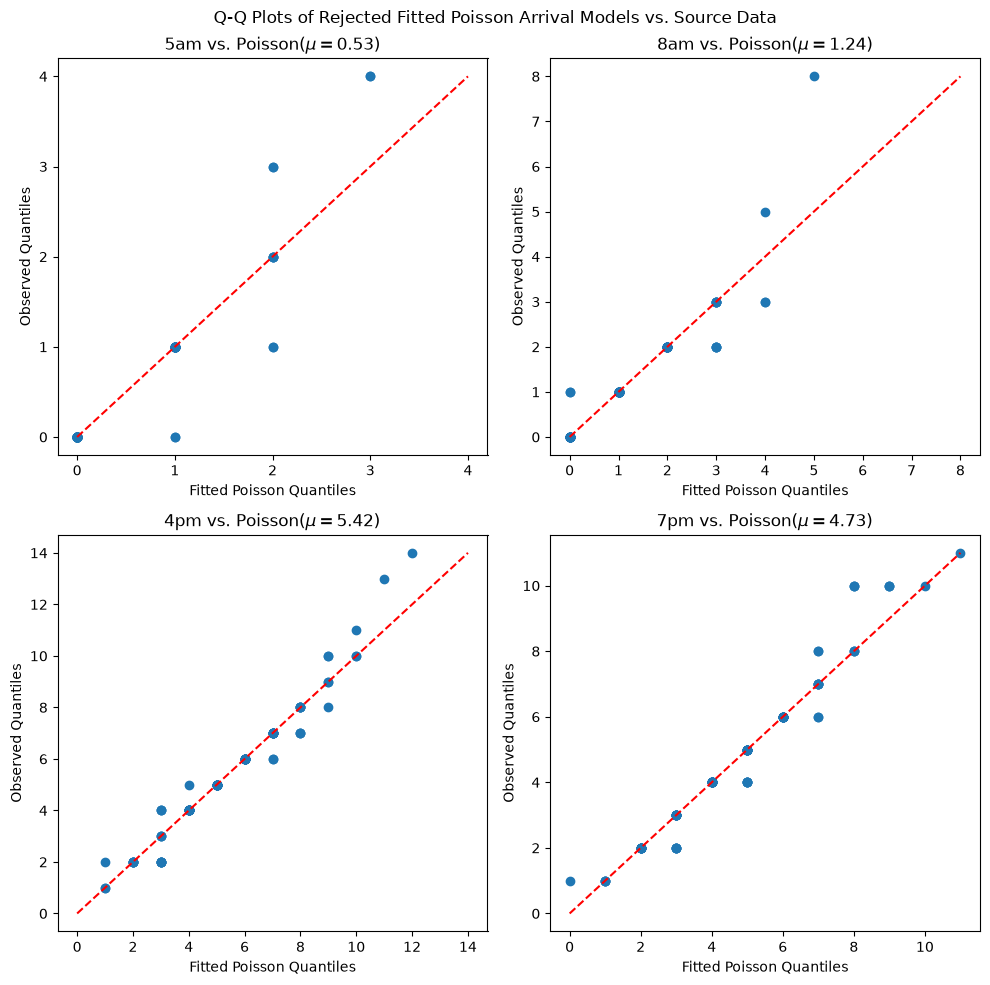

In [9]:
# Create Q-Q plots of the rejected hour Poisson distributions
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
fig.suptitle("Q-Q Plots of Rejected Fitted Poisson Arrival Models vs. Source Data")

for ax, (col_name, distn) in zip(axes.flat, rejected_distributions.items()):
    observed = df_arrivals[col_name]
    sorted_arrivals = np.sort(observed)
    n = observed.shape[0]
    probs = (np.arange(1, n + 1) - 0.5) / n
    fitted_poisson_quantiles = distn.ppf(probs)
    plot_max = max(fitted_poisson_quantiles.max(), observed.max())
    ax.scatter(fitted_poisson_quantiles, sorted_arrivals)
    ax.plot([0, plot_max], [0, plot_max], 'r--')
    ax.set_title(f"{col_name} vs. Poisson($\\mu={distn.mean()}$)")
    ax.set_xlabel('Fitted Poisson Quantiles')
    ax.set_ylabel('Observed Quantiles')
    ax.set_xticks(np.arange(0, plot_max + 1, 2 if plot_max >= 10 else 1))
    ax.set_yticks(np.arange(0, plot_max + 1, 2 if plot_max >= 10 else 1))

fig.tight_layout()
plt.show()

### Analysis of arrival modeling
Visually, the MLE Poisson distribution appears to largely fit most of the observed data, with a few histogram bins vastly differing. Our $\chi^2$ test conducted above largely agrees with this qualitative observation, showing that the MLE Poisson distribution is an acceptable fit for the majority (20/24) of the hours at the $\alpha=0.05$ confidence level.

We note that the $\chi^2$ test fails the following arrival periods at the $\alpha=0.05$ confidence level:
- 5 AM ($p=6.38\times10^{-4}$)
- 8 AM ($p=1.75\times10^{-43}$)
- 4 PM ($p=2.22\times10^{-2}$)
- 7 PM ($p=4.35\times10^{-5}$)

On visual inspection, the failing hours appear to be:
- noisy (4 PM and 7 PM), or
- have outliers that distort the test (5 AM, 8 PM, 7 PM).

Inspecting their corresponding Q-Q plots, the data for all 4 rejects largely follow the line in a staircase fashion. This is particularly evident at 4 PM and 7 PM, which have larger ranges (0-14 arrivals and 0-11 arrivals, respectively) and so the trend holds better with the presence of a few outliers, particularly near the higher observed arrival counts. On the other hand, the sparser Q-Q plots with smaller range for 5 AM and 8 AM are seen to be greatly affected by outliers, but still mostly follow the fitted line at lower counts.

Ultimately, we believe that, bar these discrepancies, an all-Poisson approach across all 24 hours is still appropriate for our input modeling.

### Visualizing and modeling service times

In [10]:
# Read treatment (service) time data. Use the ID column (idx 0) as the index.
df_treatment_raw = pd.read_csv("./data/Data_TreatmentTimes.csv", index_col=0)
df_treatment_raw = df_treatment_raw.rename(columns={"Treatment Time (Days)": "TreatmentTime"})
display(df_treatment_raw.head(5))
display(df_treatment_raw.shape)
print(df_treatment_raw["Specialty"].unique())

,TreatmentTime,Specialty
ID,,
0,4.640229,Ortho
1,0.770322,Renal
2,1.911212,Card
3,4.199311,Respi
4,2.527663,Gastro_Endo


(18565, 2)

<StringArray>
['Ortho', 'Renal', 'Card', 'Respi', 'Gastro_Endo']
Length: 5, dtype: str


In [11]:
# Group treatment time data by specialty.
# We assume that the treatment time distribution for a given specialty is the same across all wards under that specialty.
# (We are not given information about service times in each ward.)
df_treatment_by_specialty = df_treatment_raw.groupby(["Specialty"])
display(df_treatment_by_specialty.describe())

TreatmentTime                                              \
                    count      mean       std           min       25%   
Specialty                                                               
Card               4321.0  2.884995  3.515021  5.928158e-02  0.926157   
Gastro_Endo        3254.0  3.375186  3.639022  6.806160e-04  0.815995   
Ortho              3425.0  5.490906  5.491733  3.238330e-04  1.549496   
Renal              3244.0  4.823262  6.828324  2.105476e-07  0.517170   
Respi              4321.0  3.296486  5.696918  4.035753e-02  0.782429   

                                             
                  50%       75%         max  
Specialty                                    
Card         1.774205  3.454252   42.392131  
Gastro_Endo  2.188181  4.703748   28.626801  
Ortho        3.861794  7.595541   52.501056  
Renal        2.228971  6.244268   59.849193  
Respi        1.747665  3.666749  143.763709

In [12]:
# Peek the grouping
for i, (group_name, df_group) in enumerate(df_treatment_by_specialty):
    display(group_name[0])
    display(df_group.head(5))

'Card'

,TreatmentTime,Specialty
ID,,
2,1.911212,Card
5,2.076513,Card
6,1.862886,Card
14,1.343026,Card
17,5.331829,Card


'Gastro_Endo'

,TreatmentTime,Specialty
ID,,
4,2.527663,Gastro_Endo
18,2.758086,Gastro_Endo
27,10.760506,Gastro_Endo
44,0.495989,Gastro_Endo
47,10.935222,Gastro_Endo


'Ortho'

,TreatmentTime,Specialty
ID,,
0,4.640229,Ortho
15,0.653278,Ortho
20,1.716359,Ortho
24,0.549169,Ortho
25,9.000257,Ortho


'Renal'

,TreatmentTime,Specialty
ID,,
1,0.770322,Renal
7,0.001040,Renal
10,11.152471,Renal
11,3.017819,Renal
12,2.317516,Renal


'Respi'

,TreatmentTime,Specialty
ID,,
3,4.199311,Respi
8,0.213762,Respi
9,0.271861,Respi
13,1.609639,Respi
16,9.681560,Respi


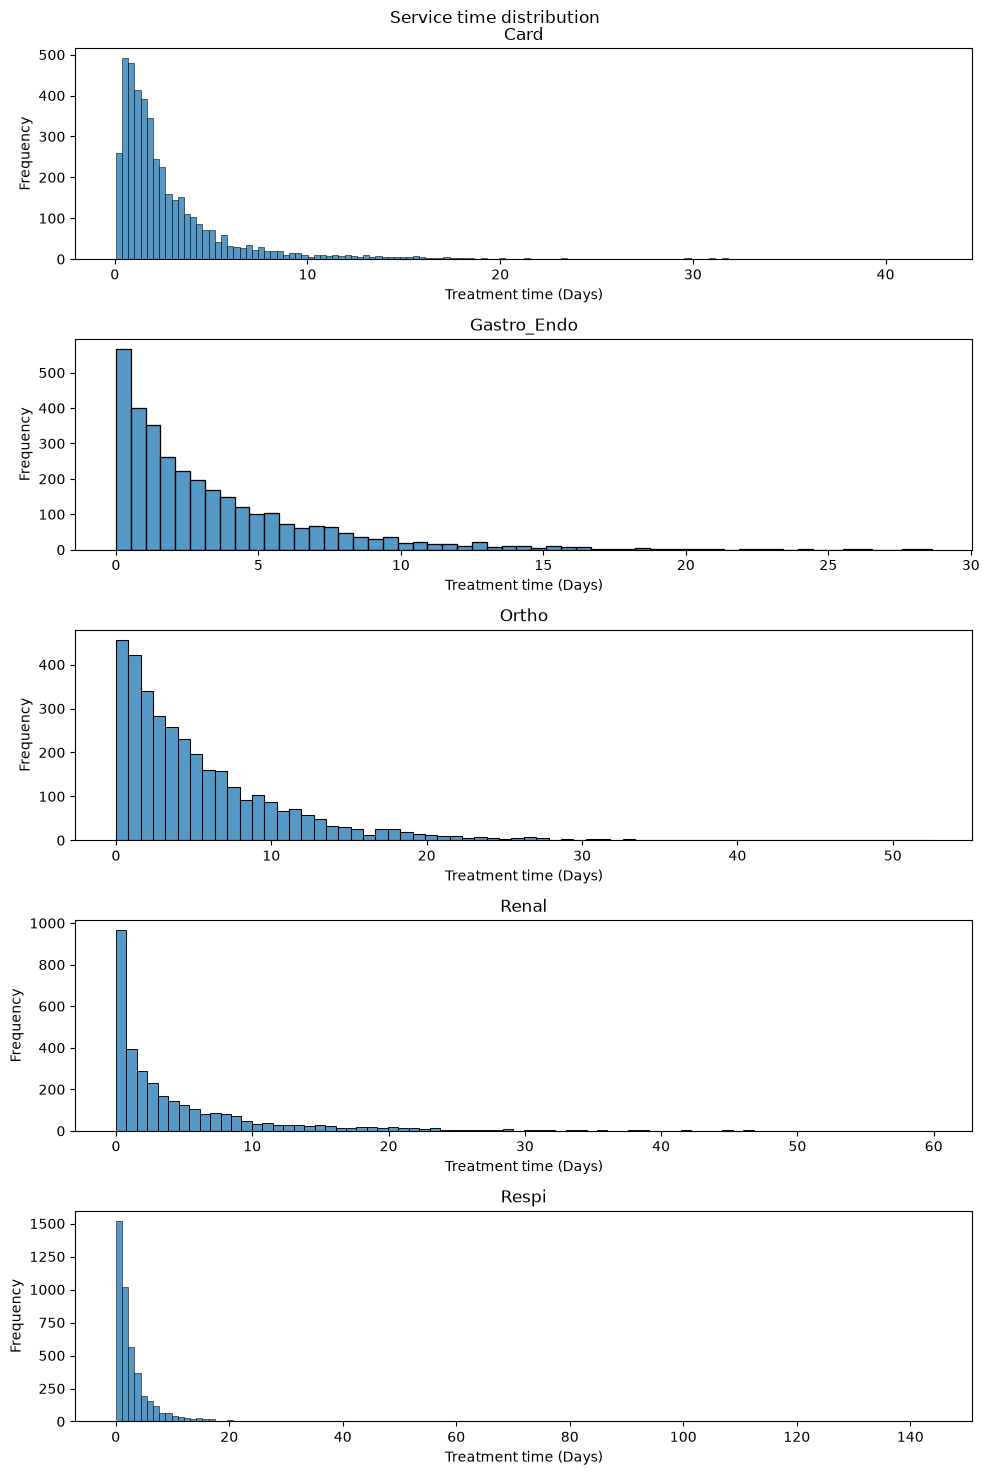

In [13]:
# Visualize treatment time data by speciality in histograms. (Preliminary.)
fig, axes = plt.subplots(5, 1, figsize=(10, 15))
fig.suptitle("Service time distribution")

for i, (group_name, df_group) in enumerate(df_treatment_by_specialty):
    ax = axes.flat[i]
    sns.histplot(data=df_group["TreatmentTime"], ax=ax)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Treatment time (Days)")
    ax.set_title(group_name[0])

for ax in axes.flat[i+1:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Compare gamma, exponential, and lognormal distributions

Visually observing the above preliminary histograms, we note that the specialities without a specified treatment time distribution (Cardiology, Gastroenterology-Endocrine, Orthopedic, Renal Disease, and Respiratory) mostly follow a power law-like distribution, with the Cardiology histogram exhibiting a dip left to the modal bin. Therefore, we guess that each of the remaining specialities can be best modeled by one of the following distributions:
- Gamma,
- Exponential, or
- Lognormal

In [14]:
# MLEs for gamma distribution
gamma_mles = {}
for group_name, df_group in df_treatment_by_specialty:
    # Fit gamma distribution to the treatment time data for this specialty
    shape, loc, scale = stats.gamma.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    gamma_mles[group_name[0]] = (shape, loc, scale)

# MLEs for exponential distribution
exponential_mles = {}
for group_name, df_group in df_treatment_by_specialty:
    # Fit exponential distribution to the treatment time data for this specialty
    loc, scale = stats.expon.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    exponential_mles[group_name[0]] = (loc, scale)

# MLEs for lognormal distribution
lognormal_mles = {}
for group_name, df_group in df_treatment_by_specialty:  
    # Fit lognormal distribution to the treatment time data for this specialty
    shape, loc, scale = stats.lognorm.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    lognormal_mles[group_name[0]] = (shape, loc, scale)

gamma_mles


{'Card': (1.170541810496347, 0, np.float64(2.4646661432045325)),
 'Gastro_Endo': (0.8466957605437156, 0, np.float64(3.9863037301331734)),
 'Ortho': (1.0147367271709278, 0, np.float64(5.411163405986773)),
 'Renal': (0.5121985074122511, 0, np.float64(9.416782989343686)),
 'Respi': (0.8973004097766168, 0, np.float64(3.6737819516631847))}

In [15]:
# Chi-squared test for goodness of fit for each distribution and each specialty
# e.g., Orthopedic and lognormal, orthopedic and gamma, orthopedic and exponential, etc.

gamma_results = {}
exponential_results = {}
lognormal_results = {}

# Integers represent ddof: 2 parameters being estimated for gamma and lognormal, 1 parameter for exponential
models = [("Gamma", stats.gamma, gamma_mles, 2, gamma_results),
          ("Exponential", stats.expon, exponential_mles, 1, exponential_results),
          ("Lognormal", stats.lognorm, lognormal_mles, 2, lognormal_results)]

for group_name, df_group in df_treatment_by_specialty:
    specialty = group_name[0] 
    times = df_group["TreatmentTime"]
    n = len(times) # Number of observations for this specialty

    # Obtain appropriate bin number. Use up to 10 bins with at least 5 expected observations each.
    n_bins = max(1, min(10, n // 5))

    # Quantiles of the fitted distribution will be used to create bins for the chi-squared test.
    quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]

    for _, distribution, mles, ddof, results in models:
        # extract MLEs for the current specialty and fit the distribution
        fitted_dist = distribution(*mles[specialty]) 

        bin_edges = np.r_[-np.inf, fitted_dist.ppf(quantiles), np.inf]

        observed_counts, _ = np.histogram(times, bins=bin_edges)

        # difference in CDF values at bin edges gives the expected proportion of observations 
        # in each bin, multiplied by n gives expected counts
        expected_counts = n * np.diff(fitted_dist.cdf(bin_edges)) 
        chi2_stat, p_value = stats.chisquare(f_obs=observed_counts, f_exp=expected_counts, ddof=ddof)

        # Store results for this specialty and distribution
        results[specialty] = {"chi2_stat": chi2_stat,
                              "p_value": p_value,
                              "observed_counts": observed_counts,
                              "expected_counts": expected_counts,
                              "bin_edges": bin_edges,
                              "mles": mles[specialty]}

good_fits = pd.DataFrame(columns=["p", "shape", "loc", "scale"]).rename_axis("distribution_specialty")
# Conclusions based on p-values
k = 0
for name, _, _, _, results in models:
    p_values = [result["p_value"] for result in results.values()]
    num_tested = sum(np.isfinite(p) for p in p_values)
    num_rejections = sum(p < 0.05 for p in p_values)

    # Find and append specialties that fit well to a distribution (p-value >= 0.05)
    for specialty, result in results.items():
        if result["p_value"] >= 0.05:
            mles = result["mles"]
            mle_shape = mles[0] if len(mles) == 3 else None
            mle_loc = mles[-2]
            mle_scale = mles[-1]
            good_fits.loc[f"{name}-{specialty}"] = [result["p_value"], mle_shape, mle_loc, mle_scale]
            k += 1

    print(f"At the 5% level, rejected the {name} fit for {num_rejections} of {num_tested} tested specialties.")

print("Table of distributions and specialities that pair well, with p-values and applicable MLEs:")
display(good_fits)

At the 5% level, rejected the Gamma fit for 2 of 5 tested specialties.
At the 5% level, rejected the Exponential fit for 4 of 5 tested specialties.
At the 5% level, rejected the Lognormal fit for 3 of 5 tested specialties.
Table of distributions and specialities that pair well, with p-values and applicable MLEs:


,p,shape,loc,scale
distribution_specialty,,,,
Gamma-Gastro_Endo,0.886080,0.846696,0.0,3.986304
Gamma-Ortho,0.321779,1.014737,0.0,5.411163
Gamma-Renal,0.674105,0.512199,0.0,9.416783
Exponential-Ortho,0.379521,NaN,0.0,5.490906
Lognormal-Card,0.175105,0.986174,0.0,1.777177
Lognormal-Respi,0.280705,1.133348,0.0,1.717883


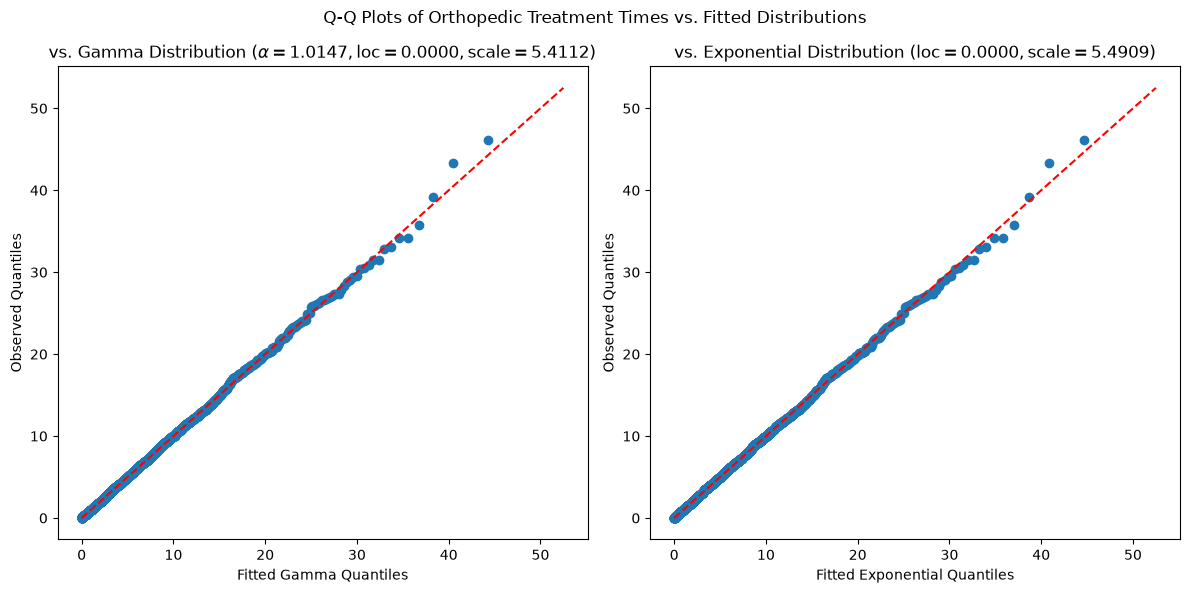

In [16]:
# Observing whether Exponential or Gamma distribution is better for Orthopedic treatment times using QQ plot

# fitted quantiles on x-axis, observed quantiles on y-axis
for specialty, df_group in df_treatment_by_specialty:

    # ("Ortho,") is returned when grouping by specialty, so we need to check if "Ortho" is in the tuple
    if "Ortho" in specialty:

        # Dictionaries expect "Ortho" for index
        specialty = "Ortho"
        times = df_group["TreatmentTime"]
        n = len(times)

        # Generate quantiles for the fitted distributions
        quantiles = np.linspace(0, 1, n)
        
        # Fit distributions
        gamma_params = gamma_mles[specialty]
        exponential_params = exponential_mles[specialty]
        fitted_gamma_quantiles = stats.gamma.ppf(quantiles, *gamma_params)
        fitted_exponential_quantiles = stats.expon.ppf(quantiles, *exponential_params)

        # Sort observed data for QQ plot
        sorted_times = np.sort(times)

        # Create Q-Q plots
        plt.figure(figsize=(12, 6))
        plt.suptitle("Q-Q Plots of Orthopedic Treatment Times vs. Fitted Distributions")

        # Gamma Q-Q plot
        plt.subplot(1, 2, 1)
        plt.scatter(fitted_gamma_quantiles, sorted_times)
        plt.plot([sorted_times.min(), sorted_times.max()], [sorted_times.min(), sorted_times.max()], 'r--')
        plt.title(f"vs. Gamma Distribution ($\\alpha={gamma_params[0]:0.4f},\\text{{loc}}={gamma_params[1]:0.4f},\\text{{scale}}={gamma_params[2]:0.4f}$)")
        plt.xlabel('Fitted Gamma Quantiles')
        plt.ylabel('Observed Quantiles')

        # Exponential Q-Q plot
        plt.subplot(1, 2, 2)
        plt.scatter(fitted_exponential_quantiles, sorted_times)
        plt.plot([sorted_times.min(), sorted_times.max()], [sorted_times.min(), sorted_times.max()], 'r--')
        plt.title(f"vs. Exponential Distribution ($\\text{{loc}}={exponential_params[0]:0.4f},\\text{{scale}}={exponential_params[1]:0.4f}$)")
        plt.xlabel('Fitted Exponential Quantiles')
        plt.ylabel('Observed Quantiles')

        plt.tight_layout()
        plt.show()

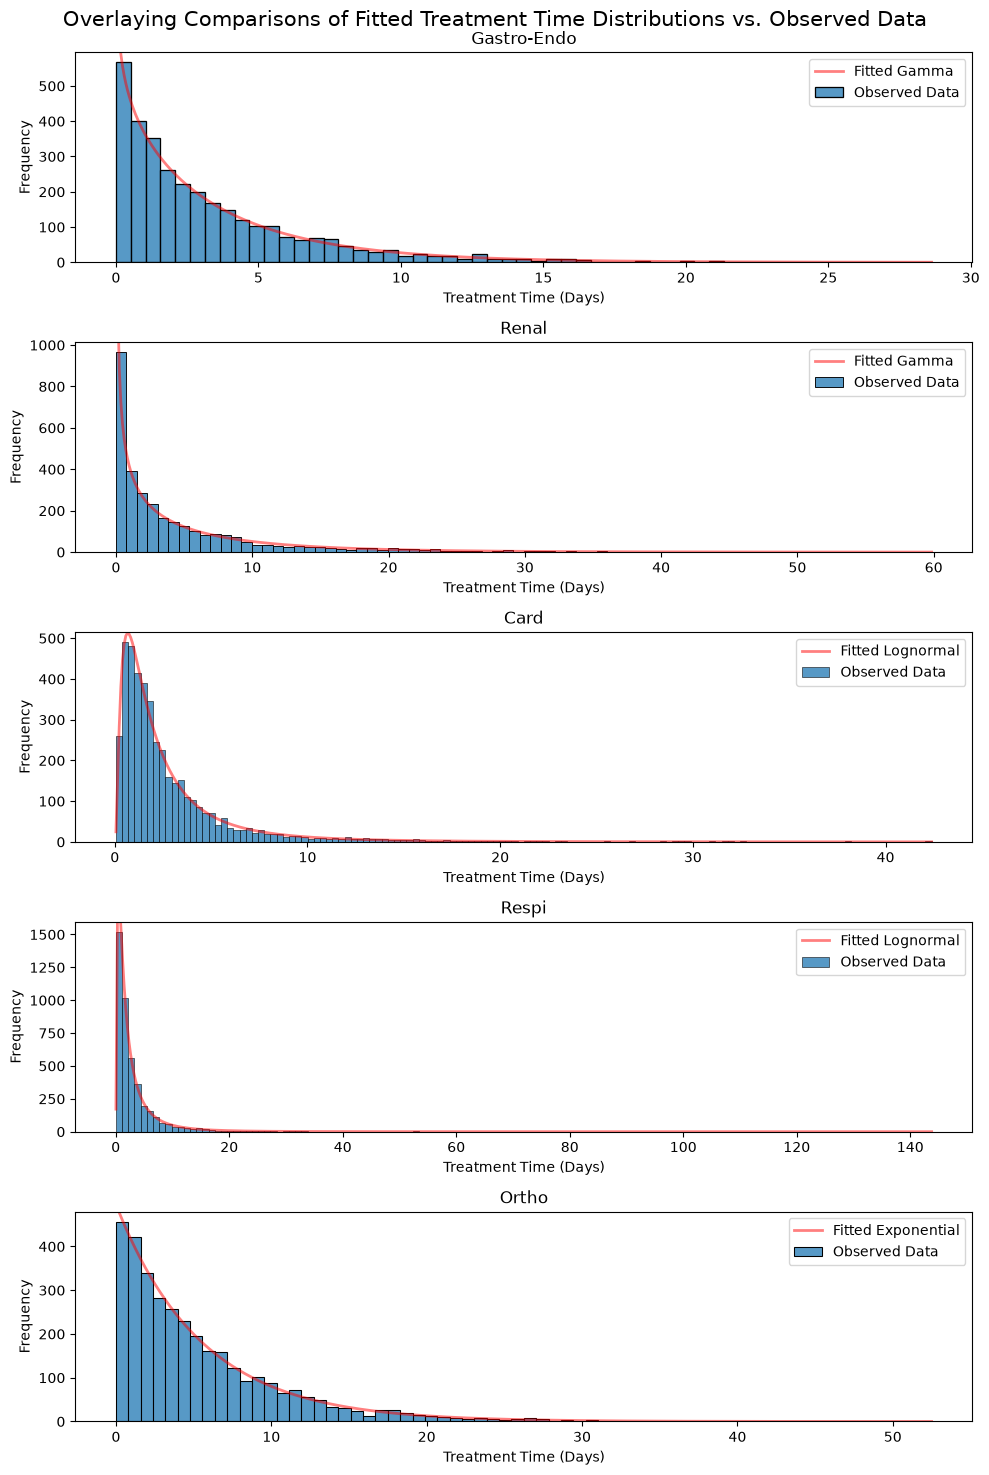

In [17]:
# Define treatment specialties and fitted distributions
comparisons = [
    ("Gastro_Endo", "Gamma", "Gamma-Gastro_Endo"),
    ("Renal", "Gamma", "Gamma-Renal"),
    ("Card", "Lognormal", "Lognormal-Card"),
    ("Respi", "Lognormal", "Lognormal-Respi"),
    ("Ortho", "Exponential", "Exponential-Ortho")
]

# Use the same grouped data as the original histograms
grouped_data = {(name[0] if isinstance(name, tuple) else name): df_group["TreatmentTime"].dropna() for name, df_group in df_treatment_by_specialty}

fig, axes = plt.subplots(5, 1, figsize=(10, 15))
fig.suptitle("Overlaying Comparisons of Fitted Treatment Time Distributions vs. Observed Data", fontsize=15)

for ax, (specialty, dist_type, mle_key) in zip(axes.flat, comparisons):

    # Get original treatment-time data and fitted MLE parameters
    data = grouped_data[specialty]
    params = good_fits.loc[mle_key]

    # Define fitted distributions
    if dist_type == "Gamma":
        fitted_dist = stats.gamma(a=params["shape"], loc=params["loc"], scale=params["scale"])
    elif dist_type == "Lognormal":
        fitted_dist = stats.lognorm(s=params["shape"], loc=params["loc"], scale=params["scale"])
    else:
        fitted_dist = stats.expon(loc=params["loc"], scale=params["scale"])

    # Plot original histogram
    bins = np.histogram_bin_edges(data, bins="auto")
    sns.histplot(data=data, bins=bins, stat="count", ax=ax, edgecolor="black", label="Observed Data")
    hist_ylim = ax.get_ylim() # for consistent scaling

    # Overlay fitted PDF scaled to histogram frequencies
    x = np.linspace(max(0.001, bins[0]), bins[-1], 500)
    bin_width = bins[1] - bins[0]
    ax.plot(x, fitted_dist.pdf(x) * len(data) * bin_width, color="red", alpha=0.5, linewidth=2, label=f"Fitted {dist_type}")
    ax.set_ylim(hist_ylim) # limit y to preserve scaling 

    ax.set_title("Gastro-Endo" if specialty == "Gastro_Endo" else specialty)
    ax.set_xlabel("Treatment Time (Days)")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

### Analysis of treatment modeling

Visually, the histograms suggest Gamma, Exponential, and Lognormal distributions as possible candidates to model the treatment (service) times for Cardiology, Renal Disease, Respiratory, Orthopedic and Gastroenterology-Endocrine specialties. 

After calculating the MLE parameters for each distribution and performing a $\chi^2$ goodness-of-fit test for each distribution-specialty pair, we observe at the $\alpha=0.05$ confidence level:
- The Gamma distribution is a good fit for the Gastro-Endo ($p=0.886$), Orthopedic ($p=0.322$), and Renal Disease ($p=0.674$) treatment times.
- The Exponential distribution is a good fit for the Orthopedic ($p=0.380$) treatment time.
- The Lognormal distribution is a good fit for the Cardiology ($p=0.175$) and Respiratory ($p=0.281$) treatment times.

The Q-Q plots for comparing Gamma and Exponential fits to Orthopedic treatment times show nearly identical agreement with the observed quantiles, including in the upper tail. Hence, we choose the Exponential distribution to approximate Orthopedic treatment times because it gives essentially the same fit with one fewer parameter, which can provide more stable predictions between different samples. For the remaining specialities, we will use the Gamma distribution for approximating Gastroenterology-Endocrine and Renal Disease treatment times, and the Lognormal distribution for approximating Cardiology and Respiratory treatment times.


## Deliverable 3.2: Base model

In [18]:
# Time unit helper functions
def days_to_hours(d: float) -> float:
    return d * 24


def days_to_minutes(d: float) -> float:
    return d * 24 * 60


def hours_to_days(h: float) -> float:
    return h / 24


def hours_to_minutes(h: float) -> float:
    return h * 60


def minutes_to_days(m: float) -> float:
    return m / 60 / 24


def minutes_to_hours(m: float) -> float:
    return m / 60


def fraction_of_day(d: float) -> float:
    return d % 1


def hour_of_day(h: float) -> float:
    return h % 24


def minute_of_day(m: float) -> float:
    return m % (24 * 60)


def next_day(d: float) -> float:
    return math.ceil(d)


def next_day_hour(h: float) -> float:
    return days_to_hours(next_day(hours_to_days(h)))


def next_day_minute(m: float) -> float:
    return days_to_minutes(next_day(minutes_to_days(m)))

### Service and arrival input models

In [19]:
# Align CSV (starts at 1AM, ends at 12AM) with simulation times (start at 12AM, ends at 11PM)
# Values are shifted over one and the last value (at 12AM) is wrapped around
df_arrival_mles = poisson_mles.rename_axis("hour").to_frame(name="lambda")
hour_labels = (['12am'] + [f'{h}am' for h in range(1,12)] + ['12pm'] + [f'{h}pm' for h in range(1,12)])
hourly_rates = df_arrival_mles.loc[hour_labels, 'lambda'].to_numpy()
display(hourly_rates)

array([2.2 , 1.61, 1.25, 0.98, 0.67, 0.53, 0.49, 0.95, 1.24, 1.68, 2.48,
       2.73, 3.73, 4.25, 4.86, 5.55, 5.42, 5.15, 5.36, 4.73, 4.87, 4.14,
       3.52, 3.02])

In [20]:
df_treatment_mles = good_fits
display(df_treatment_mles)

,p,shape,loc,scale
distribution_specialty,,,,
Gamma-Gastro_Endo,0.886080,0.846696,0.0,3.986304
Gamma-Ortho,0.321779,1.014737,0.0,5.411163
Gamma-Renal,0.674105,0.512199,0.0,9.416783
Exponential-Ortho,0.379521,NaN,0.0,5.490906
Lognormal-Card,0.175105,0.986174,0.0,1.777177
Lognormal-Respi,0.280705,1.133348,0.0,1.717883


### Define TreatmentType, Ward, Hospital

In [21]:
class TreatmentType(Enum):
    SURG = ("Surg", 0.22, stats.expon(scale=1/0.4237))
    CARD = ("Card", 0.18, stats.lognorm(s=df_treatment_mles.loc["Lognormal-Card"]["shape"], scale=df_treatment_mles.loc["Lognormal-Card"]["scale"]))
    GEN_MED = ("Gen Med", 0.16, stats.lognorm(scale=np.exp(0.921), s=0.949))
    ORTHO = ("Ortho", 0.14, stats.expon(scale=df_treatment_mles.loc["Exponential-Ortho"]["scale"]))
    GASTRO_ENDO = ("Gastro-Endo", 0.08, stats.gamma(a=df_treatment_mles.loc["Gamma-Gastro_Endo"]["shape"], scale=df_treatment_mles.loc["Gamma-Gastro_Endo"]["scale"]))
    ONCO = ("Onco", 0.07, stats.gamma(a=0.612, scale=9.689))
    NEURO = ("Neuro", 0.06, stats.lognorm(scale=np.exp(0.53), s=1.133))
    RENAL = ("Renal", 0.05, stats.gamma(a=df_treatment_mles.loc["Gamma-Renal"]["shape"], scale=df_treatment_mles.loc["Gamma-Renal"]["scale"]))
    RESPI = ("Respi", 0.04, stats.lognorm(s=df_treatment_mles.loc["Lognormal-Respi"]["shape"], scale=df_treatment_mles.loc["Lognormal-Respi"]["scale"]))

    def __new__(cls, name: str, proportion: float, treatment_time_rv):
        obj = object.__new__(cls)
        obj._value_ = name
        obj.type_name = name
        obj.proportion = proportion
        obj.treatment_time_rv = treatment_time_rv
        return obj

    @classmethod
    def list(cls):
        return [t for t in cls]

    @classmethod
    def weightings(cls):
        return [t.proportion for t in cls]

    @classmethod
    def random_type(cls):
        return rng_specialty.choices(cls.list(), weights=cls.weightings())[0]

# Optimize the code since SciPy's .ppf() is computationally expensive
# This prepares a direct sampler for each specialty once instead of calling the inverse CDF each time
def make_treatment_sampler(rv):
    # The model defines all treatment distributions with loc=0.
    scale = rv.kwds["scale"]

    if rv.dist.name == "expon":
        # partial allows sampler to be setup once per specialty 
        return partial(rng_treatment.expovariate, 1 / scale)
    if rv.dist.name == "lognorm":
        return partial(rng_treatment.lognormvariate, math.log(scale), rv.kwds["s"])
    if rv.dist.name == "gamma":
        return partial(rng_treatment.gammavariate, rv.kwds["a"], scale)
    raise ValueError(f"Unsupported treatment distribution: {rv.dist.name}")
TREATMENT_SAMPLERS = {
    specialty: make_treatment_sampler(specialty.treatment_time_rv)
    for specialty in TreatmentType
}

class Ward(object):

    def __init__(self, env: simpy.Environment,
                 ward_id: int,
                 treatment_type: set[TreatmentType],
                 bed_count: int,
                 physician_count: int,
                 physician_discharge_time: float,
                 physician_discharge_interval: tuple[float, float], # [3PM, 5PM]
                 cleaner_time_rv,
                 treatment_multipliers_by_type = {}):
        self.env = env
        self.ward_id = ward_id
        self.treatment_type = treatment_type
        self.physician_discharge_time = physician_discharge_time
        self.physician_discharge_interval = physician_discharge_interval
        self.cleaner_time_rv = cleaner_time_rv

        # Scenario 3.3.1: multiplier applied to a patient's sampled treatment time in this ward (e.g. {ONCO: 1.05})
        self.treatment_multipliers_by_type = treatment_multipliers_by_type

        # Ward resources
        self.beds = simpy.Resource(env, capacity=bed_count)
        self.physicians = simpy.Resource(env, physician_count)

        self.num_occupied_beds = 0 # patient in bed
        self.num_unavailable_beds = 0 # beds occupied or being cleaned
        self.queue_log = [(env.now, 0)]
        self.occupied_bed_log = [(env.now, 0)]
        self.unavailable_bed_log = [(env.now, 0)]
        self.patient_records = []

    # LOGGING METHODS
    def log_queue(self):
        return self.queue_log.append((self.env.now, len(self.beds.queue)))

    def log_occupied_beds(self):
        return self.occupied_bed_log.append((self.env.now, self.num_occupied_beds))
    
    def log_unavailable_beds(self):
        return self.unavailable_bed_log.append((self.env.now, self.num_unavailable_beds))

    # HELPER FOR METRICS
    def time_weighted_average(self, log, start=0, end=None):
        if end is None:
            end = self.env.now

        if not 0 <= start < end <= self.env.now:
            raise ValueError('Invalid observation period')

        if not log or start < log[0][0]:
            raise ValueError('The log must cover the observation period')
        
        total = 0
        for i in range(len(log)):
            # value represents queue length
            current_time, value = log[i]
            if i + 1 < len(log):
                next_time = log[i+1][0]
            else:
                next_time = end

            # only consider observations within specified time period
            interval_start = max(current_time, start)
            interval_end = min(next_time, end)

            if interval_end > interval_start:
                total += value * (interval_end-interval_start)
            
        return total / (end-start)

    def get_waiting_records(self, start=0, end=None):
        if end is None:
            end = self.env.now
        if not 0 <= start < end <= self.env.now:
            raise ValueError('Invalid observation period')
        selected_records = [r for r in self.patient_records if start <= r['request_time'] < end]
        for r in selected_records:
            if r['wait_minutes'] is None:
                raise ValueError('Some selected patients are still waiting. Continue simulation until there are all admitted')
        return selected_records
    
    # METRIC METHODS
    def average_wait_times(self, start=0, end=None, nine_to_twelve=False, by_speciality=False):
        records = self.get_waiting_records(start, end)
        
        if nine_to_twelve:
            records = [r for r in records if 9*60 <= r['request_time'] % (24*60) < 12*60]
        
        if by_speciality:
            averages = {}

            for specialty in TreatmentType:
                waits = [r['wait_minutes'] for r in records if r['specialty']==specialty]
                averages[specialty] = np.mean(waits) if waits else float('nan')
            return averages
        return np.mean([r['wait_minutes'] for r in records]) if records else float('nan')
     
    def average_queue_length(self, start=0, end=None):
        return self.time_weighted_average(self.queue_log, start, end)

    def average_bed_utilization(self, start=0, end=None):
        average_occupied = self.time_weighted_average(self.occupied_bed_log, start, end)
        return average_occupied / self.beds.capacity

    def average_bed_unavailability(self, start=0, end=None):
        average_unavailable = self.time_weighted_average(self.unavailable_bed_log, start, end)
        return average_unavailable / self.beds.capacity

    # HELPERS

    def get_treatment_time(self, treatment_type, base_treatment_days) -> float:
        # base_treatment_days is sampled once per patient at arrival (CRN); sampling Gamma(shape, c*scale)
        # is no different than just scaling a Gamma sample by c. The 5% increase keeps the same random draw.
        return base_treatment_days * self.treatment_multipliers_by_type.get(treatment_type, 1.0)

    def get_discharge_time(self) -> float:
        return self.physician_discharge_time

    def get_cleaning_time(self) -> float:
        return rng_cleaning.triangular(*self.cleaner_time_rv) # unpack parameters as (low, high, mode)

    def get_discharge_interval(self) -> tuple[float, float]:
        return self.physician_discharge_interval

    def get_free_beds(self) -> int:
        return self.beds.capacity - self.beds.count

    def get_queue_length(self) -> int:
        return len(self.beds.queue)


class Hospital(object):

    def __init__(self, env: simpy.Environment,
                 simulation_time: float,
                 ward_spec: list[tuple[int, set[TreatmentType], int, dict]],
                 physicians_per_ward: int,
                 physician_discharge_time: float,
                 physician_discharge_interval: tuple[float, float],
                 cleaner_time_rv):
        self.env = env
        self.simulation_time = simulation_time

        # Check that all wards are included in ward spec
        # CORRECTION: One ward can have multiple specialities. 
        # Allow ward 11 and 12 to appear in lookup lists for Surgery and Cardiology
        ward_types = {treatment_type for _, treatment_types, _, _ in ward_spec for treatment_type in treatment_types}
        all_types = set(TreatmentType.list())
        assert all_types.issubset(ward_types), f"Ward specification does not contain treatment types {all_types.difference(ward_types)}"

        # Hospital resources
        self.wards = [Ward(env=env,
                           ward_id=ward_id,
                           treatment_type=treatment_type,
                           bed_count=bed_count,
                           physician_count=physicians_per_ward,
                           physician_discharge_time=physician_discharge_time,
                           physician_discharge_interval=physician_discharge_interval,
                           cleaner_time_rv=cleaner_time_rv,
                           treatment_multipliers_by_type=treatment_rvs)
                      for ward_id, treatment_type, bed_count, treatment_rvs in ward_spec]
        self.wards_by_type: dict[TreatmentType, list[Ward]] = {treatment_type: [] for treatment_type in TreatmentType.list()}
        for ward in self.wards:
            for treatment_type in ward.treatment_type:
                self.wards_by_type[treatment_type].append(ward)

    def average_wait_times(self, start=0, end=None, nine_to_twelve=False, by_speciality=False, by_ward=True):
        if by_ward:
            return {ward.ward_id: ward.average_wait_times(start=start, end=end, nine_to_twelve=nine_to_twelve, by_speciality=by_speciality) for ward in self.wards}

        # pool patient records
        records = [r for ward in self.wards for r in ward.get_waiting_records(start, end)]

        if nine_to_twelve:
            records = [r for r in records if (9*60<= r['request_time'] % (24*60) < 12*60)]

        if by_speciality:
            averages = {}

            for specialty in TreatmentType:
                waits = [r['wait_minutes'] for r in records if r['specialty']==specialty]
                averages[specialty] = np.mean(waits) if waits else float('nan')
            return averages

        waits = [r['wait_minutes'] for r in records]
        return np.mean(waits) if waits else float('nan')

    def average_queue_length(self, start=0, end=None, by_ward=True):
        averages_by_ward = {ward.ward_id: ward.average_queue_length(start,end) for ward in self.wards}
        if by_ward:
            return averages_by_ward
        # average total number of patients across all wards
        return sum(averages_by_ward.values())

    def average_bed_utilization(self, start=0, end=None, by_ward=True):
        averages_by_ward = {ward.ward_id: ward.average_bed_utilization(start,end) for ward in self.wards}
        if by_ward:
            return averages_by_ward
        # hospital utilization is waited by ward bed capacity
        total_beds = sum(ward.beds.capacity for ward in self.wards)
        if not total_beds:
            return float('nan')
        weighted_average = sum(averages_by_ward[ward.ward_id]*ward.beds.capacity for ward in self.wards) / total_beds
        return weighted_average if total_beds else float('nan')

    def oncology_fraction_over_5_hours(self, start=0, end=None): # Only 1 ward has Onco
        records = [r for ward in self.wards for r in ward.get_waiting_records(start, end)]
        oncology_records = [r for r in records if r['specialty'] == TreatmentType.ONCO]
        if not oncology_records:
            return float('nan')

        count_over_5 = sum([1 for r in oncology_records if r['wait_minutes'] > 5*60])
        return count_over_5 / len(oncology_records)

    def get_wards_for_type(self, treatment_type: TreatmentType) -> list[Ward]:
        return self.wards_by_type[treatment_type]

In [37]:
# Ward allocation
def get_hospital_ward(hospital: Hospital, treatment_type: TreatmentType) -> Ward:
    # CRN: draw exactly one tie-break number per patient, so the routing stream stays consistent across scenarios
    tie_break = rng_routing.random()
    wards = hospital.get_wards_for_type(treatment_type).copy()
    if len(wards) == 1:
        return wards[0]
    # 1: assign to ward with the most free beds
    wards = get_wards_with_most_free_beds(wards)
    # 2: assign to ward with shortest queue
    wards = get_wards_with_shortest_queues(wards)
    # 3: select ward randomly, each equal probability
    return wards[0] if len(wards) == 1 else wards[int(tie_break * len(wards))]

def get_wards_with_most_free_beds(wards) -> list[Ward]:
    return get_best_values(wards, key_func=lambda ward: ward.get_free_beds(), select=max)

def get_wards_with_shortest_queues(wards) -> list[Ward]:
    return get_best_values(wards, key_func=lambda ward: ward.get_queue_length(), select=min)

def get_best_values(li, key_func, select) -> list[typing.Any]:
    if len(li) <= 1:
        return li
    keyed_values = {}
    for x in li:
        k = key_func(x)
        if k not in keyed_values:
            keyed_values[k] = []
        keyed_values[k].append(x)
    return keyed_values[select(keyed_values)]

### Process

In [38]:
def hospital_arrival(env, hospital):

    while True:
        # Arrival rates will change at the boundary to be consistent 
        # with the piecewise-constant hourly poisson process
        hour = int(env.now // 60) % 24
        # find the upper hour
        boundary = (int(env.now // 60) + 1) * 60
        rate = hourly_rates[hour]
        next_arrival_time = rng_arrival.expovariate(rate / 60)

        # Next hour reached, sample using its rate
        if env.now + next_arrival_time >= boundary:
            yield env.timeout(boundary-env.now)
            continue

        # Arrival occurs within the current hour
        yield env.timeout(next_arrival_time)

        treatment_type = TreatmentType.random_type()
        ward = get_hospital_ward(hospital, treatment_type)
        # CRN: sample patient treatment and cleaning times at arrival from their own streams
        # so a patient gets the same times in every scenario independent of admission order
        base_treatment_days = TREATMENT_SAMPLERS[treatment_type]()
        cleaning_time = ward.get_cleaning_time()
        env.process(ward_treatment(env, ward, treatment_type, base_treatment_days, cleaning_time))


def ward_treatment(env, ward, treatment_type, base_treatment_days, cleaning_time):

    record = {'specialty': treatment_type, 'request_time': env.now, 'admission_time': None, 'wait_minutes': None}
    ward.patient_records.append(record)

    bed_request = ward.beds.request()
    ward.log_queue()
    yield bed_request
    ward.log_queue()
    
    record["admission_time"] = env.now
    record['wait_minutes'] = record["admission_time"] - record['request_time']

    # Bed is occupied and unavailable to other patients
    ward.num_occupied_beds += 1
    ward.num_unavailable_beds += 1
    ward.log_occupied_beds()
    ward.log_unavailable_beds()
    treatment_time = days_to_minutes(ward.get_treatment_time(treatment_type, base_treatment_days))
    yield env.timeout(treatment_time)
    yield env.process(ward_discharge(env, ward))
    # Treatment complete and patient is discharged; bed is unoccupied but still unavailable
    ward.num_occupied_beds -= 1
    ward.log_occupied_beds()
    
    yield env.process(ward_cleaning(env, ward, cleaning_time))

    # Cleaning finishes; bed is available
    ward.num_unavailable_beds -= 1
    ward.log_unavailable_beds()

    ward.beds.release(bed_request)


def ward_discharge(env, ward):
    physician_request = ward.physicians.request()
    yield physician_request
    # Now, the physicians will handle this patient next when they can
    # Key assumption: discharge is first-come first serve;
    # the patient-processes are "waiting" but physicians will discharge
    # on basis of who finished treatment first.

    current_sim_time = env.now
    current_daytime = minute_of_day(current_sim_time)
    # Half-open interval
    discharge_interval = ward.physician_discharge_interval
    if current_daytime < discharge_interval[0]:
        # current time < 3PM --> wait until 3PM
        yield env.timeout(discharge_interval[0] - current_daytime)
    elif current_daytime >= discharge_interval[1]:
        # current time < 5PM --> wait until 3PM the next day
        yield env.timeout(discharge_interval[0] + hours_to_minutes(24) - current_daytime)

    discharge_time = ward.get_discharge_time()
    yield env.timeout(discharge_time)

    ward.physicians.release(physician_request)


def ward_cleaning(env, ward, cleaning_time):
    # No request needed ("ample" cleaning)
    # additionally, assume cleaning runs 24/7 (unlike discharges)
    # cleaning_time was sampled at the patient's arrival (CRN)
    yield env.timeout(cleaning_time)

### Simulation functions

In [ ]:
def run_simulation(env, hospital, warmup_end=0):
    observation_end = hospital.simulation_time
    if not 0 <= warmup_end < observation_end:
        raise ValueError('Warm-up endpoint end before the observation endpoint')

    env.process(hospital_arrival(env, hospital))
    env.run(until=observation_end)

    # Allow all patients who are in queue and have arrived during the observation period to be admitted 
    # Otherwise waiting times tend to be underestimated

    # Finding patients still waiting one time.
    pending = [record for ward in hospital.wards for record in ward.patient_records if warmup_end <= record["request_time"] < observation_end and record['wait_minutes'] is None]
    for record in pending:
        while record['wait_minutes'] is None:
            env.step()

# Replications                                                                 
def run_replications(NUM_REPLICATIONS, BASE_PHYSICIANS_PER_WARD,                  
                      BASE_PHYSICIAN_DISCHARGE_TIME, BASE_PHYSICIAN_ACTIVITY_INTERVAL,                                 
                      BASE_CLEANING_INTERVAL, SIMULATION_TIME, WARMUP_END=0, IS_SCENARIO_331=False):                 

    T = TreatmentType
    ward_spec = [
        (1, {T.GEN_MED}, 58, {}),
        (2, {T.NEURO}, 14, {}),
        (3, {T.RENAL}, 27, {}),
        (4, {T.NEURO}, 6, {}),
        (5, {T.GASTRO_ENDO}, 26, {}),
        (6, {T.SURG}, 34, {}),
        (7, {T.CARD}, 24, {}),
        (8, {T.ORTHO}, 70, {}),
        (9, {T.ONCO}, 35, {}),
        (10, {T.RESPI}, 14, {}),
        (11, {T.SURG, T.CARD}, 24, {}),
        (12, {T.SURG, T.CARD}, 24, {}),
    ]

    # print(f"Is Scenario 3.3.1: {IS_SCENARIO_331}") # results in large volume of console outputs
    if IS_SCENARIO_331:
        ward_spec[7] = (8, {T.ORTHO, T.ONCO}, 70, {T.ONCO: 1.05}) # Onco treatment times 5% longer in Ward 8

    average_wait_times_list = []                                                     
    average_queue_length_list = []                                                   
    average_bed_utilization_list = []                                               
    average_wait_times_9AM_12PM_list = [] 
    average_wait_times_9AM_12PM_by_specialty_list = []
    proportion_oncology_above_5_hours_list = []                                                      

    # for replication in tqdm(range(NUM_REPLICATIONS)): # results in large volume of console outputs
    for replication in range(NUM_REPLICATIONS):                      

        env = simpy.Environment()
        hospital = Hospital(env=env, 
                            simulation_time=SIMULATION_TIME, 
                            ward_spec=ward_spec,
                            physicians_per_ward=BASE_PHYSICIANS_PER_WARD, 
                            physician_discharge_time=BASE_PHYSICIAN_DISCHARGE_TIME,
                            physician_discharge_interval=BASE_PHYSICIAN_ACTIVITY_INTERVAL, 
                            cleaner_time_rv=BASE_CLEANING_INTERVAL)        

        run_simulation(env, hospital, warmup_end=WARMUP_END)                                          

        window = {'start': WARMUP_END, 'end': SIMULATION_TIME}
        
        wait_times_by_ward = hospital.average_wait_times(**window)
        # Overall long-run average wait, pooled over all patients (not an average of the ward averages)
        wait_times_by_ward["All"] = hospital.average_wait_times(**window, by_ward=False)
        average_wait_times_list.append(wait_times_by_ward)

        average_queue_length_list.append(hospital.average_queue_length(**window))          
        average_bed_utilization_list.append(hospital.average_bed_utilization(**window))        
        average_wait_times_9AM_12PM_list.append(hospital.average_wait_times(**window, nine_to_twelve=True, by_ward=False))      
        average_wait_times_9AM_12PM_by_specialty_list.append(hospital.average_wait_times(**window, nine_to_twelve=True, by_speciality=True, by_ward=False))
        proportion_oncology_above_5_hours_list.append(hospital.oncology_fraction_over_5_hours(**window))
    return average_wait_times_list, average_queue_length_list, average_bed_utilization_list, average_wait_times_9AM_12PM_list, average_wait_times_9AM_12PM_by_specialty_list, proportion_oncology_above_5_hours_list 

# SPEED-UP COMPUTATION TIMES
def get_model_source():
    # Gathers all the necessary lines of code in the simulation 
    # These are then loaded onto workers to run replications in parallel

    # Identifies notebook cells with
    indicators = ("def days_to_hours(", "class TreatmentType(Enum):", "def get_hospital_ward(", "def hospital_arrival(", "def run_simulation(")
    execution_history = get_ipython().history_manager.input_hist_raw
    # Collects all lines of code
    model_cells = []

    # Search for notebook cells in the order of running the model
    for marker in indicators:
        # Retrieves the most recently executed version of cells
        # E.g., if get_hospital_ward() was already ran but updated and reran, the loop sees the updated version
        for cell in reversed(execution_history):
            # Check whether any line in this cell starts with a marker. 
            # If a line matches, the entire cell is saved then the search. Stop then repeat for all.
            if any(line.startswith(marker) for line in cell.splitlines()):
                model_cells.append(cell)
                break
        else:
            raise RuntimeError(f"Run the notebook cell containing '{marker}' before running the simulation.")

    # Combines lines from all 5 cells into 1 large string of Python code 
    return "\n\n".join(model_cells)

def run_replication_batch(model_source, treatment_fits, arrival_rates, model_args, seeds):
    # Each worker gets its own copy of the notebook model and one random stream per source of randomness (CRN).
    streams = {name: random.Random() for name in RNG_STREAM_NAMES}
    # modules a worker can use in the model
    model = {
        "__name__": "hospital_worker",
        "np": np, "stats": stats, "simpy": simpy, "random": random, **streams,
        "math": math, "typing": typing, "Enum": Enum, "partial": partial,
        "accumulate": accumulate, "tqdm": tqdm,
        "df_treatment_mles": treatment_fits, "hourly_rates": arrival_rates,
    }
    # executes the 5 notebook cells (that were put in 1 file) retrieved from get_model_source() 
    # resulting definitions are stored in "model"
    exec(model_source, model)
    run_replications_local = model["run_replications"]
    rows = []

    # Run 1 replication per seed. Allows for reproducibility and a fresh hospital each time.
    for seed in seeds:
        # Seed every stream from the replication seed, so replication i uses identical streams in every scenario
        for name, child in zip(RNG_STREAM_NAMES, np.random.SeedSequence(seed).spawn(len(RNG_STREAM_NAMES))):
            streams[name].seed(int(child.generate_state(1, dtype=np.uint64)[0]))
        # simulate 1 fresh hospital and unpack arguments 
        # run "run_replications" function
        outputs = run_replications_local(1, *model_args)

        # Each of the six outputs is a list containing one replication's result.
        # Note: run_replications returns a list regardless of number of outputs so one must index by 0  
        wait, queue, utilization, morning_wait, specialty_wait, oncology = (output[0] for output in outputs)

        # Converts TreatmentType dictionary key to its string equivalent e.g., TreatmentType.ONCO: 42.5 --> "ONCO": 42.5
        specialty_wait = {specialty.name: value for specialty, value in specialty_wait.items()}
        # store results of 1 replication
        rows.append((wait, queue, utilization, morning_wait, specialty_wait, oncology))

    return rows


def run_parallel_replications(num_replications, model_args, workers=4, base_seed=2026):
    if num_replications < 1 or workers < 1:
        raise ValueError("num_replications and workers must both be at least 1.")

    worker_count = min(workers, cpu_count(), num_replications)
    model_source = get_model_source()

    # A replication keeps the same seed even if you change the number of workers.
    # Based on the master seed, a child sequence of seeds is created for each replication
    # E.g., 10 replications = 1 SeedSequence object with 10 children
    child_seeds = np.random.SeedSequence(base_seed).spawn(num_replications)
    # Generates an integer seed from each child for each corresponding replication
    # Each child's position is combined with the base seed to generate an integer seed for its replication.
    # For example, replication 1 uses the base seed 2026 and child position 0. Index by 0 to take integer out of array.
    seeds = [int(child.generate_state(1, dtype=np.uint64)[0]) for child in child_seeds]

    # Build the model once per batch. Each replication still creates a fresh hospital.
    # Split replications into defined batches (e.g., may look like [[0, 1, 2], [3, 4]] for 2 workers]
    batches = np.array_split(np.arange(num_replications), worker_count)
    # Assign seeds into batches (e.g., [101, 202, 303, 404, 505] -> [[101, 202, 303], [404, 505]] for 2 workers)
    seed_batches = [[seeds[i] for i in batch] for batch in batches]
    # Defines the job, jobs are done in batches. Every job gets the same hospital model, settings, and batches of seeds. 
    jobs = (delayed(run_replication_batch)(model_source, df_treatment_mles, hourly_rates, model_args, batch) for batch in seed_batches)
    # Runs the jobs and collects results in submission order, i.e., disregards if a later job finishes first
    completed_batches = Parallel(n_jobs=worker_count, backend="loky")(jobs)

    # Collects all replication results
    rows = []
    for batch in completed_batches:
        for wait, queue, utilization, morning_wait, specialty_wait, oncology in batch:
            specialty_wait = {TreatmentType[name]: value for name, value in specialty_wait.items()}
            # Appends results from 1 replication 
            rows.append((wait, queue, utilization, morning_wait, specialty_wait, oncology))

    # Groups values in the same position across replications 
    # E.g., suppose there are 2 metrics avg wait and avg queue length. avg waits are grouped and avg queue lengths are grouped
    # may look like: [(12, 3), (18, 5), (15, 4)] -> [(12, 18, 15), (3, 5, 4)]
    return tuple(list(column) for column in zip(*rows))

### Hyperparameter tuning

In [40]:
# Default parameters for reference
BASE_PHYSICIANS_PER_WARD = 5
BASE_PHYSICIAN_DISCHARGE_TIME = 30 # Minutes
BASE_PHYSICIAN_ACTIVITY_INTERVAL = (hours_to_minutes(15), hours_to_minutes(17)) # [3PM, 5PM)
BASE_CLEANING_INTERVAL = (30, 60, 45) # Must be formatted as (min, max, mode). T ~ Triangular(30, 45, 60)
SIMULATION_TIME = days_to_minutes(1000)
NUM_REPLICATIONS = 20
WARMUP_END = 0
NUM_WORKERS = cpu_count()
BASE_SEED = 2026

#### Simulation duration tuning

In [41]:
# Plot all 6 stats
def plot_sim_time_metrics(avg_wait_times_by_sim_time, avg_queue_length_by_sim_time,
                          avg_bed_utilization_by_sim_time, avg_wait_times_9AM_12PM_by_sim_time,
                          avg_wait_times_9AM_12PM_speciality_by_sim_time,
                          proportion_oncology_above_5hrs_by_sim_time):
    time_values = list(avg_wait_times_by_sim_time.keys())
    fig, axes = plt.subplots(6, 2, figsize=(10, 20), constrained_layout=True)
    fig.suptitle("Average Wait Times for Each Ward for Given Simulation Time")

    # Plot average wait times by sim time for each ward
    for ward, ax in enumerate(axes.flat, start=1):
        ward_avgs = {}
        for time in time_values:
            ward_avgs[time] = 0
            for idx, repl in enumerate(avg_wait_times_by_sim_time[time], start=1):
                ward_avgs[time] += repl[ward]
            ward_avgs[time] /= idx

        ax.plot(ward_avgs.keys(), list(ward_avgs.values()))
        ax.set_ylim(bottom=0)
        ax.set_title(f"Ward {ward}")
        ax.set_xlabel("Simulation Time (days)")
        ax.set_ylabel("Average Wait Time (min)")
    plt.show()

    # Plot average queue length by sim time for each ward
    fig, axes = plt.subplots(6, 2, figsize=(10, 20), constrained_layout=True)
    fig.suptitle("Average Queue Lengths for Each Ward for Given Simulation Time")

    for ward, ax in enumerate(axes.flat, start=1):
        ward_avgs = {}
        for time in time_values:
            ward_avgs[time] = 0
            for idx, repl in enumerate(avg_queue_length_by_sim_time[time], start=1):
                ward_avgs[time] += repl[ward]
            ward_avgs[time] /= idx

        ax.plot(ward_avgs.keys(), list(ward_avgs.values()))
        ax.set_ylim(bottom=0)
        ax.set_title(f"Ward {ward}")
        ax.set_xlabel("Simulation Time (days)")
        ax.set_ylabel("Average Queue Length")
    plt.show()

    # Plot average bed utilization by sim time for each ward
    fig, axes = plt.subplots(6, 2, figsize=(10, 20), constrained_layout=True)
    fig.suptitle("Average Bed Utilization for Each Ward for Given Simulation Time")

    for ward, ax in enumerate(axes.flat, start=1):
        ward_avgs = {}
        for time in time_values:
            ward_avgs[time] = 0
            for idx, repl in enumerate(avg_bed_utilization_by_sim_time[time], start=1):
                ward_avgs[time] += repl[ward]
            ward_avgs[time] /= idx

        ax.plot(ward_avgs.keys(), list(ward_avgs.values()))
        ax.set_ylim(bottom=0)
        ax.set_title(f"Ward {ward}")
        ax.set_xlabel("Simulation Time (days)")
        ax.set_ylabel("Average Bed Utilization")
    plt.show()

    # Plot average 9-12 wait times by sim time
    plt.plot([x for x in time_values], [sum(repls) / len(repls) for repls in avg_wait_times_9AM_12PM_by_sim_time.values()])
    plt.title("Average 9 AM-12 PM Wait Times for Given Simulation Time")
    plt.xlabel("Simulation Time (days)")
    plt.ylabel("Average Wait Time (min)")
    plt.ylim(bottom=0)
    plt.show()

    # Plot average 9-12 wait times by sim time for each specialty
    fig, axes = plt.subplots(3, 3, figsize=(10, 10), constrained_layout=True)
    fig.suptitle("Average 9 AM-12 PM Wait Times for Each Specialty for Given Simulation Time")

    for specialty, ax in zip(TreatmentType, axes.flat):
        specialty_avgs = {}
        for time in time_values:
            specialty_avgs[time] = 0
            for idx, repl in enumerate(avg_wait_times_9AM_12PM_speciality_by_sim_time[time], start=1):
                specialty_avgs[time] += repl[specialty]
            specialty_avgs[time] /= idx

        ax.plot(specialty_avgs.keys(), list(specialty_avgs.values()))
        ax.set_ylim(bottom=0)
        ax.set_title(f"Specialty: {specialty.type_name}")
        ax.set_xlabel("Simulation Time (days)")
        ax.set_ylabel("Average Wait Time (min)")
    plt.show()

    # Plot fraction of oncology patients with wait times greater than 5 hrs by sim time
    plt.plot([x for x in time_values], [sum(repls) / len(repls) for repls in proportion_oncology_above_5hrs_by_sim_time.values()])
    plt.title("Average fraction of Oncology Patients with Wait Times Greater than 5 hrs for Given Simulation Time")
    plt.xlabel("Simulation Time (days)")
    plt.ylabel(r"Fraction of Patients, $W_{q} > 5$ hrs")
    plt.ylim(bottom=0)
    plt.show()

In [42]:
def run_simulation_sweep_and_plot(start, end, step):
    avg_wait_times_by_sim_time = {}
    avg_queue_length_by_sim_time = {}
    avg_bed_utilization_by_sim_time = {}
    avg_wait_times_9AM_12PM_by_sim_time = {}
    avg_wait_times_9AM_12PM_speciality_by_sim_time = {}
    proportion_oncology_above_5hrs_by_sim_time = {}

    NUM_REPLICATIONS = 20

    total_running_time = 0

    for sim_time_days in range(start, end + step, step):
        sim_time = days_to_minutes(sim_time_days)
        print(f"Replication d={sim_time_days:.2f} days ({sim_time:.2f} minutes)", end="")
        model_args = (BASE_PHYSICIANS_PER_WARD, BASE_PHYSICIAN_DISCHARGE_TIME, BASE_PHYSICIAN_ACTIVITY_INTERVAL, BASE_CLEANING_INTERVAL, sim_time, WARMUP_END)

        start_time = perf_counter()
        (average_wait_times_list, average_queue_length_list, 
        average_bed_utilization_list, average_wait_times_9AM_12PM_list, 
        average_wait_times_9AM_12PM_by_specialty_list, proportion_oncology_above_5_hours_list) = run_parallel_replications(
            NUM_REPLICATIONS,  model_args, workers=NUM_WORKERS, base_seed=BASE_SEED)
        end_time = perf_counter()
        run_time = end_time - start_time
        total_running_time += run_time
        print(f" ...took {run_time:0.4f} sec")
        
        avg_wait_times_by_sim_time[sim_time_days] = average_wait_times_list
        avg_queue_length_by_sim_time[sim_time_days] = average_queue_length_list
        avg_bed_utilization_by_sim_time[sim_time_days] = average_bed_utilization_list
        avg_wait_times_9AM_12PM_by_sim_time[sim_time_days] = average_wait_times_9AM_12PM_list
        avg_wait_times_9AM_12PM_speciality_by_sim_time[sim_time_days] = average_wait_times_9AM_12PM_by_specialty_list
        proportion_oncology_above_5hrs_by_sim_time[sim_time_days] = proportion_oncology_above_5_hours_list

    print(f"Done. Total running time {total_running_time:.4f} sec")
    plot_sim_time_metrics(avg_wait_times_by_sim_time, avg_queue_length_by_sim_time,
                      avg_bed_utilization_by_sim_time, avg_wait_times_9AM_12PM_by_sim_time,
                      avg_wait_times_9AM_12PM_speciality_by_sim_time,
                      proportion_oncology_above_5hrs_by_sim_time)

Replication d=100.00 days (144000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 1.6217 sec
Replication d=200.00 days (288000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 1.2262 sec
Replication d=300.00 days (432000.00 minutes)

100%|██████████| 1/1 [00:00<00:00,  1.64it/s]


... (31 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 12.6056 sec
Replication d=2000.00 days (2880000.00 minutes)

100%|██████████| 1/1 [00:04<00:00,  4.42s/it]


 ...took 13.5102 sec
Done. Total running time 143.2678 sec


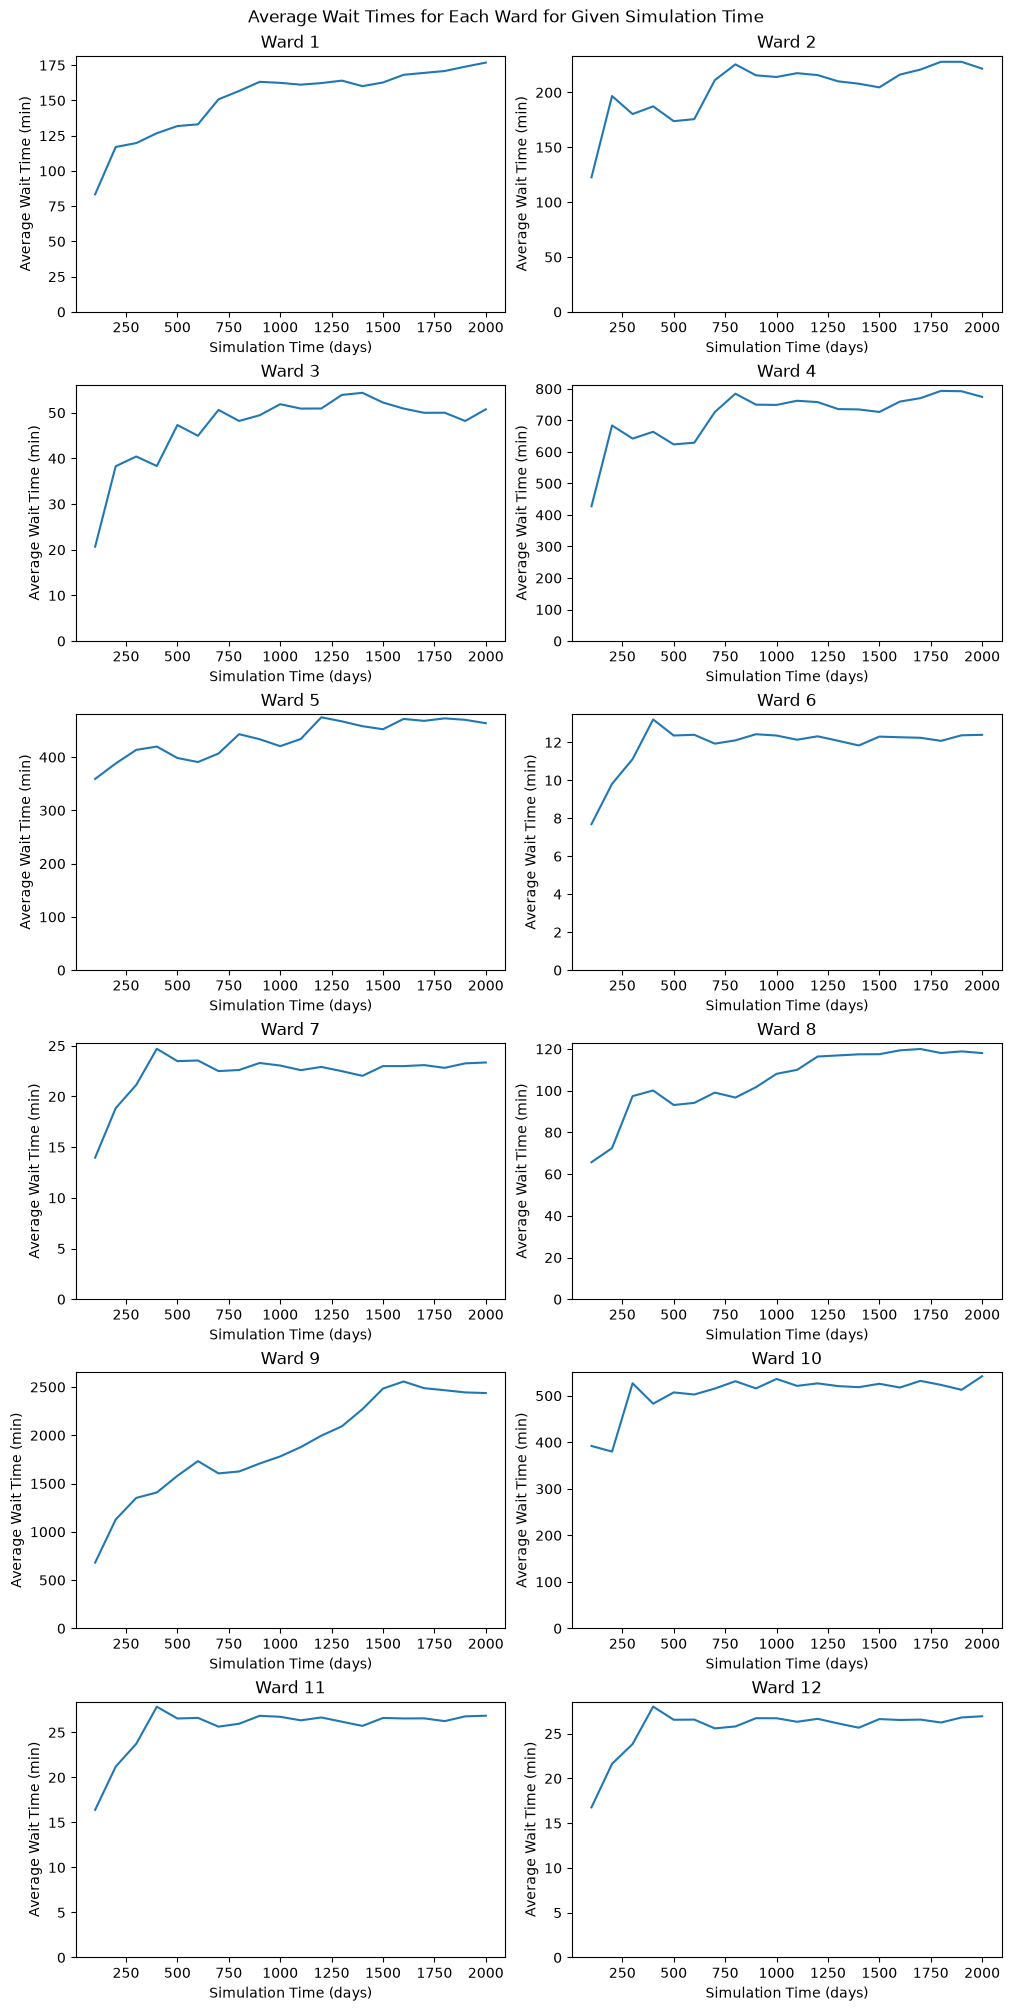

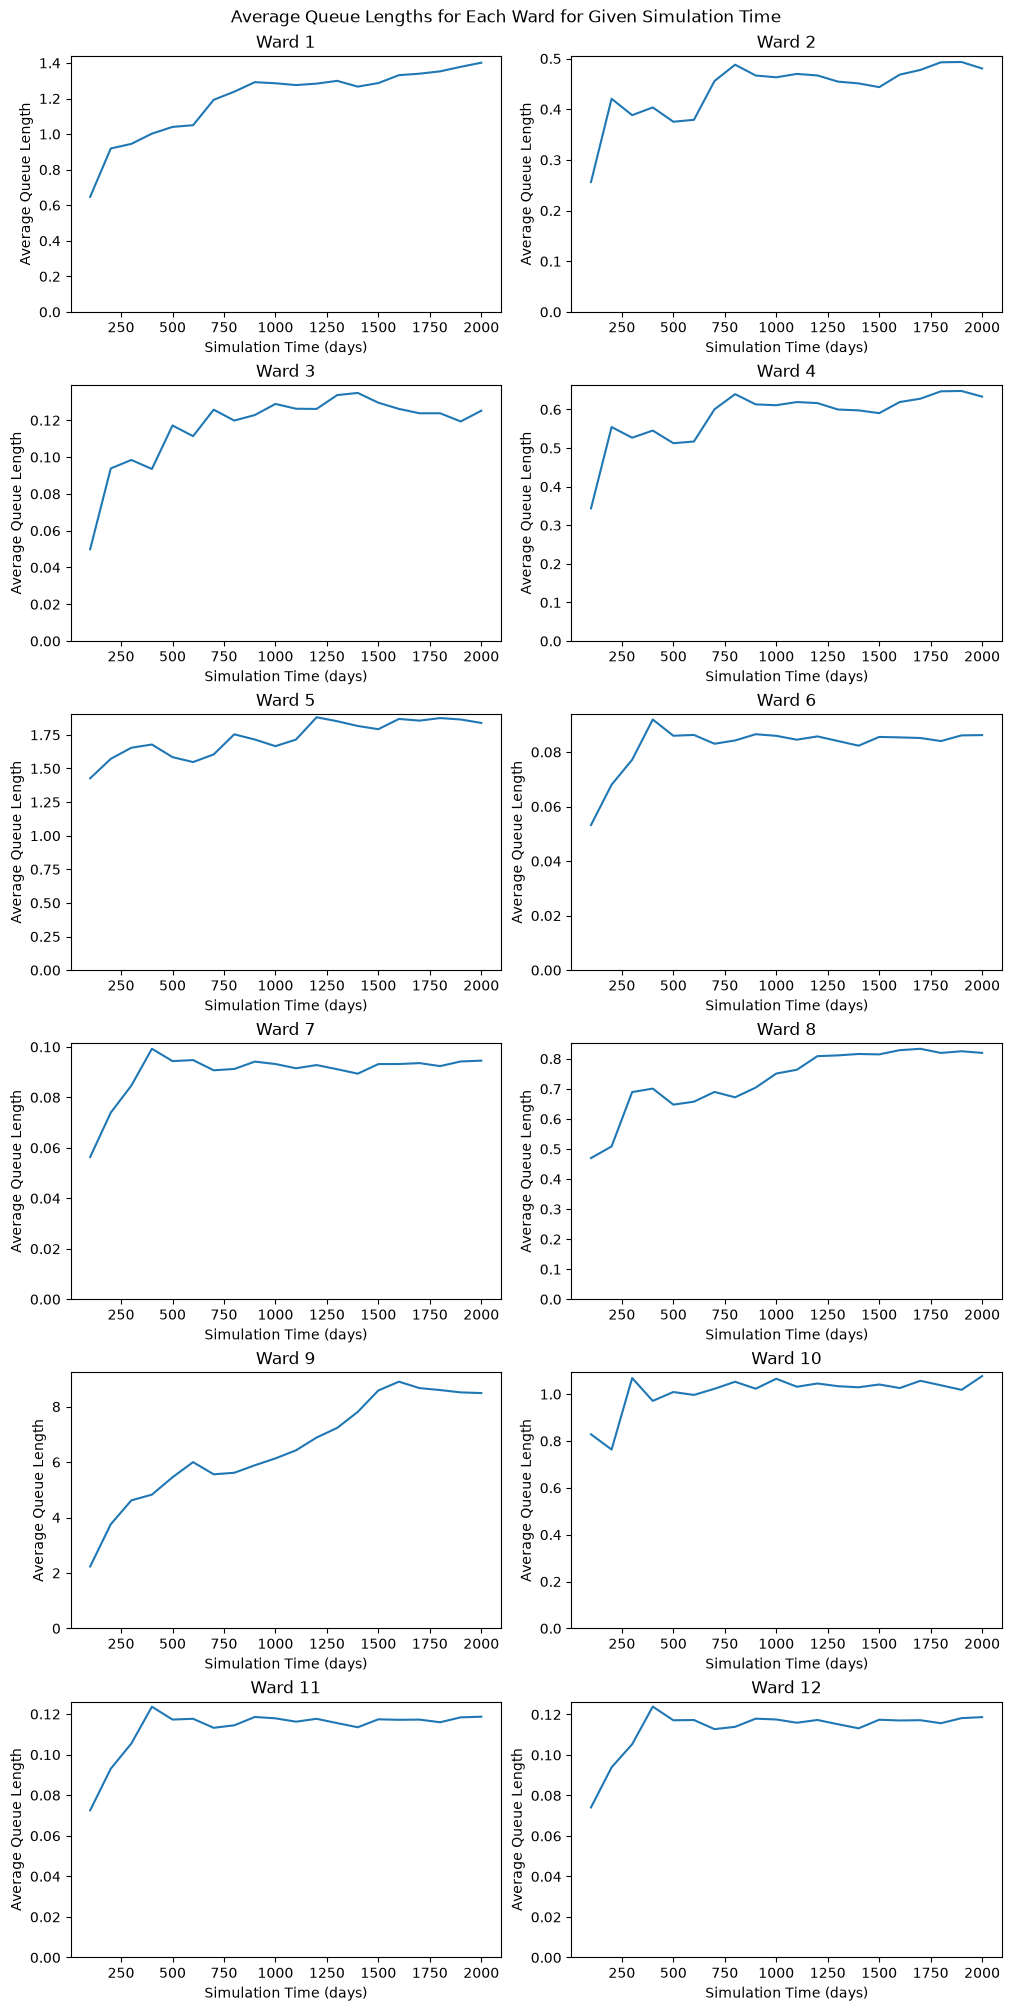

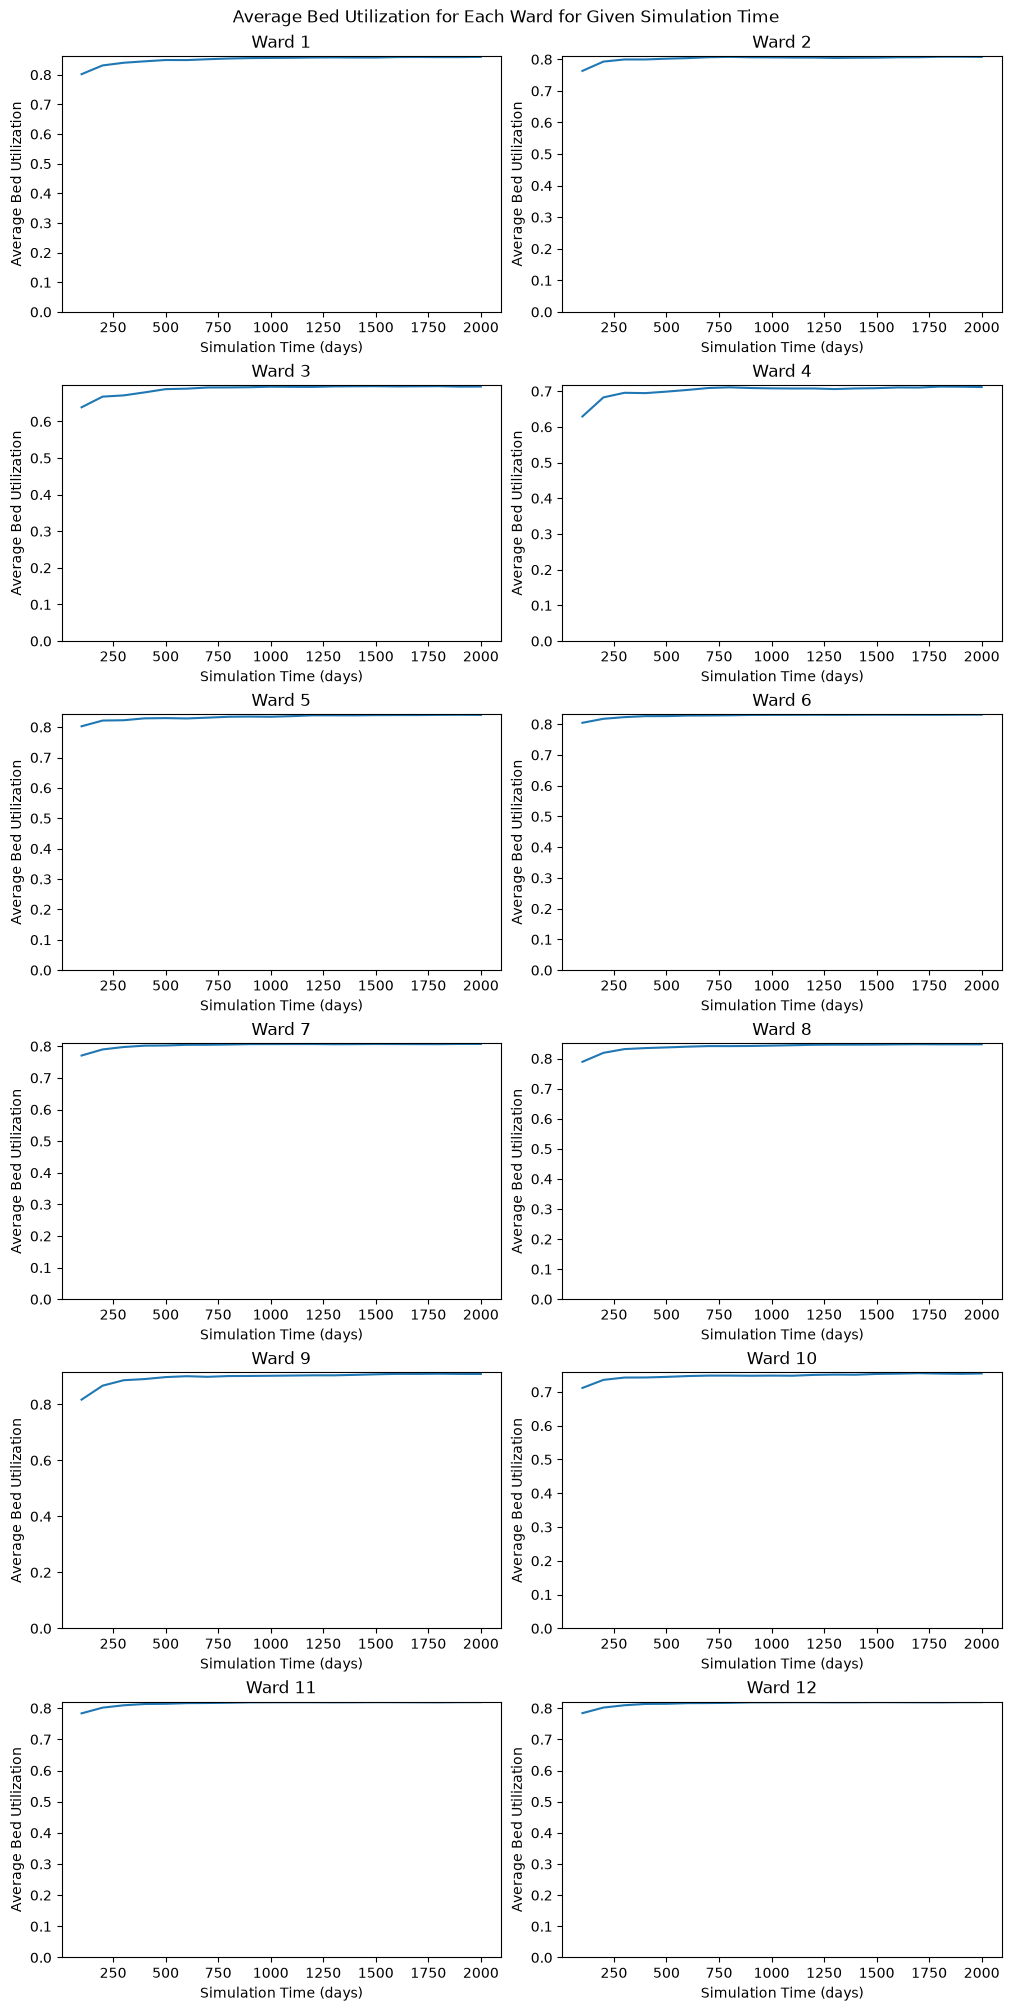

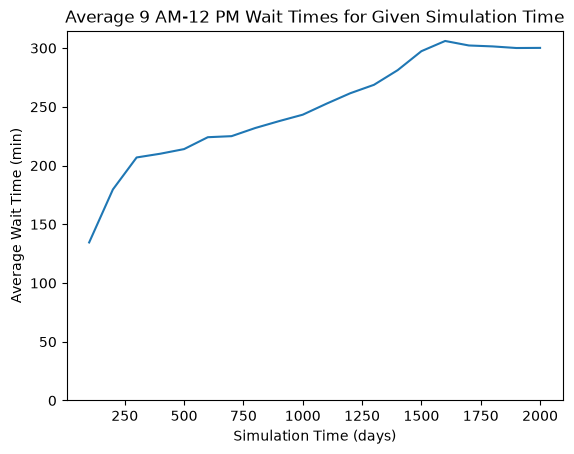

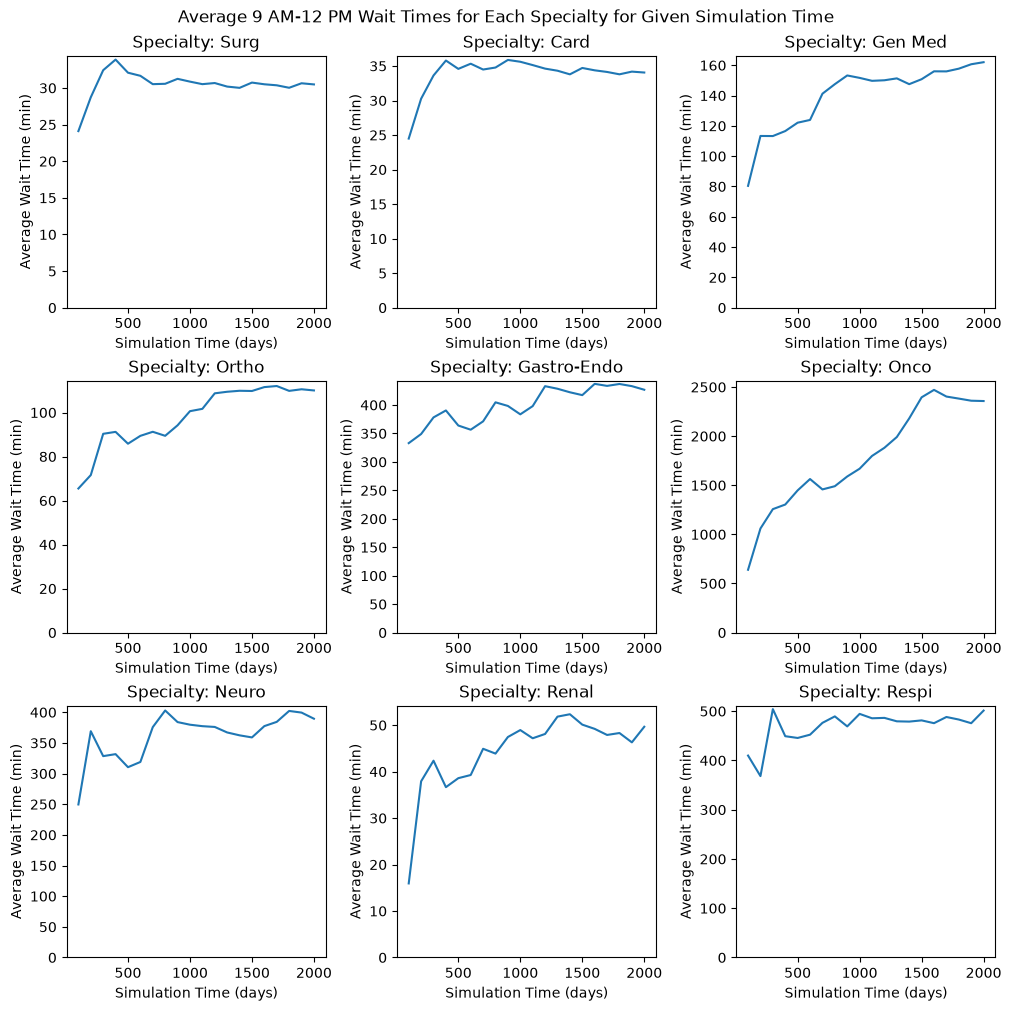

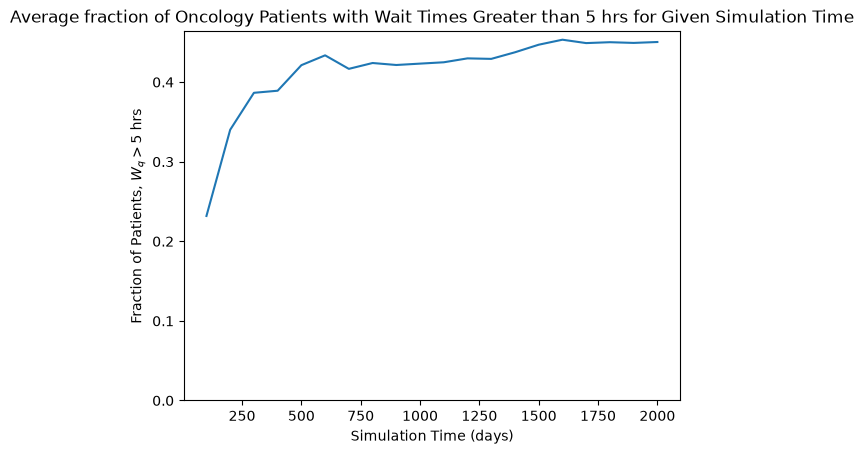

In [43]:
# Initial plotting for 100-2000 stats with spacing of 100 days
run_simulation_sweep_and_plot(100, 2000, 100)

Replication d=2000.00 days (2880000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 13.5759 sec
Replication d=2500.00 days (3600000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 16.3888 sec
Replication d=3000.00 days (4320000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

... (25 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 70.8646 sec
Replication d=10000.00 days (14400000.00 minutes)

100%|██████████| 1/1 [00:24<00:00, 24.99s/it]


 ...took 74.3610 sec
Done. Total running time 736.6913 sec


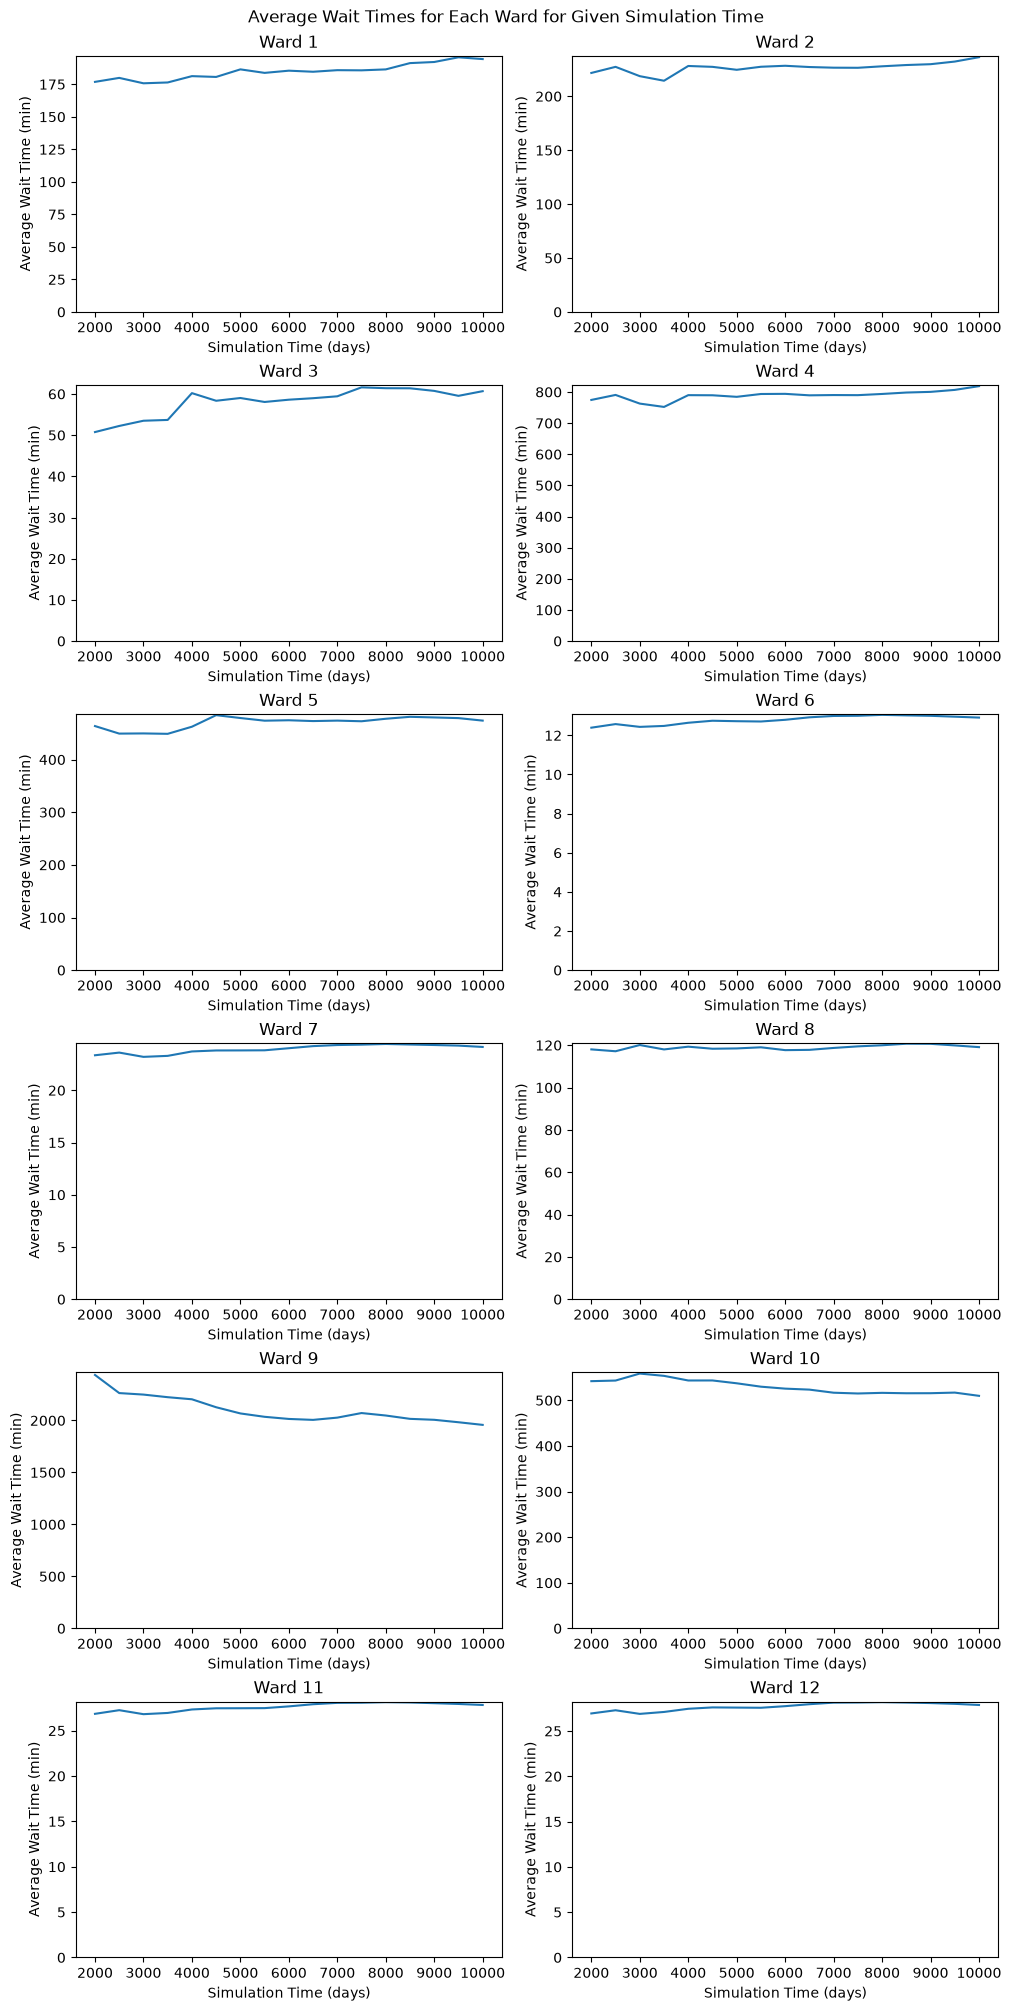

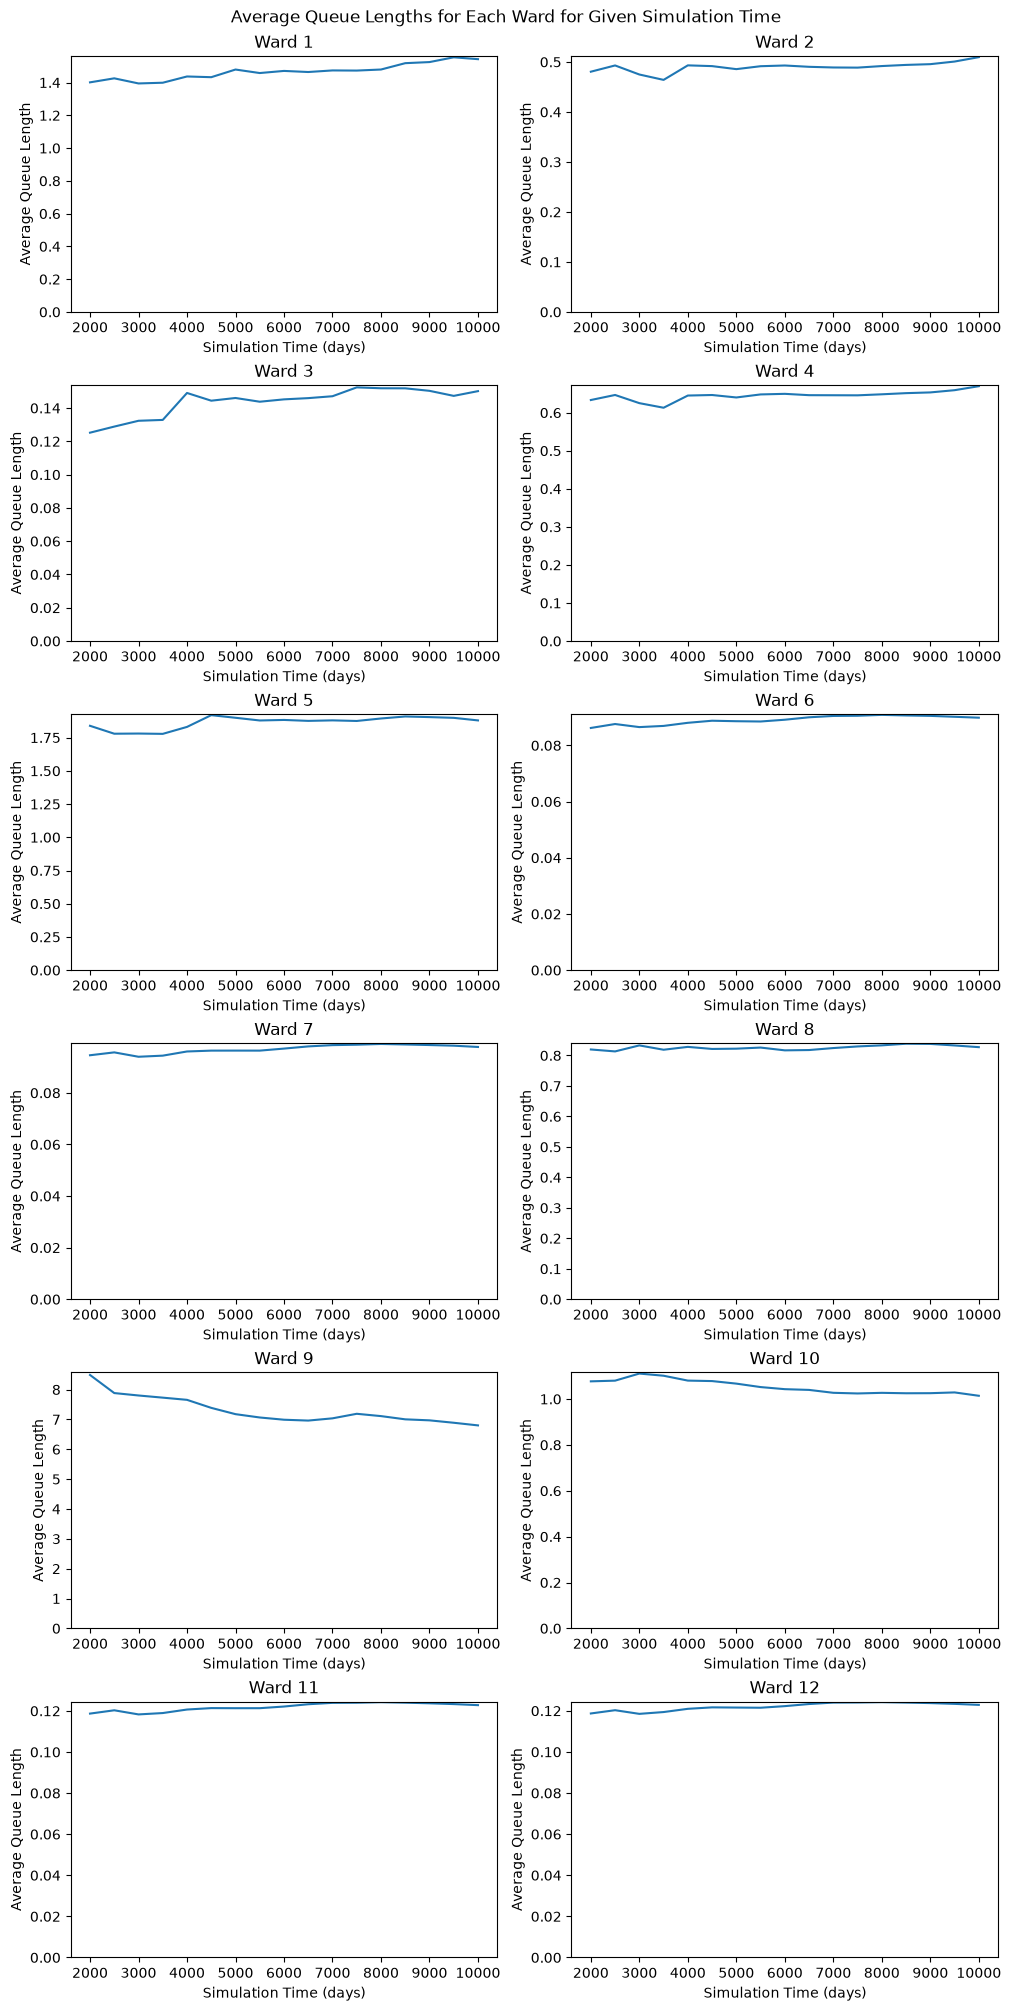

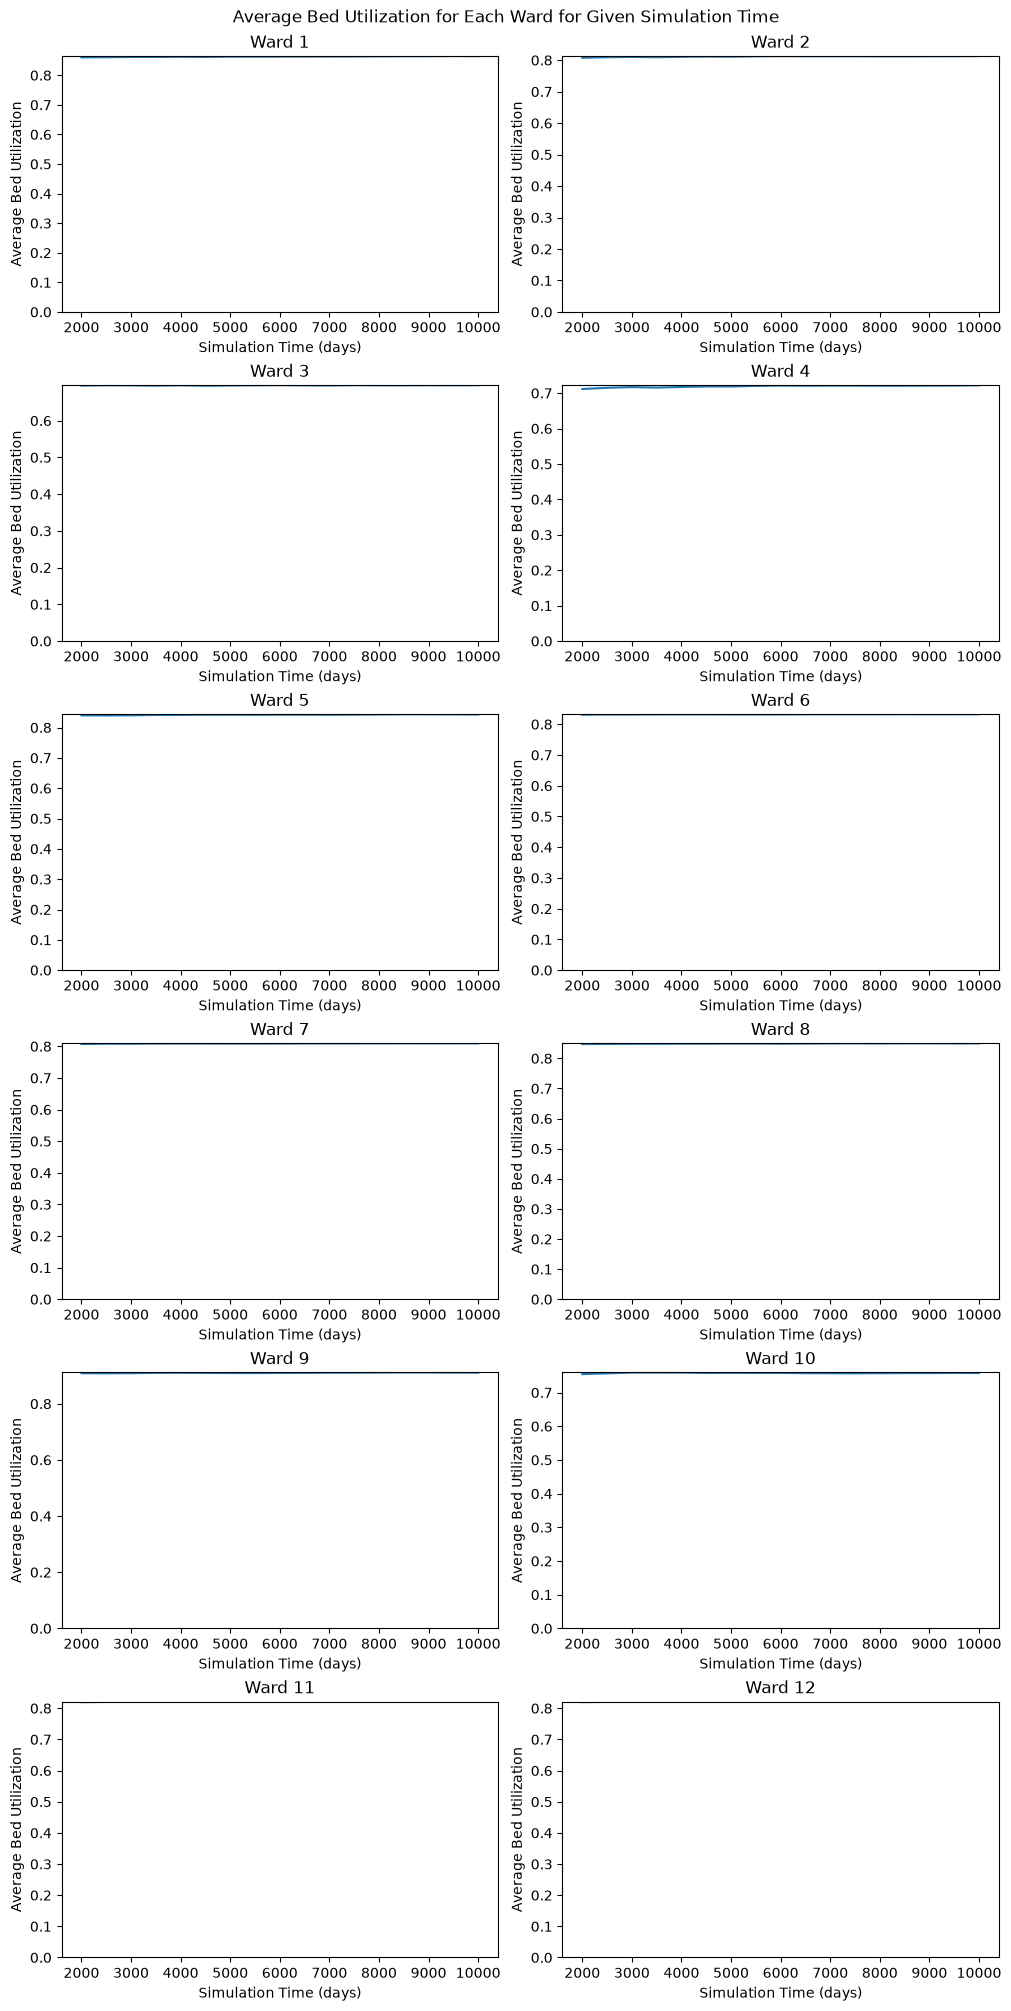

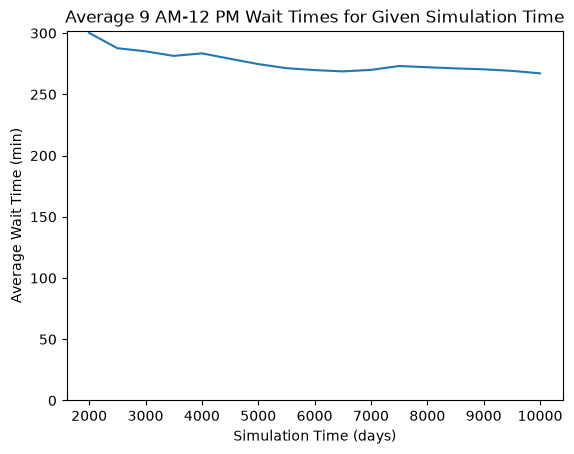

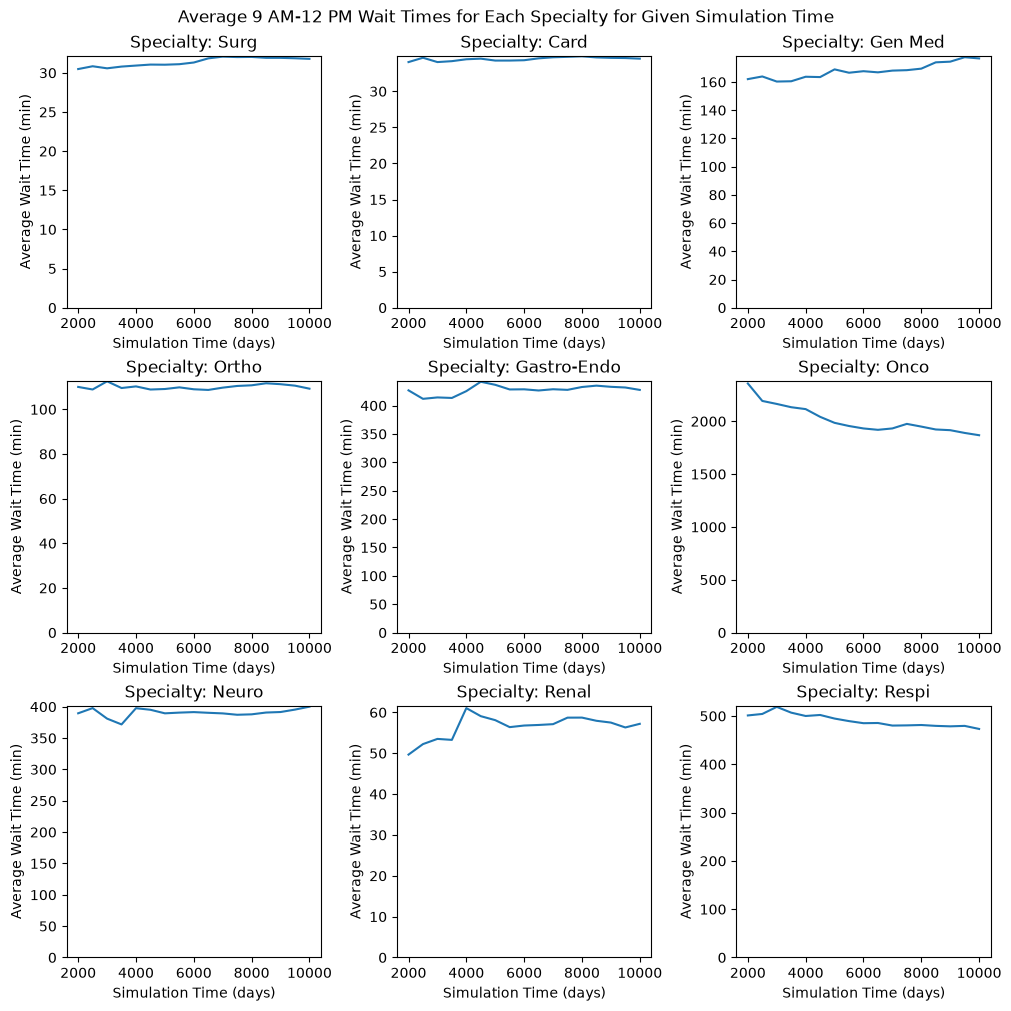

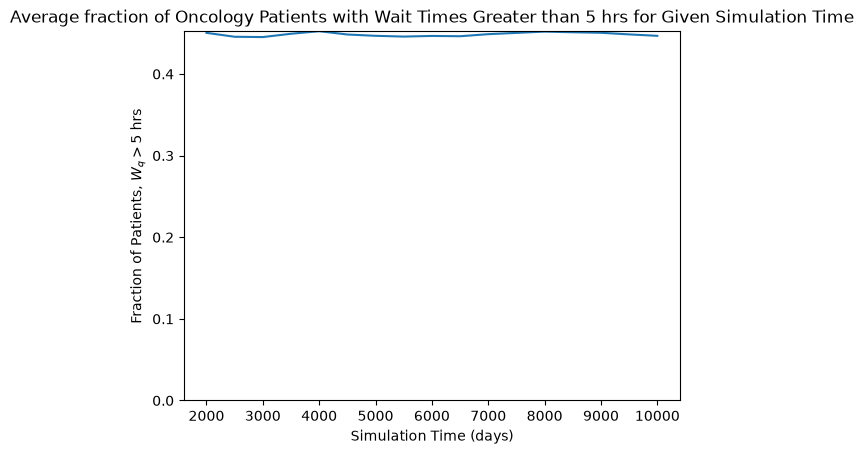

In [44]:
# 2000-10000 runs with spacing of 500 days
run_simulation_sweep_and_plot(2000, 10000, 500)

Replication d=10000.00 days (14400000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 74.7590 sec
Replication d=12500.00 days (18000000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 95.2051 sec
Replication d=15000.00 days (21600000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 111.0632 sec
Replication d=17500.00 days (25200000.00 minutes)

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 127.3723 sec
Replication d=20000.00 days (28800000.00 minutes)

100%|██████████| 1/1 [00:49<00:00, 49.12s/it]


 ...took 144.8348 sec
Done. Total running time 553.2344 sec


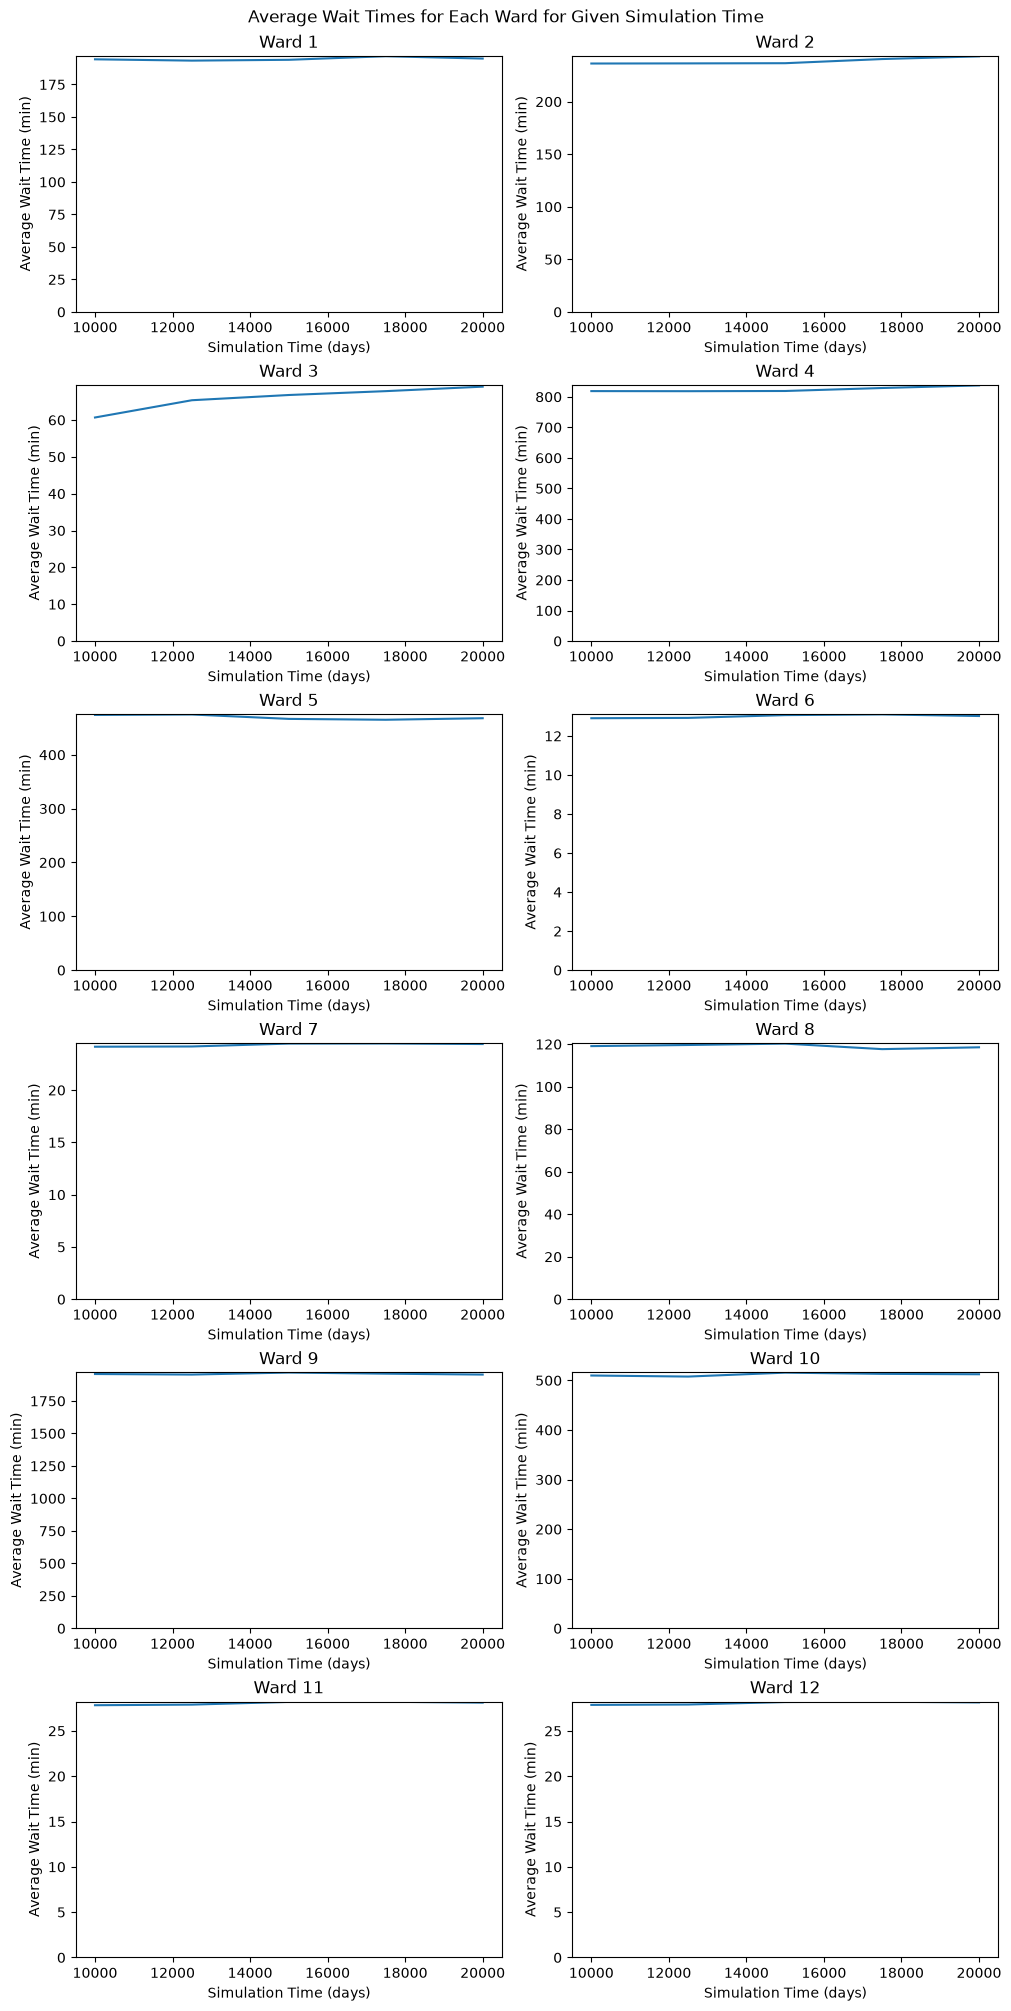

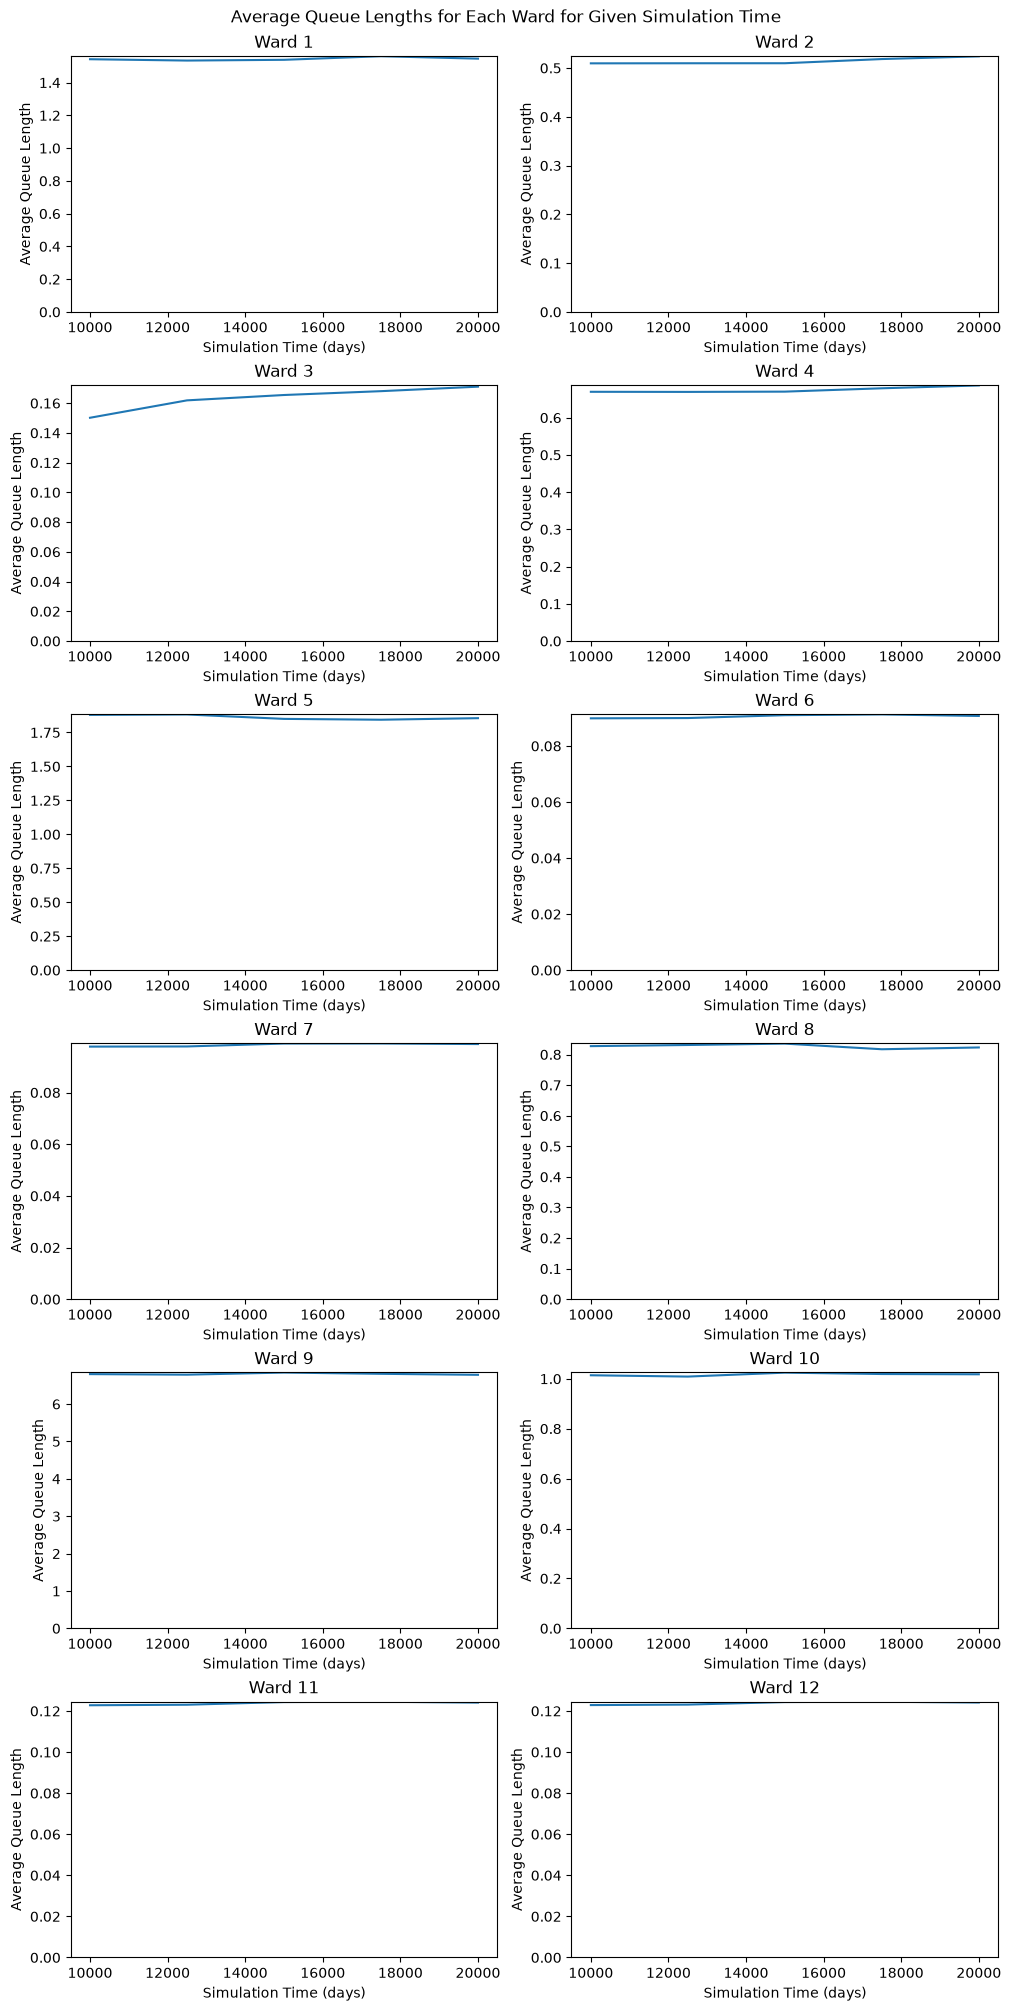

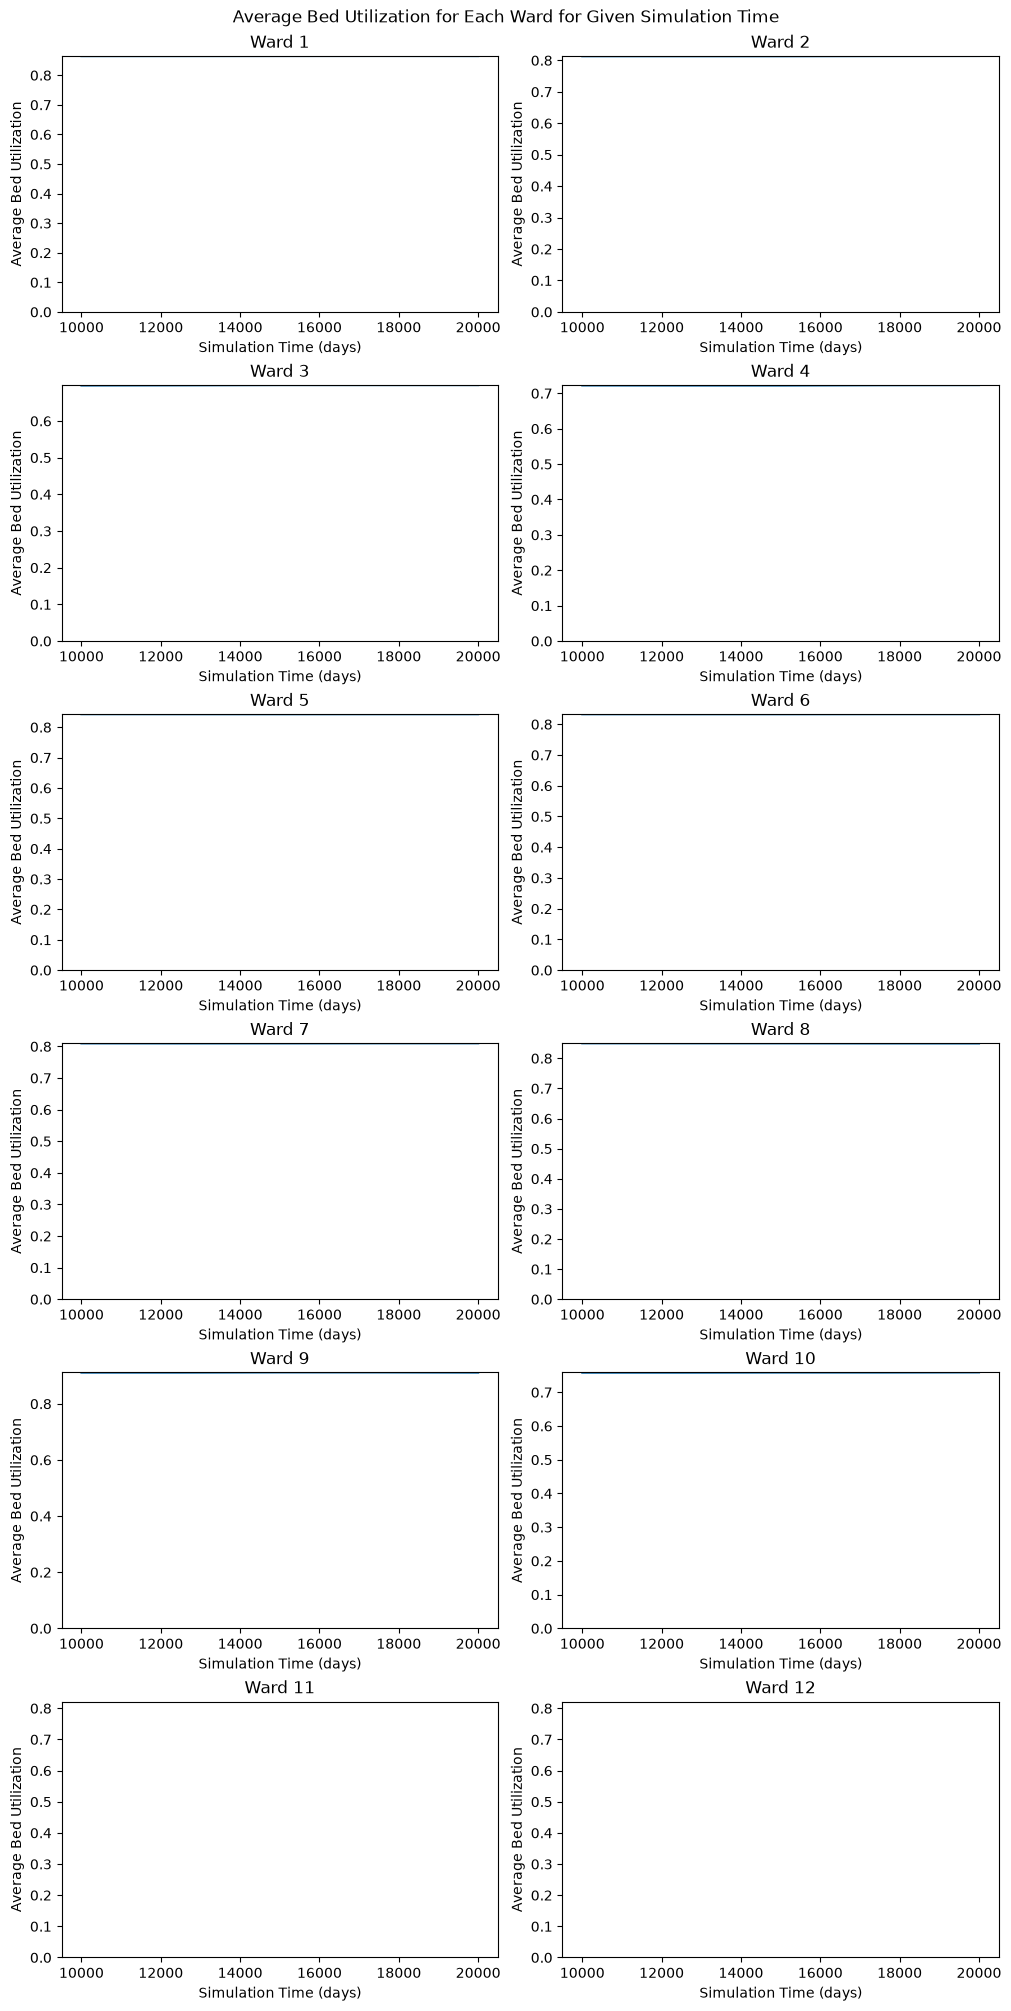

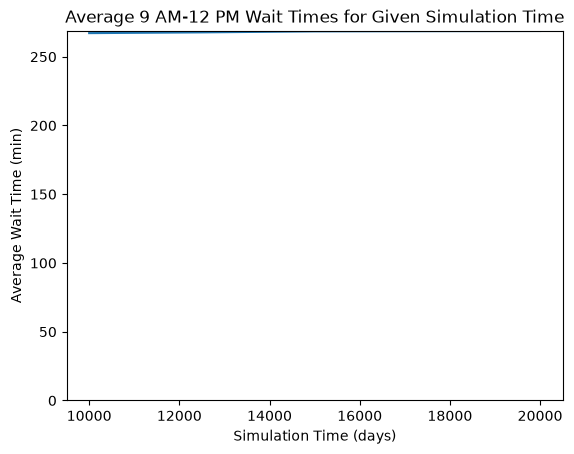

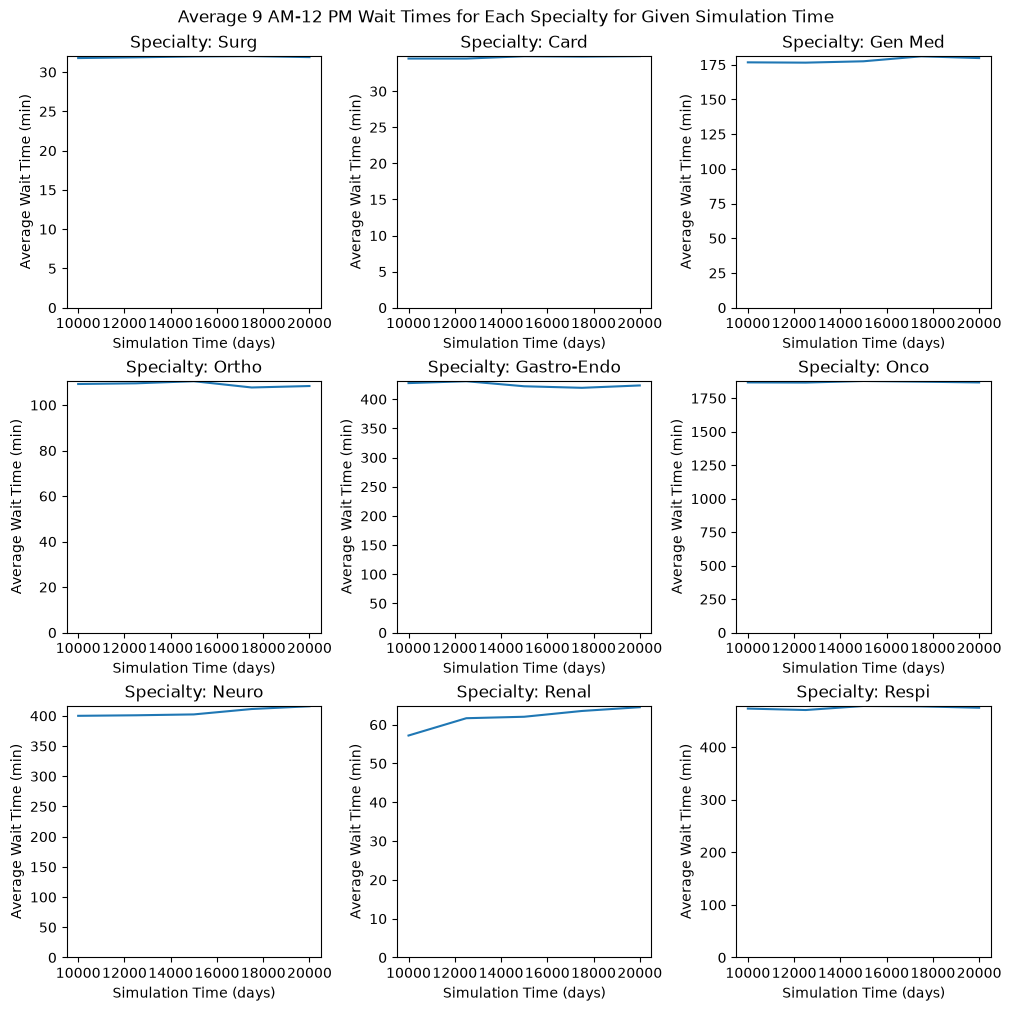

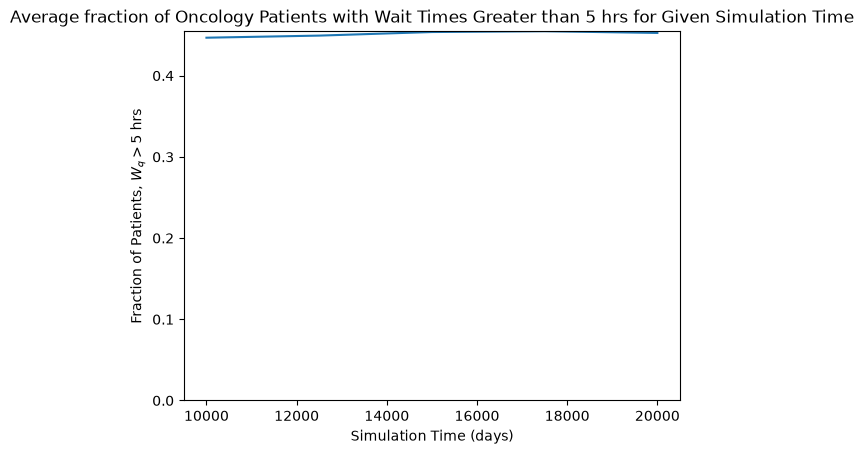

In [45]:
# 10000-20000 runs with spacing of 2500 days
run_simulation_sweep_and_plot(10000, 20000, 2500)

#### Warmup time tuning

In [46]:
from IPython.display import Markdown

# Plot all 6 stats
def plot_warmup_time_metrics(warmup_time_days, avg_wait_times_by_warmup_time, avg_queue_length_by_warmup_time,
                             avg_bed_utilization_by_warmup_time, avg_wait_times_9AM_12PM_by_warmup_time,
                             avg_wait_times_9AM_12PM_speciality_by_warmup_time,
                             proportion_oncology_above_5hrs_by_warmup_time):
    display(Markdown(f"### Warmup Time metrics for Simulation Time = {warmup_time_days} days"))
    time_values = list(avg_wait_times_by_warmup_time.keys())
    fig, axes = plt.subplots(6, 2, figsize=(10, 20), constrained_layout=True)
    fig.suptitle("Average Wait Times for Each Ward for Given Warmup Time Fraction")

    # Plot average wait times by sim time for each ward
    for ward, ax in enumerate(axes.flat, start=1):
        ward_avgs = {}
        for time in time_values:
            ward_avgs[time] = 0
            for idx, repl in enumerate(avg_wait_times_by_warmup_time[time], start=1):
                ward_avgs[time] += repl[ward]
            ward_avgs[time] /= idx

        ax.plot(ward_avgs.keys(), list(ward_avgs.values()))
        ax.set_ylim(bottom=0)
        ax.set_title(f"Ward {ward}")
        ax.set_xlabel("Warmup Time Fraction")
        ax.set_ylabel("Average Wait Time (min)")
        ax.set_xticks(time_values)
        ax.grid(True)
    plt.show()

    # Plot average queue length by sim time for each ward
    fig, axes = plt.subplots(6, 2, figsize=(10, 20), constrained_layout=True)
    fig.suptitle("Average Queue Lengths for Each Ward for Given Warmup Time Fraction")

    for ward, ax in enumerate(axes.flat, start=1):
        ward_avgs = {}
        for time in time_values:
            ward_avgs[time] = 0
            for idx, repl in enumerate(avg_queue_length_by_warmup_time[time], start=1):
                ward_avgs[time] += repl[ward]
            ward_avgs[time] /= idx

        ax.plot(ward_avgs.keys(), list(ward_avgs.values()))
        ax.set_ylim(bottom=0)
        ax.set_title(f"Ward {ward}")
        ax.set_xlabel("Warmup Time Fraction")
        ax.set_ylabel("Average Queue Length")
        ax.set_xticks(time_values)
        ax.grid(True)
    plt.show()

    # Plot average bed utilization by sim time for each ward
    fig, axes = plt.subplots(6, 2, figsize=(10, 20), constrained_layout=True)
    fig.suptitle("Average Bed Utilization for Each Ward for Given Warmup Time Fraction")

    for ward, ax in enumerate(axes.flat, start=1):
        ward_avgs = {}
        for time in time_values:
            ward_avgs[time] = 0
            for idx, repl in enumerate(avg_bed_utilization_by_warmup_time[time], start=1):
                ward_avgs[time] += repl[ward]
            ward_avgs[time] /= idx

        ax.plot(ward_avgs.keys(), list(ward_avgs.values()))
        ax.set_ylim(bottom=0)
        ax.set_title(f"Ward {ward}")
        ax.set_xlabel("Warmup Time Fraction")
        ax.set_ylabel("Average Bed Utilization")
        ax.set_xticks(time_values)
        ax.grid(True)
    plt.show()

    # Plot average 9-12 wait times by sim time
    plt.plot([x for x in time_values], [sum(repls) / len(repls) for repls in avg_wait_times_9AM_12PM_by_warmup_time.values()])
    plt.title("Average 9 AM-12 PM Wait Times for Given Warmup Time Fraction")
    plt.xlabel("Warmup Time Fraction")
    plt.ylabel("Average Wait Time (min)")
    plt.ylim(bottom=0)
    plt.xticks(time_values)
    plt.grid(True)
    plt.show()

    # Plot average 9-12 wait times by sim time for each specialty
    fig, axes = plt.subplots(3, 3, figsize=(10, 10), constrained_layout=True)
    fig.suptitle("Average 9 AM-12 PM Wait Times for Each Specialty for Given Warmup Time Fraction")

    for specialty, ax in zip(TreatmentType, axes.flat):
        specialty_avgs = {}
        for time in time_values:
            specialty_avgs[time] = 0
            for idx, repl in enumerate(avg_wait_times_9AM_12PM_speciality_by_warmup_time[time], start=1):
                specialty_avgs[time] += repl[specialty]
            specialty_avgs[time] /= idx

        ax.plot(specialty_avgs.keys(), list(specialty_avgs.values()))
        ax.set_ylim(bottom=0)
        ax.set_title(f"Specialty: {specialty.type_name}")
        ax.set_xlabel("Warmup Time Fraction")
        ax.set_ylabel("Average Wait Time (min)")
        ax.set_xticks(time_values)
        ax.grid(True)
    plt.show()

    # Plot fraction of oncology patients with wait times greater than 5 hrs by sim time
    plt.plot([x for x in time_values], [sum(repls) / len(repls) for repls in proportion_oncology_above_5hrs_by_warmup_time.values()])
    plt.title("Average fraction of Oncology Patients with Wait Times Greater than 5 hrs for Given Warmup Time Fraction")
    plt.xlabel("Warmup Time Fraction")
    plt.ylabel(r"Fraction of Patients, $W_{q} > 5$ hrs")
    plt.ylim(bottom=0)
    plt.xticks(time_values)
    plt.grid(True)
    plt.show()


def run_warmup_sweep_and_plot(sim_time_days, warmup_fractions):
    avg_wait_times_by_warmup_time = {}
    avg_queue_length_by_warmup_time = {}
    avg_bed_utilization_by_warmup_time = {}
    avg_wait_times_9AM_12PM_by_warmup_time = {}
    avg_wait_times_9AM_12PM_speciality_by_warmup_time = {}
    proportion_oncology_above_5hrs_by_warmup_time = {}

    NUM_REPLICATIONS = 20

    total_running_time = 0
    sim_time = days_to_minutes(sim_time_days)

    for warmup_fraction in warmup_fractions:
        warmup_time = sim_time*warmup_fraction
        print(f"Replication d={sim_time_days:.2f} days ({sim_time:.2f} minutes), warmup fraction = {warmup_fraction:.4f}, ", end="")
        model_args = (BASE_PHYSICIANS_PER_WARD, BASE_PHYSICIAN_DISCHARGE_TIME, BASE_PHYSICIAN_ACTIVITY_INTERVAL, BASE_CLEANING_INTERVAL, sim_time, warmup_time)

        start_time = perf_counter()
        (average_wait_times_list, average_queue_length_list, 
        average_bed_utilization_list, average_wait_times_9AM_12PM_list, 
        average_wait_times_9AM_12PM_by_specialty_list, proportion_oncology_above_5_hours_list) = run_parallel_replications(
            NUM_REPLICATIONS, model_args, workers=NUM_WORKERS, base_seed=BASE_SEED)
        end_time = perf_counter()
        run_time = end_time - start_time
        total_running_time += run_time
        print(f" ...took {run_time:0.4f} sec")
        
        avg_wait_times_by_warmup_time[warmup_fraction] = average_wait_times_list
        avg_queue_length_by_warmup_time[warmup_fraction] = average_queue_length_list
        avg_bed_utilization_by_warmup_time[warmup_fraction] = average_bed_utilization_list
        avg_wait_times_9AM_12PM_by_warmup_time[warmup_fraction] = average_wait_times_9AM_12PM_list
        avg_wait_times_9AM_12PM_speciality_by_warmup_time[warmup_fraction] = average_wait_times_9AM_12PM_by_specialty_list
        proportion_oncology_above_5hrs_by_warmup_time[warmup_fraction] = proportion_oncology_above_5_hours_list

    print(f"Done. Total running time {total_running_time:.4f} sec")
    plot_warmup_time_metrics(sim_time_days, avg_wait_times_by_warmup_time, avg_queue_length_by_warmup_time,
                      avg_bed_utilization_by_warmup_time, avg_wait_times_9AM_12PM_by_warmup_time,
                      avg_wait_times_9AM_12PM_speciality_by_warmup_time,
                      proportion_oncology_above_5hrs_by_warmup_time)

Replication d=10000.00 days (14400000.00 minutes), warmup fraction = 0.0250, 

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 71.4406 sec
Replication d=10000.00 days (14400000.00 minutes), warmup fraction = 0.0500, 

  0%|          | 0/1 [00:00<?, ?it/s]

 ...took 71.6296 sec
Replication d=10000.00 days (14400000.00 minutes), warmup fraction = 0.1000, 

  0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

100%|██████████| 1/1 [00:25<00:00, 25.70s/it]


 ...took 76.0688 sec
Done. Total running time 370.4597 sec


100%|██████████| 1/1 [00:25<00:00, 25.65s/it]


### Warmup Time metrics for Simulation Time = 10000 days

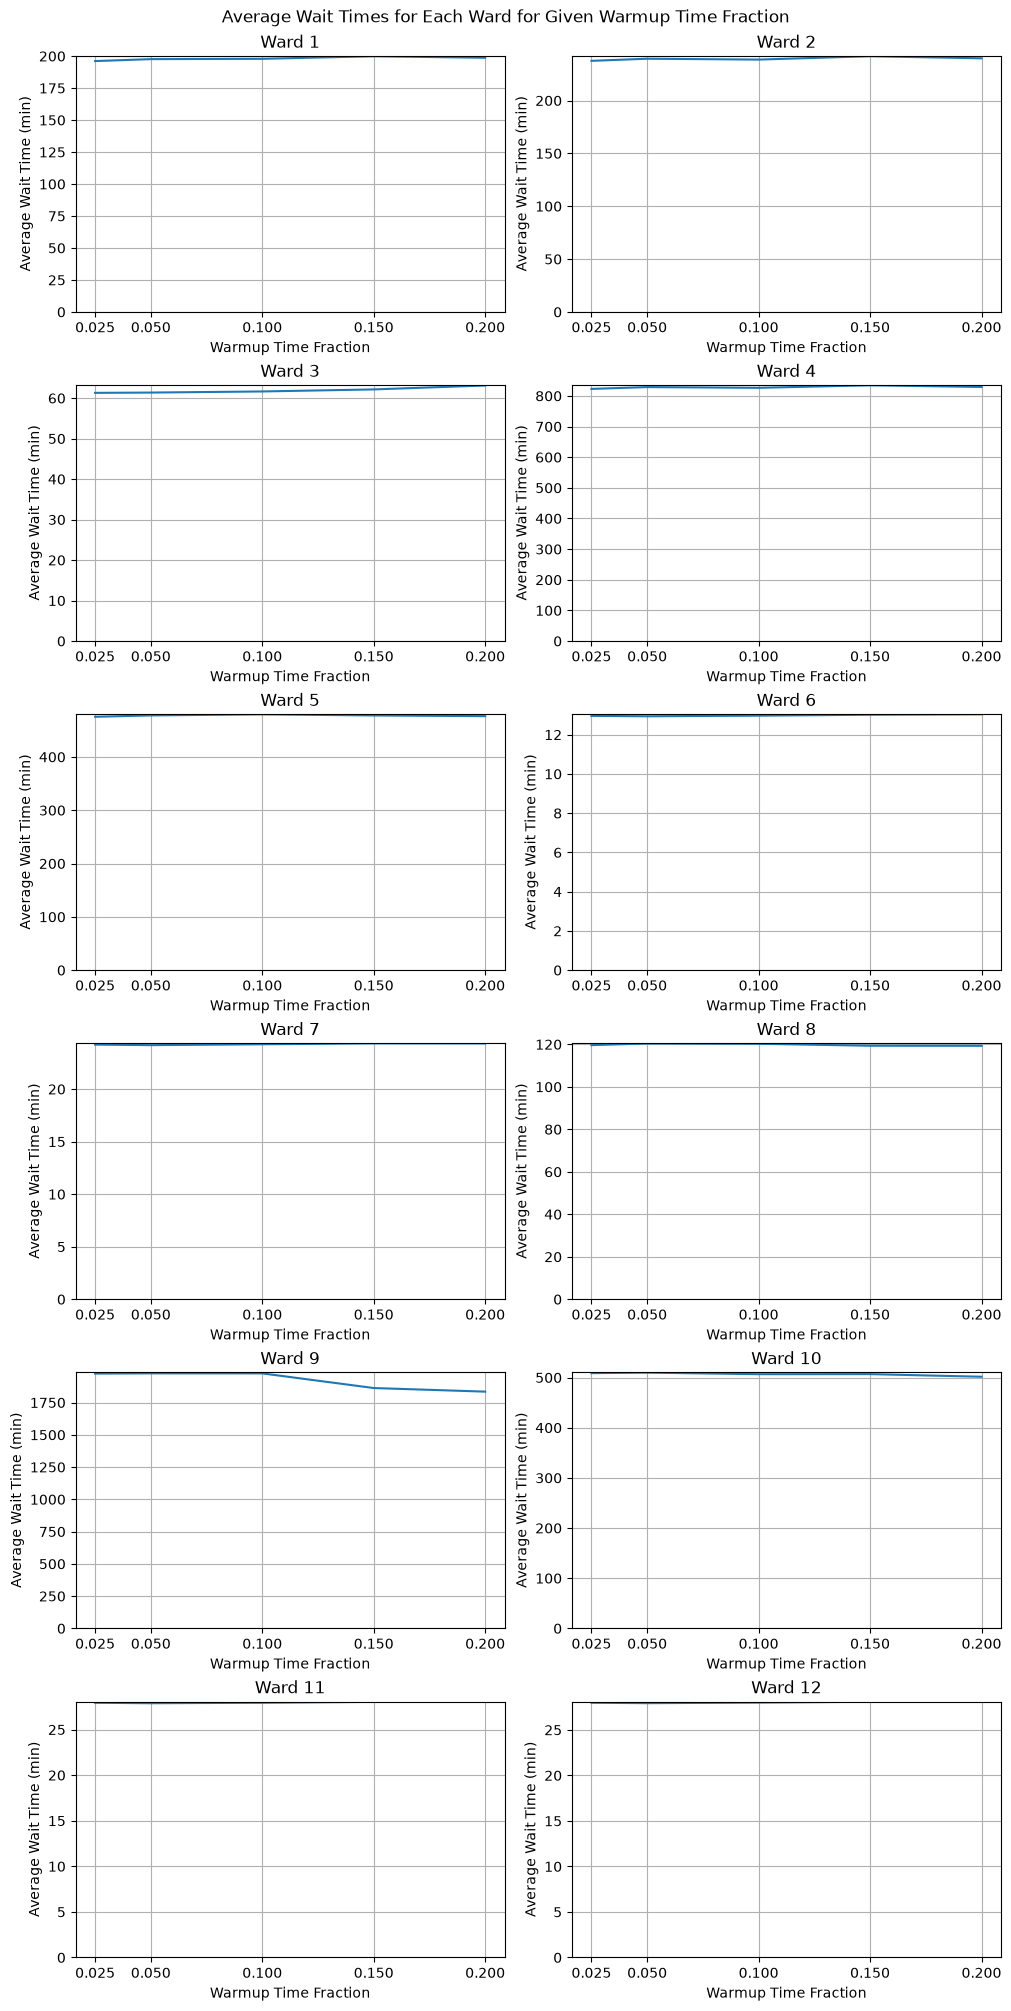

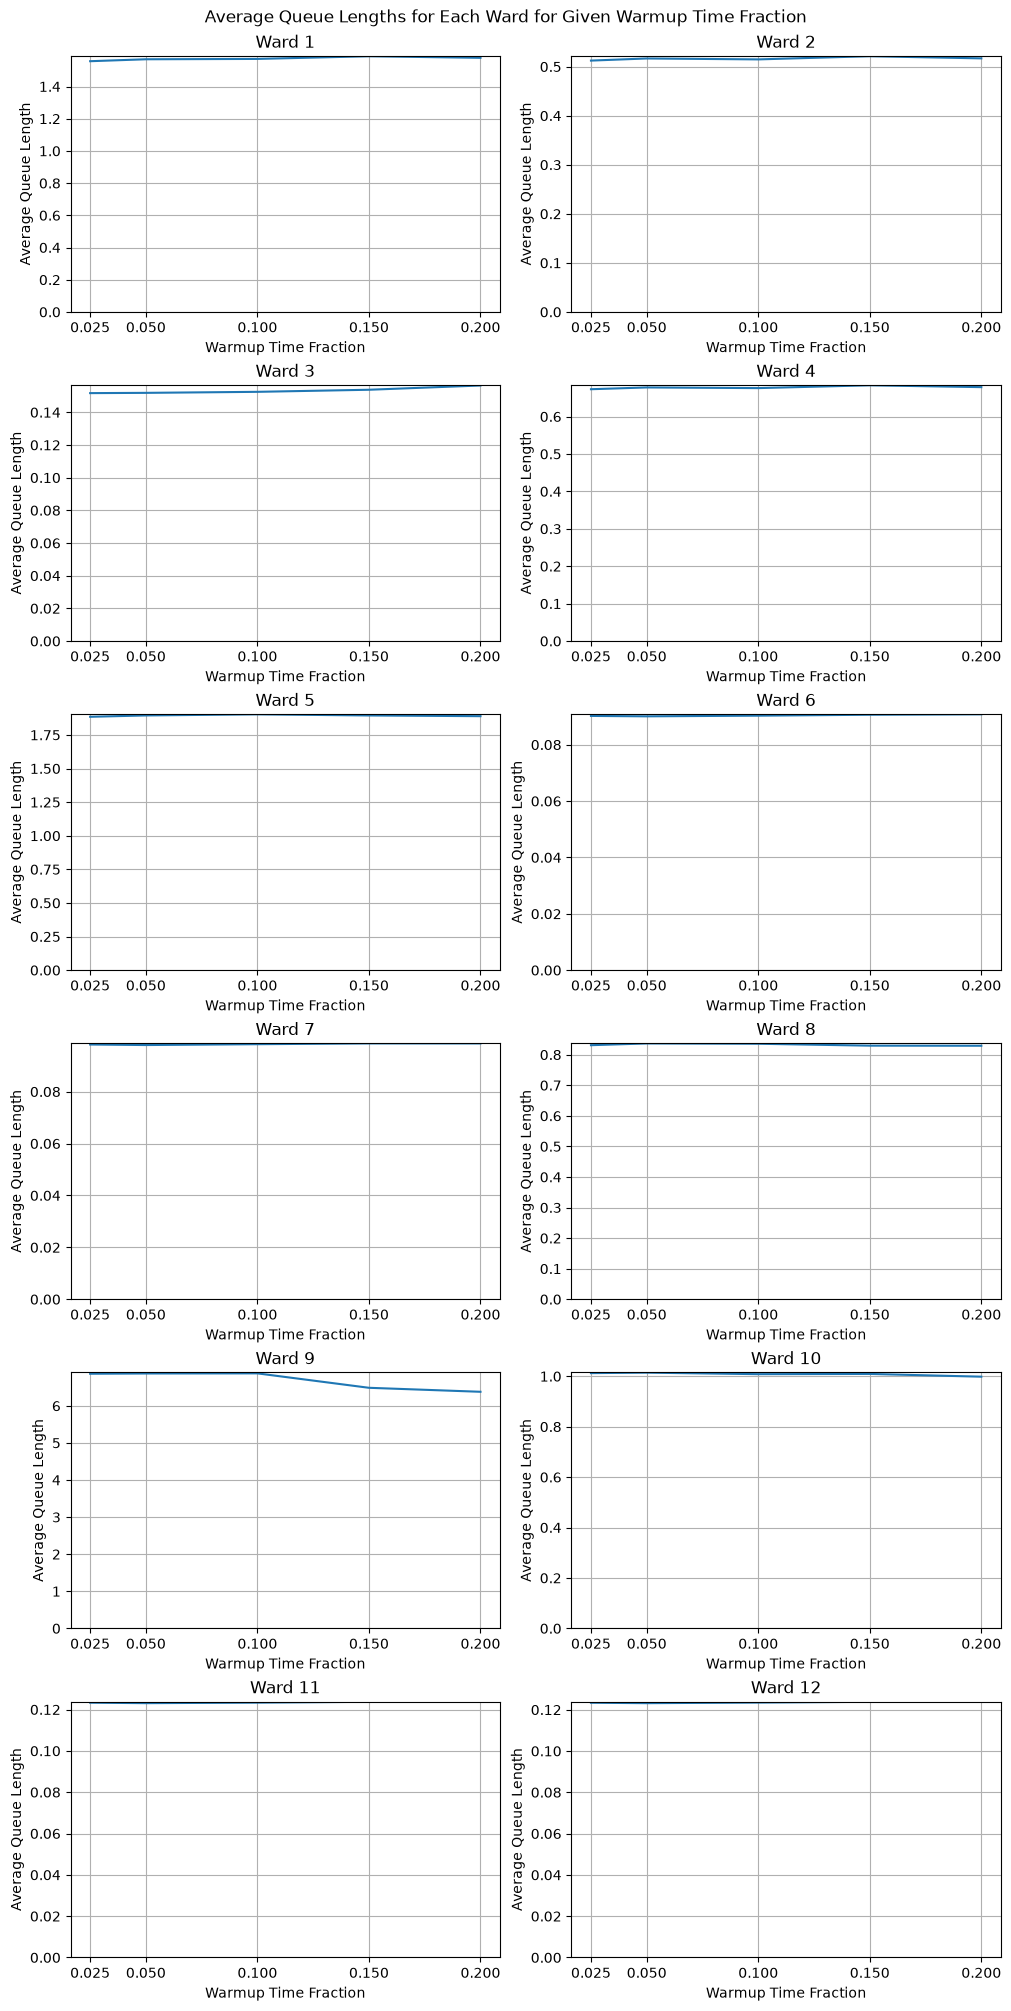

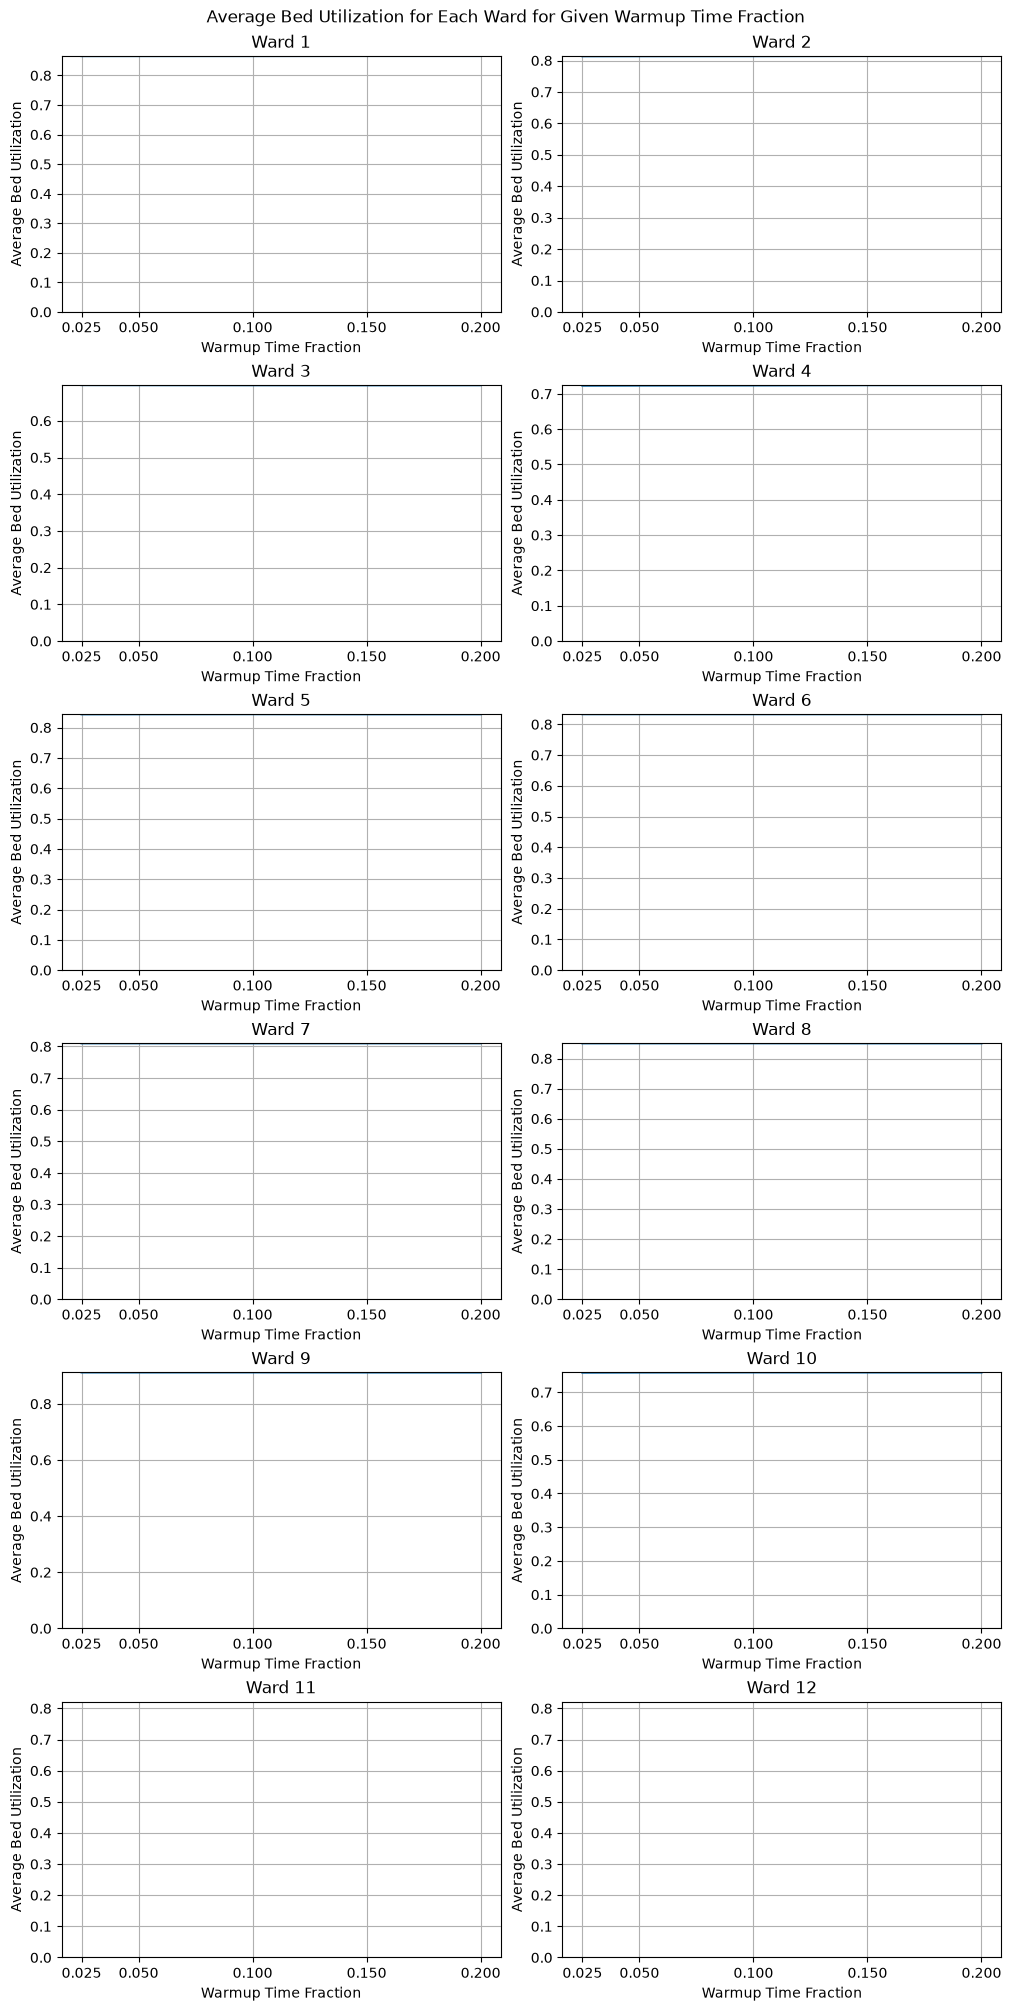

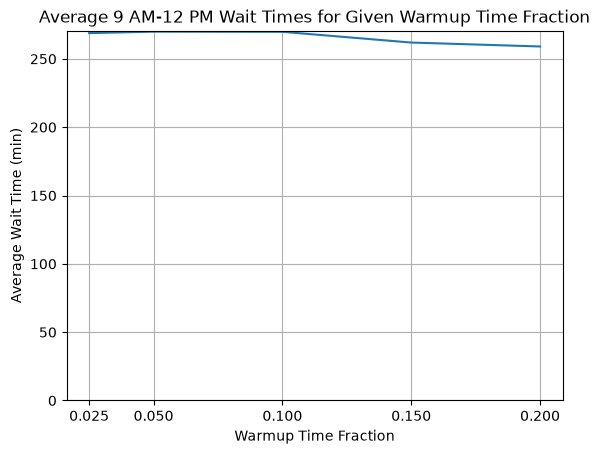

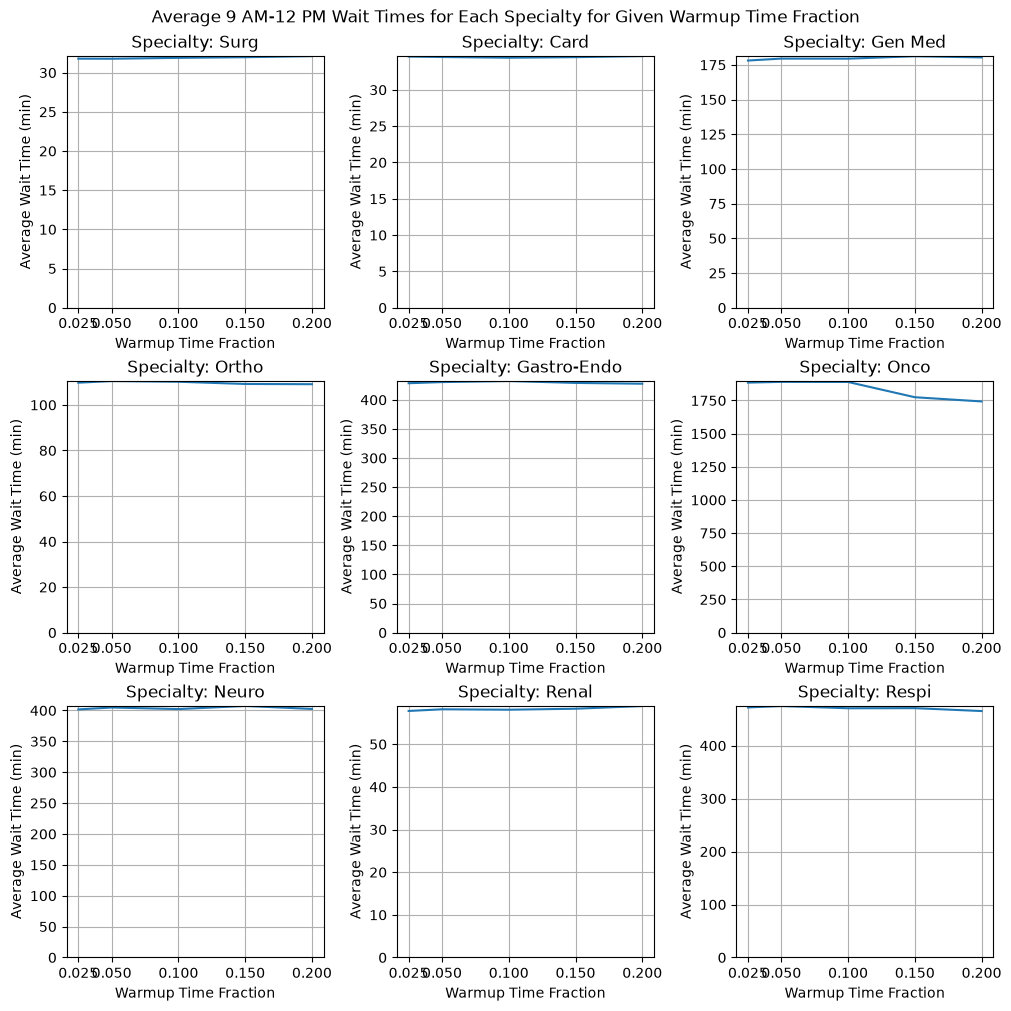

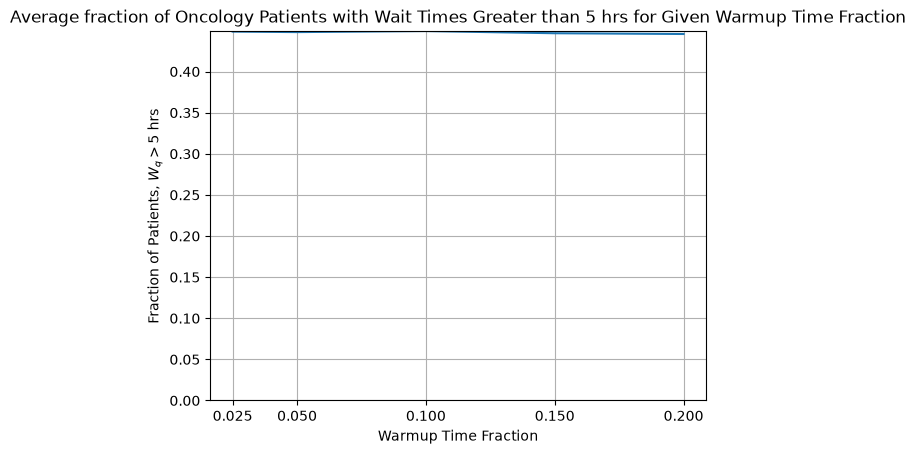

In [47]:
warmup_fractions = [0.025, 0.05, 0.10, 0.15, 0.20]
run_warmup_sweep_and_plot(10000, warmup_fractions)

### Final run

In [48]:
avg_wait_times_list = []
avg_queue_length_list = []
avg_bed_utilization_list = []
avg_wait_times_9AM_12PM_list = []
avg_wait_times_9AM_12PM_by_speciality_list = []
proportion_oncology_above_5_hours_list = []

NUM_REPLICATIONS = 40

total_running_time = 0
SIM_TIME_DAYS = 10000
sim_time = days_to_minutes(SIM_TIME_DAYS)
warmup_end = sim_time * 0.10
print(f"Replication d={SIM_TIME_DAYS:.2f} days ({sim_time:.2f} minutes) ", end="")
model_args = (BASE_PHYSICIANS_PER_WARD, BASE_PHYSICIAN_DISCHARGE_TIME, BASE_PHYSICIAN_ACTIVITY_INTERVAL, BASE_CLEANING_INTERVAL, sim_time, warmup_end)

start_time = perf_counter()
average_wait_times_list, average_queue_length_list, \
average_bed_utilization_list, average_wait_times_9AM_12PM_list, \
average_wait_times_9AM_12PM_by_specialty_list, proportion_oncology_above_5_hours_list = run_parallel_replications(
    NUM_REPLICATIONS,  model_args, workers=NUM_WORKERS, base_seed=BASE_SEED)
end_time = perf_counter()
total_running_time = end_time - start_time

print(f"Done. Total running time {total_running_time:.4f} sec")

base_outputs = (average_wait_times_list, average_queue_length_list, average_bed_utilization_list,
                average_wait_times_9AM_12PM_list, average_wait_times_9AM_12PM_by_specialty_list,
                proportion_oncology_above_5_hours_list)

Replication d=10000.00 days (14400000.00 minutes) 

100%|██████████| 1/1 [00:30<00:00, 30.52s/it]


Done. Total running time 126.7278 sec


100%|██████████| 1/1 [00:31<00:00, 31.13s/it]


### Results (USE ON FINAL RUN)

In [ ]:
def mean_and_95_ci(values):
    values = np.asarray(values, dtype=float)
    n = len(values)

    if n < 2:
        raise ValueError('Need at least two replications')
    if not np.all(np.isfinite(values)):
        raise ValueError('Replications contain NaN or infinity')

    mean = np.mean(values)
    standard_error = np.std(values, ddof=1) / np.sqrt(n)
    margin = standard_error * stats.t.ppf(0.975, df=n-1)
    return [mean, (round(mean-margin,2), round(mean+margin,2))]

def summarize_results(average_wait_times_list, average_queue_length_list, average_bed_utilization_list,
                      average_wait_times_9AM_12PM_list, average_wait_times_9AM_12PM_by_specialty_list,
                      proportion_oncology_above_5_hours_list):
    # LONG RUN AVERAGE WAITING TIMES 
    long_run_waiting_times_ward = {1: [], 2: [], 3:[], 4:[], 5: [], 6: [], 7:[], 8:[], 9: [], 10: [], 11:[], 12:[], "All": []}
    for item in average_wait_times_list:
        for ward, average_time in item.items():
            long_run_waiting_times_ward[ward].append(average_time)
    for ward, values in long_run_waiting_times_ward.items():
        long_run_waiting_times_ward[ward] = mean_and_95_ci(values)

    # LONG RUN AVERAGE QUEUE LENGTHS
    long_run_queueing_lengths_ward = {1: [], 2: [], 3:[], 4:[], 5: [], 6: [], 7:[], 8:[], 9: [], 10: [], 11:[], 12:[]}
    for item in average_queue_length_list:
        for ward, average_time in item.items():
            long_run_queueing_lengths_ward[ward].append(average_time)
    for ward, values in long_run_queueing_lengths_ward.items():
        long_run_queueing_lengths_ward[ward] = mean_and_95_ci(values)

    # LONG RUN BED UTILIZATION
    long_run_bed_utilization_ward = {1: [], 2: [], 3:[], 4:[], 5: [], 6: [], 7:[], 8:[], 9: [], 10: [], 11:[], 12:[]}
    for item in average_bed_utilization_list:
        for ward, average_time in item.items():
            long_run_bed_utilization_ward[ward].append(average_time)
    for ward, values in long_run_bed_utilization_ward.items():
        long_run_bed_utilization_ward[ward] = mean_and_95_ci(values)

    # OVERALL LONG RUN AVERAGE WAITING TIMES. 9AM-12PM
    overall_long_run_waiting_time_9AM_12PM = mean_and_95_ci(average_wait_times_9AM_12PM_list)

    # LONG RUN AVERAGE WAITING TIMES. 9AM-12PM. BY SPECIALTY
    T = TreatmentType
    T_keys = [T.SURG, T.CARD, T.GEN_MED, T.ORTHO, T.GASTRO_ENDO, T.ONCO, T.NEURO, T.RENAL, T.RESPI]
    average_wait_times_9AM_12PM_by_specialty_DICT = {specialty: [] for specialty in T_keys}
    for item in average_wait_times_9AM_12PM_by_specialty_list:
        for specialty, average_time in item.items():
            average_wait_times_9AM_12PM_by_specialty_DICT[specialty].append(average_time)
    for specialty, values in average_wait_times_9AM_12PM_by_specialty_DICT.items():
        average_wait_times_9AM_12PM_by_specialty_DICT[specialty] = mean_and_95_ci(values)

    # LONG RUN FRACTION OF ONCOLOGY PATIENTS WITH >5h WAITING TIME
    proportion_oncology_above_5_hours = mean_and_95_ci(proportion_oncology_above_5_hours_list)

    return (long_run_waiting_times_ward, long_run_queueing_lengths_ward, long_run_bed_utilization_ward,
            overall_long_run_waiting_time_9AM_12PM, average_wait_times_9AM_12PM_by_specialty_DICT,
            proportion_oncology_above_5_hours)

(long_run_waiting_times_ward, long_run_queueing_lengths_ward, long_run_bed_utilization_ward,
 overall_long_run_waiting_time_9AM_12PM, average_wait_times_9AM_12PM_by_specialty_DICT,
 proportion_oncology_above_5_hours) = summarize_results(*base_outputs)

In [ ]:
# Data into tables
from IPython.display import display, Markdown
def display_table(title, df):
    display(Markdown(f'### {title}'))
    display(df)

wards = [f'Ward {i+1}' for i in range(12)] + ['All patients']
index = [f'Average of {NUM_REPLICATIONS} replications', '95% CI']

df_long_run_waiting_times_ward = pd.DataFrame(long_run_waiting_times_ward, index=index)
df_long_run_waiting_times_ward.columns = wards
display_table('Long-run average waiting times (min)',df_long_run_waiting_times_ward)

df_long_run_queueing_lengths_ward = pd.DataFrame(long_run_queueing_lengths_ward, index=index)
df_long_run_queueing_lengths_ward.columns = wards[:12]
display_table('Long-run average queue lengths (patients)', df_long_run_queueing_lengths_ward)

df_long_run_bed_utilization_ward = pd.DataFrame(long_run_bed_utilization_ward, index=index)
df_long_run_bed_utilization_ward.columns = wards[:12]
display_table('Long-run bed utilization (fraction)', df_long_run_bed_utilization_ward)

df_morning_by_specialty = pd.DataFrame(average_wait_times_9AM_12PM_by_specialty_DICT, index=index)
display_table('Average waiting times for requests arriving between 9AM-12PM (min), by specialty', df_morning_by_specialty)

index1 = [f'Overall average across 12 wards and {NUM_REPLICATIONS} replications', '95% CI']
df_overall_long_run_waiting_time_9AM_12PM = pd.DataFrame(overall_long_run_waiting_time_9AM_12PM, index=index1)
display_table('Overall average waiting time for requests arriving between (min) 9AM-12PM', df_overall_long_run_waiting_time_9AM_12PM)

df_proportion_oncology_above_5_hours = pd.DataFrame(proportion_oncology_above_5_hours, index=index1)
display_table('Fraction of Oncology patients waiting for more than 5h', df_proportion_oncology_above_5_hours)

### Long-run average waiting times (min)

,Ward 1,Ward 2,Ward 3,Ward 4,Ward 5,Ward 6,Ward 7,Ward 8,Ward 9,Ward 10,Ward 11,Ward 12
Average of 40 replications,198.329063,239.262639,62.825122,828.599103,476.696556,12.985832,24.381483,115.943391,1940.086749,506.661337,28.041981,28.083301
95% CI,"(189.94, 206.72)","(225.68, 252.84)","(57.79, 67.86)","(787.63, 869.56)","(458.72, 494.68)","(12.44, 13.53)","(23.31, 25.46)","(110.43, 121.46)","(1766.78, 2113.39)","(480.41, 532.92)","(26.93, 29.15)","(26.96, 29.21)"


### Long-run average queue lengths (patients)

,Ward 1,Ward 2,Ward 3,Ward 4,Ward 5,Ward 6,Ward 7,Ward 8,Ward 9,Ward 10,Ward 11,Ward 12
Average of 40 replications,1.573991,0.515918,0.155566,0.679309,1.890672,0.090479,0.098746,0.80533,6.741269,1.005598,0.123733,0.12386
95% CI,"(1.51, 1.64)","(0.49, 0.55)","(0.14, 0.17)","(0.64, 0.71)","(1.82, 1.96)","(0.09, 0.09)","(0.09, 0.1)","(0.77, 0.84)","(6.13, 7.35)","(0.95, 1.06)","(0.12, 0.13)","(0.12, 0.13)"


### Long-run bed utilization (fraction)

,Ward 1,Ward 2,Ward 3,Ward 4,Ward 5,Ward 6,Ward 7,Ward 8,Ward 9,Ward 10,Ward 11,Ward 12
Average of 40 replications,0.865303,0.814442,0.696693,0.724475,0.843053,0.832678,0.809734,0.84952,0.912091,0.758248,0.821627,0.821643
95% CI,"(0.86, 0.87)","(0.81, 0.82)","(0.69, 0.7)","(0.72, 0.73)","(0.84, 0.84)","(0.83, 0.83)","(0.81, 0.81)","(0.85, 0.85)","(0.91, 0.91)","(0.76, 0.76)","(0.82, 0.82)","(0.82, 0.82)"


... (2 outputs left out)

### Overall average waiting time for requests arriving between (min) 9AM-12PM

,0
Overall average across 12 wards and 40 replications,266.354241
95% CI,"(253.7, 279.01)"


### Fraction of Oncology patients waiting for more than 5h

,0
Overall average across 12 wards and 40 replications,0.451631
95% CI,"(0.44, 0.46)"


### Scenario 3.3.1: Oncology re-routing

In [51]:
avg_wait_times_list = []
avg_queue_length_list = []
avg_bed_utilization_list = []
avg_wait_times_9AM_12PM_list = []
avg_wait_times_9AM_12PM_by_speciality_list = []
proportion_oncology_above_5_hours_list = []

NUM_REPLICATIONS = 40

total_running_time = 0
SIM_TIME_DAYS = 10000
sim_time = days_to_minutes(SIM_TIME_DAYS)
warmup_end = sim_time * 0.10
IS_SCENARIO_331 = True
print(f"Replication d={SIM_TIME_DAYS:.2f} days ({sim_time:.2f} minutes) ", end="")
model_args = (BASE_PHYSICIANS_PER_WARD, BASE_PHYSICIAN_DISCHARGE_TIME, BASE_PHYSICIAN_ACTIVITY_INTERVAL, BASE_CLEANING_INTERVAL, sim_time, warmup_end, IS_SCENARIO_331)

start_time = perf_counter()
average_wait_times_list, average_queue_length_list, \
average_bed_utilization_list, average_wait_times_9AM_12PM_list, \
average_wait_times_9AM_12PM_by_specialty_list, proportion_oncology_above_5_hours_list = run_parallel_replications(
    NUM_REPLICATIONS, model_args, workers=NUM_WORKERS, base_seed=BASE_SEED)
end_time = perf_counter()
total_running_time = end_time - start_time

print(f"Done. Total running time {total_running_time:.4f} sec")

scenario_outputs = (average_wait_times_list, average_queue_length_list, average_bed_utilization_list,
                    average_wait_times_9AM_12PM_list, average_wait_times_9AM_12PM_by_specialty_list,
                    proportion_oncology_above_5_hours_list)

Replication d=10000.00 days (14400000.00 minutes) 

100%|██████████| 1/1 [00:28<00:00, 28.88s/it]


Done. Total running time 125.2534 sec


100%|██████████| 1/1 [00:30<00:00, 30.73s/it]


In [ ]:
# Display scenario 3.3.1 results

(long_run_waiting_times_ward, long_run_queueing_lengths_ward, long_run_bed_utilization_ward,
 overall_long_run_waiting_time_9AM_12PM, average_wait_times_9AM_12PM_by_specialty_DICT,
 proportion_oncology_above_5_hours) = summarize_results(*scenario_outputs)

from IPython.display import display, Markdown
def display_table(title, df):
    display(Markdown(f'### {title}'))
    display(df)


display(Markdown("### Results of Scenario 3.3.1"))

wards = [f'Ward {i+1}' for i in range(12)] + ['All patients']
index = [f'Average of {NUM_REPLICATIONS} replications', '95% CI']

df_long_run_waiting_times_ward = pd.DataFrame(long_run_waiting_times_ward, index=index)
df_long_run_waiting_times_ward.columns = wards
display_table('Long-run average waiting times (min)',df_long_run_waiting_times_ward)

df_long_run_queueing_lengths_ward = pd.DataFrame(long_run_queueing_lengths_ward, index=index)
df_long_run_queueing_lengths_ward.columns = wards[:12]
display_table('Long-run average queue lengths (patients)', df_long_run_queueing_lengths_ward)

df_long_run_bed_utilization_ward = pd.DataFrame(long_run_bed_utilization_ward, index=index)
df_long_run_bed_utilization_ward.columns = wards[:12]
display_table('Long-run bed utilization (fraction)', df_long_run_bed_utilization_ward)

df_morning_by_specialty = pd.DataFrame(average_wait_times_9AM_12PM_by_specialty_DICT, index=index)
display_table('Average waiting times for requests arriving between 9AM-12PM (min), by specialty', df_morning_by_specialty)

index1 = [f'Overall average across 12 wards and {NUM_REPLICATIONS} replications', '95% CI']
df_overall_long_run_waiting_time_9AM_12PM = pd.DataFrame(overall_long_run_waiting_time_9AM_12PM, index=index1)
display_table('Overall average waiting time for requests arriving between (min) 9AM-12PM', df_overall_long_run_waiting_time_9AM_12PM)

df_proportion_oncology_above_5_hours = pd.DataFrame(proportion_oncology_above_5_hours, index=index1)
display_table('Fraction of Oncology patients waiting for more than 5h', df_proportion_oncology_above_5_hours)

### Results of Scenario 3.3.1

### Long-run average waiting times (min)

,Ward 1,Ward 2,Ward 3,Ward 4,Ward 5,Ward 6,Ward 7,Ward 8,Ward 9,Ward 10,Ward 11,Ward 12
Average of 40 replications,198.329063,239.262639,62.825122,828.599103,476.696556,12.985832,24.381483,310.444957,83.368636,506.661337,28.041981,28.083301
95% CI,"(189.94, 206.72)","(225.68, 252.84)","(57.79, 67.86)","(787.63, 869.56)","(458.72, 494.68)","(12.44, 13.53)","(23.31, 25.46)","(300.43, 320.46)","(76.74, 89.99)","(480.41, 532.92)","(26.93, 29.15)","(26.96, 29.21)"


### Long-run average queue lengths (patients)

,Ward 1,Ward 2,Ward 3,Ward 4,Ward 5,Ward 6,Ward 7,Ward 8,Ward 9,Ward 10,Ward 11,Ward 12
Average of 40 replications,1.573991,0.515918,0.155566,0.679309,1.890672,0.090479,0.098746,2.334031,0.241757,1.005598,0.123733,0.12386
95% CI,"(1.51, 1.64)","(0.49, 0.55)","(0.14, 0.17)","(0.64, 0.71)","(1.82, 1.96)","(0.09, 0.09)","(0.09, 0.1)","(2.26, 2.41)","(0.22, 0.26)","(0.95, 1.06)","(0.12, 0.13)","(0.12, 0.13)"


### Long-run bed utilization (fraction)

... (3 outputs left out)

### Overall average waiting time for requests arriving between (min) 9AM-12PM

,0
Overall average across 12 wards and 40 replications,169.922707
95% CI,"(166.46, 173.38)"


### Fraction of Oncology patients waiting for more than 5h

,0
Overall average across 12 wards and 40 replications,0.045536
95% CI,"(0.04, 0.05)"


In [ ]:
# Scenario 3.3.1 vs. base: paired-t 95% CIs on the expected difference (base - scenario).
# This is valid because replication i of both runs use the same seeds (CRN), so the runs are paired.
def paired_ci(base_values, scenario_values):
    base_values = np.asarray(base_values, dtype=float)
    scenario_values = np.asarray(scenario_values, dtype=float)
    if len(base_values) != len(scenario_values):
        raise ValueError('Base and scenario must have the same number of replications')
    d = base_values - scenario_values
    n = len(d)

    mean = np.mean(d)
    standard_error = np.std(d, ddof=1) / np.sqrt(n)
    margin = stats.t.ppf(0.975, df=n-1) * standard_error 
    return mean, mean - margin, mean + margin
    # return [mean, (round(mean-margin,2), round(mean+margin,2))]

b_wait, b_queue, b_util, b_morning, b_morning_spec, b_onco = base_outputs
s_wait, s_queue, s_util, s_morning, s_morning_spec, s_onco = scenario_outputs
T = TreatmentType

paired_measures = {
    "Overall avg wait, all patients (min)": ([r["All"] for r in b_wait], [r["All"] for r in s_wait]),
    "Ward 8 avg wait (min)":           ([r[8] for r in b_wait], [r[8] for r in s_wait]),
    "Ward 9 avg wait (min)":           ([r[9] for r in b_wait], [r[9] for r in s_wait]),
    "Ward 8 avg queue length":         ([r[8] for r in b_queue], [r[8] for r in s_queue]),
    "Ward 9 avg queue length":         ([r[9] for r in b_queue], [r[9] for r in s_queue]),
    "Ward 8 bed utilization":          ([r[8] for r in b_util], [r[8] for r in s_util]),
    "Ward 9 bed utilization":          ([r[9] for r in b_util], [r[9] for r in s_util]),
    "9AM-12PM avg wait, all (min)":    (b_morning, s_morning),
    "9AM-12PM avg wait, Onco (min)":   ([r[T.ONCO] for r in b_morning_spec], [r[T.ONCO] for r in s_morning_spec]),
    "9AM-12PM avg wait, Ortho (min)":  ([r[T.ORTHO] for r in b_morning_spec], [r[T.ORTHO] for r in s_morning_spec]),
    "Fraction of Onco waiting > 5h":   (b_onco, s_onco),
}

rows = []
for measure, (base_values, scenario_values) in paired_measures.items():
    mean_diff, lower, upper = paired_ci(base_values, scenario_values)
    rows.append({
        "Measure": measure,
        "Base mean": np.mean(base_values),
        "Scenario mean": np.mean(scenario_values),
        "Mean diff (base - scenario)": mean_diff,
        "95% CI lower": lower,
        "95% CI upper": upper,
        "CI excludes 0": "yes" if lower > 0 or upper < 0 else "no",
        "Corr(base, scenario)": np.corrcoef(base_values, scenario_values)[0, 1],  # > 0 shows CRN reduced variance
    })

df_paired_331 = pd.DataFrame(rows).set_index("Measure")
display(Markdown(f"### Scenario 3.3.1 vs. base: paired-t 95% CIs on the expected difference ({len(b_onco)} paired replications)"))
display(df_paired_331.round(3))

### Scenario 3.3.1 vs. base: paired-t 95% CIs on the expected difference (40 paired replications)

,Base mean,Scenario mean,Mean diff (base - scenario),95% CI lower,95% CI upper,CI excludes 0,"Corr(base, scenario)"
Measure,,,,,,,
Ward 8 avg wait (min),115.943,310.445,-194.502,-200.696,-188.307,yes,0.836
Ward 9 avg wait (min),1940.087,83.369,1856.718,1687.033,2026.404,yes,0.560
Ward 8 avg queue length,0.805,2.334,-1.529,-1.577,-1.481,yes,0.841
Ward 9 avg queue length,6.741,0.242,6.500,5.900,7.099,yes,0.558
Ward 8 bed utilization,0.850,0.929,-0.080,-0.080,-0.079,yes,0.917
Ward 9 bed utilization,0.912,0.760,0.152,0.151,0.154,yes,0.815
"9AM-12PM avg wait, all (min)",266.354,169.923,96.432,84.618,108.245,yes,0.371
"9AM-12PM avg wait, Onco (min)",1846.919,74.604,1772.315,1600.285,1944.345,yes,0.550
"9AM-12PM avg wait, Ortho (min)",105.907,300.682,-194.775,-200.774,-188.776,yes,0.846


### Scenario 3.3.2: Choosing the discharge approval window (KN procedure)

In [ ]:
print("The mitochondria is the powerhouse of the cell.")
print("Please rerun the notebook. The output tables have been updated.")